# Sentiment Analysis with a Naïve Bayes Classifier on TweetEval

This notebook builds and compares three sentiment classifiers – **Multinomial Naïve Bayes (NBC)**, **multinomial Logistic Regression** and **Linear SVM** – on the TweetEval sentiment dataset (negative / neutral / positive). It covers the whole pipeline in one place: data preparation, model training and selection on validation, and a single final evaluation on the official test set.

## How to Run
Use Colab's **Table of contents** panel to navigate. Run on a CPU runtime, from top to bottom, in one session:

1. Run the pinned setup cell below in a fresh runtime. Restart if Colab asks.
2. Run **Part 1** and authorise Google Drive when prompted.
3. Run **Part 2**. The Logistic Regression and Linear SVM searches take several minutes. To resume from previously saved prepared data, set `PREPARED_DIR` in Step 16.
4. Run **Part 3** in the same session.
5. Save the notebook with **File > Download > Download .ipynb** after the run.

## Notebook Structure
| Part | Steps | What it does |
|---|---|---|
| Part 1: Data Preparation and Text Features | 1–15 | Load the official splits, repair and tokenise the text, check data quality and the train/test shift, and build four feature sets fitted on training only |
| Part 2: Model Training and Validation | 16–39 | Tune NBC (64 configurations), Logistic Regression and Linear SVM (12 each), select each model on validation and save the three final pipelines |
| Part 3: Final Test Evaluation and Analysis | 40–52 | Evaluate the frozen models once on the test set, test whether differences are real, and analyse errors, marginal cases and features |

## Key Rules
- All three models use the same training and validation records and the same four candidate feature sets.
- Each method is selected by validation Macro Recall, then Macro F1. NBC's larger search (64 vs 12) is disclosed.
- Vectorisers are fitted on training data only, and the test set is not used until Part 3.
- The evaluation plan is frozen before any test prediction; analyses added afterwards are descriptive only.
- All 12,284 test tweets are kept, including duplicates, conflicting labels and all-zero vectors.
- Saved files are checked with SHA-256 hashes, so every step uses exactly the files produced earlier.

In [ ]:
# Install the pinned library versions used for data preparation and model training.
# If Colab asks for a runtime restart, restart before running Part 1 or Part 2.
%pip -q install numpy==2.1.3 scipy==1.16.3 scikit-learn==1.6.1 joblib==1.6.0 pandas==2.2.3 matplotlib==3.10.0 datasets==4.8.5 huggingface_hub==1.33.0


# Part 1: Data Preparation and Text Features
Load the official TweetEval splits, clean and tokenise the tweets, check the data and build reusable numerical features. Run the cells in order on a CPU runtime.

Dataset: [TweetEval sentiment on Hugging Face](https://huggingface.co/datasets/cardiffnlp/tweet_eval/tree/main/sentiment).

## 1. Install Libraries
Install the libraries needed to load, inspect and convert the text data.


In [ ]:
%pip -q install datasets huggingface_hub pandas numpy scipy scikit-learn matplotlib joblib


## 2. Set Up the Workspace
Save the files to Google Drive and hide download progress messages. Errors remain visible.


In [ ]:
import os
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'

from pathlib import Path
from collections import Counter
from itertools import combinations
from datetime import datetime, timezone
import importlib, importlib.metadata, sys, json, re, hashlib, zipfile, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import joblib
from IPython.display import display
from datasets import load_dataset, disable_progress_bars
from datasets.utils import logging as dataset_logging
from huggingface_hub.utils import disable_progress_bars as disable_hub_progress
from huggingface_hub.utils import logging as hub_logging

disable_progress_bars()
disable_hub_progress()
dataset_logging.set_verbosity_error()
hub_logging.set_verbosity_error()

USE_GOOGLE_DRIVE = True
# Enable detailed test examples only after the model settings are fixed.
SHOW_TEST_EXAMPLES = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = Path('/content/drive/MyDrive/CSCI323/TweetEval_Prepared')
else:
    OUT = Path.cwd() / 'TweetEval_Prepared'

for name in ['data', 'checks', 'figures', 'features']:
    (OUT / name).mkdir(parents=True, exist_ok=True)

SPLITS = ['train', 'validation', 'test']
LABEL_NAMES = {0: 'negative', 1: 'neutral', 2: 'positive'}
EXPECTED_ROWS = {'train': 45615, 'validation': 2000, 'test': 12284}
SEED = 42
print('Output folder:', OUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/CSCI323/TweetEval_Prepared


## 3. Load the Dataset
Load the sentiment subset from Hugging Face, retain the official splits and check the label mapping.


In [ ]:
DATASET_ID = 'cardiffnlp/tweet_eval'
DATASET_CONFIG = 'sentiment'
DATA_REVISION = 'b3a375baf0f409c77e6bc7aa35102b7b3534f8be'
DATASET_URL = 'https://huggingface.co/datasets/cardiffnlp/tweet_eval/tree/main/sentiment'

dataset = load_dataset(DATASET_ID, DATASET_CONFIG, revision=DATA_REVISION)

raw, split_rows = {}, []
for split in SPLITS:
    assert dataset[split].features['label'].names == list(LABEL_NAMES.values())
    df = dataset[split].to_pandas()[['text', 'label']].copy()
    assert len(df) == EXPECTED_ROWS[split], f'{split}: unexpected size'
    df.insert(0, 'row_id', [f'{split}_{i:06d}' for i in range(len(df))])
    raw[split] = df
    split_rows.append({'split': split, 'records': len(df)})

print('Dataset loaded:', DATASET_ID, '/', DATASET_CONFIG)
display(pd.DataFrame(split_rows))
display(pd.DataFrame({'label': list(LABEL_NAMES), 'meaning': list(LABEL_NAMES.values())}))
print('First three training records:')
with pd.option_context('display.max_colwidth', 100):
    display(raw['train'].head(3))


Dataset loaded: cardiffnlp/tweet_eval / sentiment


,split,records
0,train,45615
1,validation,2000
2,test,12284


,label,meaning
0,0,negative
1,1,neutral
2,2,positive


First three training records:


,row_id,text,label
0,train_000000,"""QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #H...",2
1,train_000001,"""Ben Smith / Smith (concussion) remains out of the lineup Thursday, Curtis #NHL #SJ""",1
2,train_000002,Sorry bout the stream last night I crashed out but will be on tonight for sure. Then back to Min...,1


## 4. Define Text Processing
Create shared repair, tokenisation and feature functions. Keep negation words. Course link: Lecture 2, p. 12, introduces the feature extractor φ(x); the tokenizer below is our implementation choice.


In [ ]:
%%writefile {OUT}/text_features.py
"""Shared text processing for training, validation, test and new comments."""
import html
import re
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

UNICODE_ESCAPE = re.compile(r"\\u([0-9a-fA-F]{4})")
SURROGATE_PAIR = re.compile(r"([\ud800-\udbff])([\udc00-\udfff])")
HTML_ENTITY = re.compile(r"&(?:[A-Za-z][A-Za-z0-9]+|#\d+|#x[0-9A-Fa-f]+);")
URL = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
USER = re.compile(r"(?<!\w)@\w+")
TOKEN = re.compile(
    r"<url>|<user>"
    r"|<3|[:;=8][\-^']?[)\](\[dDpP/\\]"
    r"|#\w+"
    r"|[^\W_]+(?:'[^\W_]+)*"
    r"|[^\w\s]", re.UNICODE
)

def repair_text(text):
    if not isinstance(text, str):
        raise TypeError('Text must be a string, not a missing value.')
    text = UNICODE_ESCAPE.sub(lambda m: chr(int(m.group(1), 16)), text)
    text = SURROGATE_PAIR.sub(
        lambda m: chr(0x10000 + ((ord(m[1])-0xD800) << 10) + ord(m[2])-0xDC00), text
    )
    text = re.sub(r'[\ud800-\udfff]', '\ufffd', text)
    for _ in range(3):
        decoded = html.unescape(text)
        if decoded == text:
            break
        text = decoded
    return (text.replace('’', "'").replace('‘', "'")
                .replace('…', '...').replace('\xa0', ' ').strip())

def normalise_text(text):
    text = repair_text(text)
    text = URL.sub(' <url> ', text)
    text = USER.sub(' <user> ', text)
    return re.sub(r'\s+', ' ', text).strip().lower()

def tokenize_text(text):
    # Complex emoji sequences may be split into individual symbols.
    return TOKEN.findall(normalise_text(text))

FEATURE_CONFIGS = {
    'count_unigram': {'kind': 'count', 'ngram_range': (1, 1)},
    'count_unigram_bigram': {'kind': 'count', 'ngram_range': (1, 2)},
    'tfidf_unigram': {'kind': 'tfidf', 'ngram_range': (1, 1)},
    'tfidf_unigram_bigram': {'kind': 'tfidf', 'ngram_range': (1, 2)},
}

def make_vectorizer(name, min_df=2, max_features=60000):
    cfg = FEATURE_CONFIGS[name]
    cls = CountVectorizer if cfg['kind'] == 'count' else TfidfVectorizer
    return cls(
        tokenizer=tokenize_text, token_pattern=None, lowercase=False,
        ngram_range=cfg['ngram_range'], min_df=min_df,
        max_features=max_features, stop_words=None,
        dtype=np.int32 if cfg['kind'] == 'count' else np.float32,
    )


Writing /content/drive/MyDrive/CSCI323/TweetEval_Prepared/text_features.py


## 5. Check Text Repair and Tokenisation
Count encoding issues and show how the same processing rules handle example comments.


In [ ]:
if str(OUT) not in sys.path:
    sys.path.insert(0, str(OUT))
importlib.invalidate_caches()
import text_features
importlib.reload(text_features)
from text_features import (
    repair_text, normalise_text, tokenize_text,
    make_vectorizer, FEATURE_CONFIGS, UNICODE_ESCAPE, HTML_ENTITY,
)

assert "don't" in tokenize_text(r'I don\u2019t like it')
assert repair_text('De Gea&amp;#039;s girl') == "De Gea's girl"
assert 'not' in tokenize_text('This is not good.')
assert '<user>' in tokenize_text('@Alex hello')
assert '<url>' in tokenize_text('Visit https://example.com')
assert '😍' in tokenize_text(r'\ud83d\ude0d')
print('Text-processing checks passed.')

encoding_checks = pd.DataFrame([
    {'split': split,
     'literal_unicode_escapes': int(df['text'].map(lambda t: isinstance(t, str) and bool(UNICODE_ESCAPE.search(t))).sum()),
     'html_entities': int(df['text'].map(lambda t: isinstance(t, str) and bool(HTML_ENTITY.search(t))).sum())}
    for split, df in raw.items()
])
display(encoding_checks)
encoding_checks.to_csv(OUT / 'checks' / 'encoding_checks.csv', index=False)

demo_texts = [
    r"@Alex I don\u2019t like this update! https://example.com :(",
    'De Gea&amp;#039;s girl',
    'This is not good, but the service was helpful.',
    'I love this! 😍 #HappyDay',
]
for original in demo_texts:
    print('\nOriginal :', original)
    print('Processed:', normalise_text(original))
    print('Tokens   :', tokenize_text(original))


Text-processing checks passed.


,split,literal_unicode_escapes,html_entities
0,train,5111,1925
1,validation,206,88
2,test,0,10



Original : @Alex I don\u2019t like this update! https://example.com :(
Processed: <user> i don't like this update! <url> :(
Tokens   : ['<user>', 'i', "don't", 'like', 'this', 'update', '!', '<url>', ':(']

Original : De Gea&amp;#039;s girl
Processed: de gea's girl
Tokens   : ['de', "gea's", 'girl']

Original : This is not good, but the service was helpful.
Processed: this is not good, but the service was helpful.
Tokens   : ['this', 'is', 'not', 'good', ',', 'but', 'the', 'service', 'was', 'helpful', '.']

Original : I love this! 😍 #HappyDay
Processed: i love this! 😍 #happyday
Tokens   : ['i', 'love', 'this', '!', '😍', '#happyday']


## 6. Check Data Quality
Check missing text, labels, duplicates and split overlap. Compare repaired text without changing the original records.


In [ ]:
def comparison_key(text):
    if not isinstance(text, str):
        return None
    return re.sub(r'\s+', ' ', repair_text(text)).strip().casefold()

quality_rows, conflict_frames, keys = [], [], {}
for split, df in raw.items():
    key = df['text'].map(comparison_key)
    has_text = key.notna() & key.ne('')
    groups = df.loc[has_text].assign(text_key=key[has_text])
    label_counts = groups.groupby('text_key')['label'].nunique()
    conflict_keys = label_counts[label_counts > 1].index
    conflicts = groups.loc[groups['text_key'].isin(conflict_keys)].copy()
    conflicts.insert(0, 'split', split)
    conflict_frames.append(conflicts)
    quality_rows.append({
        'split': split, 'records': len(df),
        'missing_text': int(df['text'].isna().sum()),
        'non_string_text': int((~df['text'].map(lambda t: isinstance(t, str)) & df['text'].notna()).sum()),
        'empty_text': int(key.eq('').sum()),
        'invalid_labels': int((~df['label'].isin(LABEL_NAMES)).sum()),
        'duplicate_rows_normalised': int(key[has_text].duplicated().sum()),
        'conflicting_text_keys': len(conflict_keys),
    })
    keys[split] = set(key[has_text])

quality = pd.DataFrame(quality_rows)
conflicts = pd.concat(conflict_frames, ignore_index=True)
overlap = pd.DataFrame([
    {'split_a': a, 'split_b': b, 'shared_text_keys': len(keys[a] & keys[b])}
    for a, b in combinations(SPLITS, 2)
])
display(quality)
display(overlap)
quality.to_csv(OUT / 'checks' / 'quality_checks.csv', index=False)
conflicts.to_csv(OUT / 'checks' / 'label_conflicts.csv', index=False)
overlap.to_csv(OUT / 'checks' / 'cross_split_overlap.csv', index=False)

invalid = quality[['missing_text', 'non_string_text', 'empty_text', 'invalid_labels']].to_numpy().sum()
assert invalid == 0, 'Invalid records found. Inspect them before continuing.'
assert overlap['shared_text_keys'].sum() == 0, 'Cross-split overlap found. Inspect before continuing.'

train_conflicts = conflicts.loc[conflicts['split'].eq('train')]
if len(train_conflicts):
    print('Training examples with conflicting labels:')
    with pd.option_context('display.max_colwidth', 100):
        display(train_conflicts[['row_id', 'text', 'label']].head(6))
print('Checks passed. Repeated rows and label conflicts are documented and retained.')
print('Split overlap is checked using repaired text, case and whitespace normalisation.')


,split,records,missing_text,non_string_text,empty_text,invalid_labels,duplicate_rows_normalised,conflicting_text_keys
0,train,45615,0,0,0,0,32,3
1,validation,2000,0,0,0,0,0,0
2,test,12284,0,0,0,0,4,3


,split_a,split_b,shared_text_keys
0,train,validation,0
1,train,test,0
2,validation,test,0


Training examples with conflicting labels:


,row_id,text,label
0,train_016293,Buses to replace train services on Sunday as fans flock to the National Bowl to see Foo Fighters...,2
1,train_016929,An emotionally intelligent organisation through mindfulness? Find out how with @user in San Fran...,1
2,train_018334,An emotionally intelligent organisation through mindfulness? Find out how with @user in San Fran...,2
3,train_028331,Not making it to the main debate stage may not be such a bad thing for Carly Fiorina,1
4,train_043865,Buses to replace train services on Sunday as fans flock to the National Bowl to see Foo Fighters...,1
5,train_045079,Not making it to the main debate stage may not be such a bad thing for Carly Fiorina,0


Checks passed. Repeated rows and label conflicts are documented and retained.
Split overlap is checked using repaired text, case and whitespace normalisation.


## 7. Save the Three Data Splits
Save the original text, stable row IDs and labels, then reload each CSV to verify that it is unchanged.


In [ ]:
data = {}
for split in SPLITS:
    df = raw[split].copy()
    df['label_name'] = df['label'].map(LABEL_NAMES)
    path = OUT / 'data' / f'{split}.csv'
    df.to_csv(path, index=False, encoding='utf-8')
    loaded = pd.read_csv(path, encoding='utf-8', keep_default_na=False)
    pd.testing.assert_frame_equal(df, loaded, check_dtype=False)
    data[split] = loaded
    print(f'{split:11}: {len(loaded):,} records saved; reload check passed.')

(OUT / 'label_mapping.json').write_text(json.dumps(LABEL_NAMES, indent=2), encoding='utf-8')


train      : 45,615 records saved; reload check passed.
validation : 2,000 records saved; reload check passed.
test       : 12,284 records saved; reload check passed.


58

## 8. Inspect Class Distribution
Show class proportions and a train/test comparison. Course link: Lecture 7, p. 5, reviews Bayes' theorem; class frequencies relate to the prior P(c). These tables do not establish classifier performance.


Number of records per class:


label,negative,neutral,positive
train,7093,20673,17849
validation,312,869,819
test,3972,5937,2375


Percentage of records per class:


label,negative,neutral,positive
train,15.55,45.32,39.13
validation,15.60,43.45,40.95
test,32.33,48.33,19.33


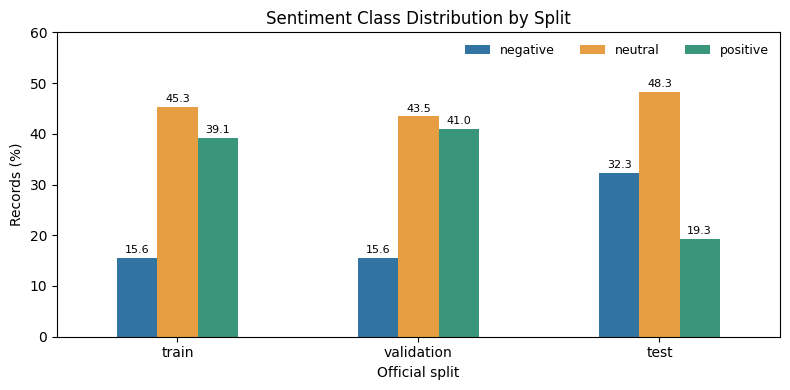

Train/test class-mix comparison:


,sentiment,train_percent,test_percent,test_minus_train_pp,test_train_ratio
0,negative,15.55,32.33,16.78,2.08
1,neutral,45.32,48.33,3.01,1.07
2,positive,39.13,19.33,-19.80,0.49


Notice: at least one class differs by 5 or more percentage points.
The effect on model performance must be measured during final evaluation.
Retain the official test distribution; choose all settings using validation.


In [ ]:
class_counts = pd.DataFrame({
    split: df['label'].value_counts().reindex([0, 1, 2], fill_value=0)
    for split, df in data.items()
}).T.rename(columns=LABEL_NAMES)
class_percent = class_counts.div(class_counts.sum(axis=1), axis=0).mul(100).round(2)
print('Number of records per class:')
display(class_counts)
print('Percentage of records per class:')
display(class_percent)
class_counts.to_csv(OUT / 'checks' / 'class_counts.csv')
class_percent.to_csv(OUT / 'checks' / 'class_percentages.csv')

ax = class_percent.plot.bar(figsize=(8, 4), color=['#3274A1', '#E79D42', '#39967A'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', fontsize=8, padding=2)
ax.set_title('Sentiment Class Distribution by Split')
ax.set_xlabel('Official split')
ax.set_ylabel('Records (%)')
ax.set_ylim(0, 60)
ax.tick_params(axis='x', rotation=0)
ax.legend(ncol=3, loc='upper right', frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(OUT / 'figures' / 'class_distribution.png', dpi=180)
plt.show()

# Percentage-point differences describe the class mix; they do not prove label shift.
class_shift = pd.DataFrame({
    'sentiment': class_percent.columns,
    'train_percent': class_percent.loc['train'].to_numpy(),
    'test_percent': class_percent.loc['test'].to_numpy(),
})
class_shift['test_minus_train_pp'] = (
    class_shift['test_percent'] - class_shift['train_percent']
).round(2)
class_shift['test_train_ratio'] = (
    class_shift['test_percent'] / class_shift['train_percent']
).round(2)
print('Train/test class-mix comparison:')
display(class_shift)
class_shift.to_csv(OUT / 'checks' / 'train_test_class_mix.csv', index=False)
if class_shift['test_minus_train_pp'].abs().max() >= 5:
    print('Notice: at least one class differs by 5 or more percentage points.')
print('The effect on model performance must be measured during final evaluation.')
print('Retain the official test distribution; choose all settings using validation.')


## 9. Inspect Text Length
Compare approximate text lengths and the percentages of short, medium and long posts.


Approximate length: whitespace-separated units, before feature tokenisation.


,min,mean,median,max
train,1.0,19.24,20.0,35.0
validation,4.0,19.44,20.0,31.0
test,1.0,14.86,15.0,32.0


text,1-10 words,11-20 words,>20 words
train,5.0,52.51,42.49
validation,5.1,50.20,44.70
test,24.2,58.18,17.62


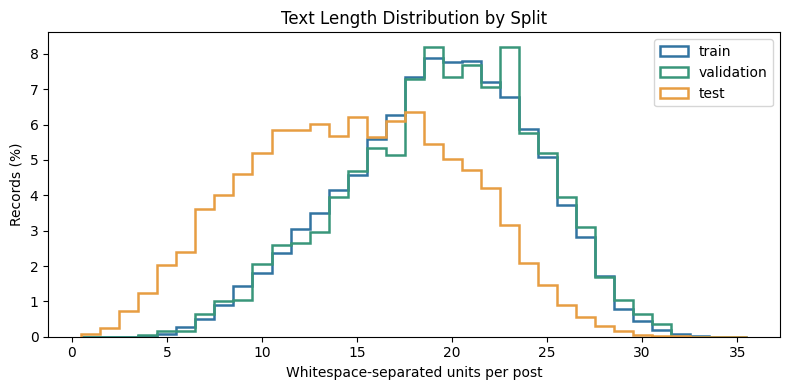

In [ ]:
word_counts = {split: df['text'].str.split().str.len() for split, df in data.items()}
length_statistics = pd.DataFrame({
    split: lengths.describe()[['min', 'mean', '50%', 'max']]
    for split, lengths in word_counts.items()
}).T.rename(columns={'50%': 'median'}).round(2)
length_buckets = pd.DataFrame({
    split: pd.cut(lengths, bins=[0, 10, 20, np.inf],
                  labels=['1-10 words', '11-20 words', '>20 words'])
             .value_counts(normalize=True).mul(100)
    for split, lengths in word_counts.items()
}).T[['1-10 words', '11-20 words', '>20 words']].round(2)
print('Approximate length: whitespace-separated units, before feature tokenisation.')
display(length_statistics)
display(length_buckets)
length_statistics.to_csv(OUT / 'checks' / 'text_length_statistics.csv')
length_buckets.to_csv(OUT / 'checks' / 'text_length_buckets.csv')

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0.5, max(int(x.max()) for x in word_counts.values()) + 1.5)
for split, color in zip(SPLITS, ['#3274A1', '#39967A', '#E79D42']):
    lengths = word_counts[split]
    ax.hist(lengths, bins=bins, weights=np.full(len(lengths), 100 / len(lengths)),
            histtype='step', linewidth=1.8, label=split, color=color)
ax.set_title('Text Length Distribution by Split')
ax.set_xlabel('Whitespace-separated units per post')
ax.set_ylabel('Records (%)')
ax.legend()
plt.tight_layout()
plt.savefig(OUT / 'figures' / 'text_length_distribution.png', dpi=180)
plt.show()


## 10. Inspect Emoji and Format Differences
Count posts containing emoji-like symbols after text repair, using documented Unicode ranges. This is a simple presence check, not full emoji recognition. Save stable row IDs and length groups for later error analysis.


In [ ]:
# This range-based heuristic includes pictographs, flags and common symbol blocks.
# It does not validate complete emoji sequences or presentation selectors.
EMOJI_LIKE = re.compile(r'[\U0001F300-\U0001FAFF\U0001F1E6-\U0001F1FF\u2600-\u27BF]')
format_rows, diagnostic_frames = [], []
for split in SPLITS:
    df = data[split]
    repaired = df['text'].map(repair_text)
    has_emoji = repaired.map(lambda text: bool(EMOJI_LIKE.search(text)))
    count = int(has_emoji.sum())
    format_rows.append({
        'split': split, 'records': len(df),
        'posts_with_emoji_like_symbols': count,
        'emoji_like_percent': round(100 * count / len(df), 2),
    })
    diagnostic = df[['row_id', 'label', 'label_name']].copy()
    diagnostic.insert(0, 'split', split)
    diagnostic['whitespace_length'] = word_counts[split].to_numpy()
    diagnostic['length_group'] = pd.cut(
        word_counts[split], bins=[0, 10, 20, np.inf],
        labels=['1-10', '11-20', '>20'],
    ).astype(str).to_numpy()
    diagnostic['has_emoji_like_symbol'] = has_emoji.to_numpy()
    diagnostic_frames.append(diagnostic)

emoji_checks = pd.DataFrame(format_rows)
record_diagnostics = pd.concat(diagnostic_frames, ignore_index=True)
display(emoji_checks)
emoji_checks.to_csv(OUT / 'checks' / 'emoji_format_checks.csv', index=False)
if emoji_checks.loc[emoji_checks['split'].eq('train'), 'posts_with_emoji_like_symbols'].iloc[0] == 0:
    print('No symbols matched these ranges in training; held-out symbols may be outside the vocabulary.')
print('Percentages are computed from this dataset and detection rule; they are not model scores.')


,split,records,posts_with_emoji_like_symbols,emoji_like_percent
0,train,45615,0,0.00
1,validation,2000,0,0.00
2,test,12284,814,6.63


No symbols matched these ranges in training; held-out symbols may be outside the vocabulary.
Percentages are computed from this dataset and detection rule; they are not model scores.


## 11. Build and Save Numerical Features
Fit four candidates on training only; transform validation and test with the saved vocabulary and IDF. Course link: Lab 1, pp. 16–17, illustrates feature transformation. Select candidate configurations using validation.


In [ ]:
zero_flag_frames = []
vectorizers, feature_rows = {}, []
for name, config in FEATURE_CONFIGS.items():
    folder = OUT / 'features' / name
    folder.mkdir(exist_ok=True)
    vectorizer = make_vectorizer(name)
    X = {'train': vectorizer.fit_transform(data['train']['text']).tocsr()}
    for split in ['validation', 'test']:
        X[split] = vectorizer.transform(data[split]['text']).tocsr()

    row = {'configuration': name, 'vocabulary_size': X['train'].shape[1]}
    for split in SPLITS:
        matrix = X[split]
        labels = data[split]['label'].to_numpy(dtype=np.int64)
        assert matrix.shape == (len(labels), X['train'].shape[1])
        assert np.isfinite(matrix.data).all() and (matrix.data >= 0).all()
        buffer = io.BytesIO()
        sp.save_npz(buffer, matrix)
        matrix_path = folder / f'X_{split}.npz'
        matrix_path.write_bytes(buffer.getvalue())
        restored = sp.load_npz(matrix_path)
        assert restored.shape == matrix.shape and (restored != matrix).nnz == 0
        np.save(folder / f'y_{split}.npy', labels, allow_pickle=False)
        data[split][['row_id']].to_csv(folder / f'row_ids_{split}.csv', index=False)
        row[f'{split}_shape'] = str(matrix.shape)
        zero_flags = np.diff(matrix.indptr) == 0
        row[f'{split}_zero_rows'] = int(zero_flags.sum())
        zero_flag_frames.append(pd.DataFrame({
            'split': split, 'row_id': data[split]['row_id'].to_numpy(),
            'configuration': name, 'all_zero': zero_flags,
        }))

    joblib.dump(vectorizer, folder / 'vectorizer.joblib', compress=3)
    (folder / 'feature_names.json').write_text(
        json.dumps(vectorizer.get_feature_names_out().tolist(), ensure_ascii=False),
        encoding='utf-8',
    )
    vectorizers[name] = vectorizer
    feature_rows.append(row)

feature_checks = pd.DataFrame(feature_rows)
display(feature_checks[['configuration', 'vocabulary_size', 'train_shape', 'validation_shape', 'test_shape']])
print('All-zero feature rows:')
display(feature_checks[['configuration', 'train_zero_rows', 'validation_zero_rows', 'test_zero_rows']])
feature_checks.to_csv(OUT / 'checks' / 'feature_checks.csv', index=False)
print('Four configurations saved. All label and matrix shape checks passed.')
print('min_df=2 and max_features=60000 are starting settings; select settings using validation only.')


,configuration,vocabulary_size,train_shape,validation_shape,test_shape
0,count_unigram,20175,"(45615, 20175)","(2000, 20175)","(12284, 20175)"
1,count_unigram_bigram,60000,"(45615, 60000)","(2000, 60000)","(12284, 60000)"
2,tfidf_unigram,20175,"(45615, 20175)","(2000, 20175)","(12284, 20175)"
3,tfidf_unigram_bigram,60000,"(45615, 60000)","(2000, 60000)","(12284, 60000)"


All-zero feature rows:


,configuration,train_zero_rows,validation_zero_rows,test_zero_rows
0,count_unigram,0,0,5
1,count_unigram_bigram,1,0,7
2,tfidf_unigram,0,0,5
3,tfidf_unigram_bigram,1,0,7


Four configurations saved. All label and matrix shape checks passed.
min_df=2 and max_features=60000 are starting settings; select settings using validation only.


## 12. Check Vocabulary Coverage
Distinguish tokens excluded from the fitted vocabulary from tokens never observed in training. A token can be excluded by min_df or the feature limit even when it appeared in training. Save row-level diagnostics for later error analysis.


In [ ]:
baseline = vectorizers['count_unigram']
vocabulary = baseline.vocabulary_
training_token_counts = Counter(
    token for text in data['train']['text'] for token in tokenize_text(text)
)
seen_training_tokens = set(training_token_counts)
coverage_rows, outside_counts, unseen_counts, token_rows = [], {}, {}, []

for split in SPLITS:
    counts = Counter()
    for record in data[split].itertuples(index=False):
        tokens = tokenize_text(record.text)
        counts.update(tokens)
        outside_n = sum(token not in vocabulary for token in tokens)
        unseen_n = sum(token not in seen_training_tokens for token in tokens)
        token_rows.append({
            'split': split, 'row_id': record.row_id, 'token_count': len(tokens),
            'outside_vocabulary_count': outside_n,
            'unseen_training_count': unseen_n,
            'outside_vocabulary_percent': round(100 * outside_n / max(len(tokens), 1), 2),
        })
    outside = Counter({t: n for t, n in counts.items() if t not in vocabulary})
    unseen = Counter({t: n for t, n in counts.items() if t not in seen_training_tokens})
    total = sum(counts.values())
    coverage_rows.append({
        'split': split, 'tokens_per_record': round(total / len(data[split]), 2),
        'outside_vocabulary_percent': round(100 * sum(outside.values()) / max(total, 1), 2),
        'unseen_training_percent': round(100 * sum(unseen.values()) / max(total, 1), 2),
    })
    outside_counts[split], unseen_counts[split] = outside, unseen

coverage = pd.DataFrame(coverage_rows)
display(coverage)
coverage.to_csv(OUT / 'checks' / 'unigram_vocabulary_coverage.csv', index=False)
assert unseen_counts['train'].total() == 0
for split in SPLITS:
    assert unseen_counts[split].total() <= outside_counts[split].total()

for name, counts in [('outside_vocabulary', outside_counts['validation']),
                     ('unseen_training', unseen_counts['validation'])]:
    table = pd.DataFrame(counts.most_common(15), columns=['token', 'occurrences'])
    print(f'Most frequent validation tokens: {name}')
    display(table)
    table.to_csv(OUT / 'checks' / f'validation_{name}_tokens.csv', index=False)

zero_flags = pd.concat(zero_flag_frames, ignore_index=True).pivot(
    index=['split', 'row_id'], columns='configuration', values='all_zero'
).add_prefix('all_zero_').reset_index()
zero_flags.columns.name = None
record_diagnostics = record_diagnostics.merge(
    pd.DataFrame(token_rows), on=['split', 'row_id'], validate='one_to_one'
).merge(zero_flags, on=['split', 'row_id'], validate='one_to_one')
assert len(record_diagnostics) == sum(len(df) for df in data.values())
assert not record_diagnostics.isna().any().any()
record_diagnostics.to_csv(OUT / 'checks' / 'record_diagnostics.csv', index=False)
print('Row-level diagnostics saved. Test statistics must not guide feature or parameter choices.')


,split,tokens_per_record,outside_vocabulary_percent,unseen_training_percent
0,train,23.11,2.52,0.00
1,validation,23.22,3.56,2.48
2,test,17.93,11.61,8.95


Most frequent validation tokens: outside_vocabulary


,token,occurrences
0,pines,3
1,framed,2
2,generally,2
3,restoration,2
4,centers,2
5,ppl's,2
6,#andy_x9,2
7,114,2
8,susah,2
9,saltalamacchia,2


Most frequent validation tokens: unseen_training


,token,occurrences
0,generally,2
1,restoration,2
2,#andy_x9,2
3,114,2
4,susah,2
5,unheralded,2
6,looting,2
7,#cincodemayo,2
8,diverse,2
9,bricksquad,2


Row-level diagnostics saved. Test statistics must not guide feature or parameter choices.


## 13. Inspect Cases for Error Analysis
Show validation examples with limited vocabulary coverage. Detailed test words, emoji examples and all-zero rows are optional: set SHOW_TEST_EXAMPLES to True only after all model choices are fixed. Flags identify cases to investigate, not proven model errors.


In [ ]:
zero_columns = [f'all_zero_{name}' for name in FEATURE_CONFIGS]
case_counts = record_diagnostics.groupby('split', sort=False)[zero_columns].sum().astype(int)
case_counts['posts_with_emoji_like_symbols'] = record_diagnostics.groupby(
    'split', sort=False
)['has_emoji_like_symbol'].sum().astype(int)
case_counts['at_least_50_percent_outside_vocabulary'] = record_diagnostics.assign(
    flagged=record_diagnostics['outside_vocabulary_percent'].ge(50)
).groupby('split', sort=False)['flagged'].sum().astype(int)
display(case_counts)
case_counts.to_csv(OUT / 'checks' / 'diagnostic_case_counts.csv')

validation_cases = record_diagnostics.loc[record_diagnostics['split'].eq('validation')].nlargest(
    5, 'outside_vocabulary_percent'
).merge(data['validation'][['row_id', 'text']], on='row_id', validate='one_to_one')
columns = ['row_id', 'label_name', 'outside_vocabulary_percent', 'text']
print('Validation examples with the highest outside-vocabulary percentages:')
with pd.option_context('display.max_colwidth', 100):
    display(validation_cases[columns])
validation_cases[columns].to_csv(OUT / 'checks' / 'validation_coverage_examples.csv', index=False)

if SHOW_TEST_EXAMPLES:
    folder = OUT / 'test_diagnostics'
    folder.mkdir(exist_ok=True)
    test_tokens = pd.DataFrame(unseen_counts['test'].most_common(15), columns=['token', 'occurrences'])
    print('Test tokens never observed in training (final analysis only):')
    display(test_tokens)
    test_tokens.to_csv(folder / 'unseen_test_tokens.csv', index=False)
    test_records = record_diagnostics.loc[record_diagnostics['split'].eq('test')].merge(
        data['test'][['row_id', 'text']], on='row_id', validate='one_to_one'
    )
    for name, mask in [
        ('all_zero_unigram', test_records['all_zero_count_unigram']),
        ('emoji_like_symbols', test_records['has_emoji_like_symbol']),
    ]:
        examples = test_records.loc[mask, ['row_id', 'label_name', 'text']].head(5)
        print(f'Test examples: {name}')
        with pd.option_context('display.max_colwidth', 100):
            display(examples)
        examples.to_csv(folder / f'{name}_examples.csv', index=False)
    print('Use these cases to analyse the fixed model; do not revise settings using them.')
else:
    print('Detailed test examples are disabled. Enable them for final error analysis.')


,all_zero_count_unigram,all_zero_count_unigram_bigram,all_zero_tfidf_unigram,all_zero_tfidf_unigram_bigram,posts_with_emoji_like_symbols,at_least_50_percent_outside_vocabulary
split,,,,,,
train,0,1,0,1,0,1
validation,0,0,0,0,0,0
test,5,7,5,7,814,280


Validation examples with the highest outside-vocabulary percentages:


,row_id,label_name,outside_vocabulary_percent,text
0,validation_000181,negative,45.45,"""Kapan sih lo ngebuktiin,jan ngomong doang Susah Susah.usaha Aja blm udh nyerah,inget.if you nev..."
1,validation_001354,positive,41.18,@user One Alanis Morissette Sun is Shining Bob Marley Wake the Town URoy Reckoner Radiohead V...
2,validation_000311,positive,37.50,Twitter overhauls iPad app with responsive design #July
3,validation_001461,positive,35.90,"""Tum Kya Samajhty Ho Choro Gay To Mar Jayen Gay hum, .H!NA 1 Bat Kahun Tum Se Jee to wo b rahy..."
4,validation_001775,neutral,35.71,"""fanwars between Kpop fandoms will always happen kahit anong pigil natin. Pero at the end pag ma..."


Detailed test examples are disabled. Enable them for final error analysis.


## 14. Show Real Examples and Verify Reloading
Show two training examples per class, including their tokens and numerical features, and verify saved feature conversion.


In [ ]:
example_vectorizer = vectorizers['count_unigram']
names = example_vectorizer.get_feature_names_out()
picked = data['train'].groupby('label', group_keys=False).sample(2, random_state=SEED).sort_values('label')
example_records = []

for _, record in picked.iterrows():
    tokens = tokenize_text(record['text'])
    matrix = example_vectorizer.transform([record['text']]).tocsr()
    active = {names[i]: int(value) for i, value in zip(matrix.indices, matrix.data)}
    missing_tokens = sorted(set(tokens) - set(vocabulary))
    print(f"\n{record['row_id']} | {record['label_name']}")
    print('Original :', record['text'])
    print('Processed:', normalise_text(record['text']))
    print('Tokens   :', tokens)
    print('First 12 non-zero count features:', dict(list(active.items())[:12]))
    print('Tokens outside the vocabulary:', missing_tokens)
    example_records.append({
        'row_id': record['row_id'], 'label_name': record['label_name'],
        'original': record['text'], 'processed': normalise_text(record['text']),
        'tokens': tokens, 'count_features': active, 'outside_vocabulary': missing_tokens,
    })

(OUT / 'checks' / 'processing_examples.json').write_text(
    json.dumps(example_records, ensure_ascii=False, indent=2), encoding='utf-8'
)

new_text = "I don't like this update!"
reload_rows = []
for name, original in vectorizers.items():
    loaded = joblib.load(OUT / 'features' / name / 'vectorizer.joblib')
    before = original.transform([new_text]).tocsr()
    after = loaded.transform([new_text]).tocsr()
    assert (before != after).nnz == 0
    reload_rows.append({'configuration': name, 'new_text_shape': str(after.shape), 'reload_check': 'passed'})

print('\nNew input:', new_text)
display(pd.DataFrame(reload_rows))



train_004939 | negative
Original : "#CNET - Just bought my 1st iPad, iPad3, feeling real burned, mad, about iPad4 so soon. Grrr. REALLY mad! Don't even care about mini now,"
Processed: "#cnet - just bought my 1st ipad, ipad3, feeling real burned, mad, about ipad4 so soon. grrr. really mad! don't even care about mini now,"
Tokens   : ['"', '#cnet', '-', 'just', 'bought', 'my', '1st', 'ipad', ',', 'ipad3', ',', 'feeling', 'real', 'burned', ',', 'mad', ',', 'about', 'ipad4', 'so', 'soon', '.', 'grrr', '.', 'really', 'mad', '!', "don't", 'even', 'care', 'about', 'mini', 'now', ',', '"']
First 12 non-zero count features: {'!': 1, '"': 2, ',': 5, '-': 1, '.': 2, '1st': 1, 'about': 2, 'bought': 1, 'burned': 1, 'care': 1, "don't": 1, 'even': 1}
Tokens outside the vocabulary: ['#cnet', 'grrr']

train_015545 | negative
Original : "Mother's Day is coming like tomorrow or is it today? idk, but i didn't prepare anything for me's mom."
Processed: "mother's day is coming like tomorrow or is it today

,configuration,new_text_shape,reload_check
0,count_unigram,"(1, 20175)",passed
1,count_unigram_bigram,"(1, 60000)",passed
2,tfidf_unigram,"(1, 20175)",passed
3,tfidf_unigram_bigram,"(1, 60000)",passed


## 15. Save Preparation Metadata
Save the dataset revision, processing settings, library versions and file documentation for reproducible loading.


In [ ]:
versions = {name: importlib.metadata.version(name) for name in [
    'datasets', 'huggingface_hub', 'numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib', 'matplotlib'
]}
metadata = {
    'dataset_id': DATASET_ID, 'configuration': DATASET_CONFIG,
    'source_url': DATASET_URL, 'revision': DATA_REVISION,
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'labels': LABEL_NAMES, 'split_rows': {s: len(data[s]) for s in SPLITS},
    'split_policy': 'Original split membership, labels and row order retained.',
    'duplicate_check': 'Repair escapes and HTML, then ignore case and extra whitespace.',
    'duplicate_policy': 'Retain and document repeated rows and label conflicts.',
    'feature_fit_data': 'Training only; all other records use transform only.',
    'feature_configurations': FEATURE_CONFIGS, 'min_df': 2, 'max_features': 60000,
    'seed_for_examples': SEED, 'package_versions': versions,
    'test_examples_included': SHOW_TEST_EXAMPLES,
    'diagnostic_method': {
        'outside_vocabulary': 'Token absent from the fitted count_unigram vocabulary; includes pruned training tokens.',
        'unseen_training': 'Token not observed in any training text under the shared tokenizer.',
        'emoji_like_ranges': 'U+1F300–U+1FAFF, U+1F1E6–U+1F1FF, U+2600–U+27BF; presence heuristic after repair.',
        'case_flags': 'Diagnostic cases, not observed classification errors.',
    },
    'course_links': {
        'feature_extractor': 'Lecture 2, PDF p.12; Lab 1, PDF pp.16–17.',
        'class_prior': 'Lecture 7, PDF p.5: Bayes theorem.',
    },
    'data_sha256': {s: hashlib.sha256((OUT / 'data' / f'{s}.csv').read_bytes()).hexdigest() for s in SPLITS},
    'module_sha256': hashlib.sha256((OUT / 'text_features.py').read_bytes()).hexdigest(),
}
(OUT / 'metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
(OUT / 'requirements_used.txt').write_text(
    '\n'.join(f'{name}=={version}' for name, version in versions.items()) + '\n', encoding='utf-8'
)

readme = """# How to Use the Prepared Files

Source: https://huggingface.co/datasets/cardiffnlp/tweet_eval/tree/main/sentiment
Labels: 0 negative, 1 neutral, 2 positive.
The original rows and splits are retained. See metadata.json for the fixed revision.

data/: original text, labels and row IDs for each split.
features/{configuration}/: sparse matrices, labels, row IDs and a fitted vectorizer.
text_features.py: shared processing functions, required when loading vectorizers.
checks/: data-quality tables, feature checks, coverage and examples.
figures/: class and text-length plots.
requirements_used.txt: library versions used to create the files.

MODEL TRAINING: train on training data; choose feature and model settings using validation.
The four feature configurations are candidates, not ranked or selected models.
Save the chosen classifier with the SAME configuration's fitted vectorizer.
Do not fit the vectorizer on validation or test records.

FINAL EVALUATION: after settings are fixed, use the corresponding test matrix and labels.
Match predictions to the original records using row_ids_test.csv or data/test.csv.
Keep records with all-zero feature rows and document their effect.
Define a majority-class baseline using TRAINING labels.
Test statistics must not guide preprocessing, feature or parameter selection.

Loading example (change ROOT to your prepared-data folder):

    from pathlib import Path
    import sys, joblib, numpy as np
    from scipy.sparse import load_npz

    ROOT = Path('/content/drive/MyDrive/CSCI323/TweetEval_Prepared')
    sys.path.insert(0, str(ROOT))
    import text_features

    folder = ROOT / 'features' / 'count_unigram'
    X_train = load_npz(folder / 'X_train.npz')
    y_train = np.load(folder / 'y_train.npy', allow_pickle=False)
    X_val = load_npz(folder / 'X_validation.npz')
    y_val = np.load(folder / 'y_validation.npy', allow_pickle=False)

    vectorizer = joblib.load(folder / 'vectorizer.joblib')
    X_new = vectorizer.transform(["I don't like this update!"])

Pass raw input to transform; the saved vectorizer applies the processing itself.
For repeatable loading, use compatible versions from requirements_used.txt.

Reference: Barbieri et al. (2020), TweetEval: Unified Benchmark and Comparative
Evaluation for Tweet Classification.
https://aclanthology.org/2020.findings-emnlp.148/
"""
readme += '''
ADDITIONAL DIAGNOSTICS
checks/train_test_class_mix.csv: class percentages, differences and ratios.
checks/emoji_format_checks.csv: symbol-presence counts under the documented heuristic.
checks/record_diagnostics.csv: one row per post, joined by split and row_id.
Includes length group, emoji flag, token counts, coverage and all-zero flags.
Outside-vocabulary includes terms excluded by min_df or the feature limit.
Unseen-training refers only to tokens absent from every training record.
checks/diagnostic_case_counts.csv: counts of flagged cases; these are not model errors.
Detailed test words/examples are excluded by default. To generate them for final
error analysis, set SHOW_TEST_EXAMPLES=True after all model choices are fixed.
The optional test_diagnostics/ folder are generated only when that flag is True.
No negation-versus-bigram performance finding is copied from another notebook.
Run any such comparison using the same processing pipeline on validation.
'''
(OUT / 'README.md').write_text(readme, encoding='utf-8')

print('Prepared files saved to:', OUT)

Handoff ready: TweetEval_Prepared_Files.zip
Files packaged: 72
ZIP size: 27.1 MiB
Training and validation features are ready. See README.md for the loading example.


# Part 2: Model Training and Validation
Train and tune Multinomial NBC, Logistic Regression and Linear SVM on the training split, select each model on validation and save the three final pipelines. The test set is not used in this part.

## 16. Set Up the Experiment Plan
Set the paths, fixed settings and declared search grid. Set `PREPARED_DIR` only when resuming without re-running Part 1 in the same session.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import hashlib
import importlib.metadata
import io
import json
import shutil
import subprocess
import sys
import textwrap
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import load_npz
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support,
    recall_score,
)
from sklearn.naive_bayes import MultinomialNB

PREPARED_DIR = None  # Example: "/content/drive/MyDrive/CSCI323/TweetEval_Prepared"
FEATURES = ["count_unigram", "count_unigram_bigram", "tfidf_unigram", "tfidf_unigram_bigram"]
INITIAL_ALPHAS = [0.1, 0.5, 1.0]
EXTENDED_ALPHAS = [0.001, 0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0]
PRIOR_SETTINGS = [True, False]
CLASS_LABELS = [0, 1, 2]
CLASS_NAMES = ["negative", "neutral", "positive"]
LABEL_MAPPING = dict(zip(CLASS_LABELS, CLASS_NAMES))
DATASET_REVISION = "b3a375baf0f409c77e6bc7aa35102b7b3534f8be"
SELECTION_RULE = (
    "Validation Macro Recall descending; Macro F1 descending; exact ties: "
    "feature name ascending, alpha ascending, fit_prior=True before False."
)
EXPECTED_CANDIDATES = len(FEATURES) * len(EXTENDED_ALPHAS) * len(PRIOR_SETTINGS)
assert EXPECTED_CANDIDATES == 64
PACKAGES = ["datasets", "huggingface_hub", "numpy", "pandas", "scipy", "scikit-learn", "joblib", "matplotlib"]
runtime_versions = {name: importlib.metadata.version(name) for name in PACKAGES}
print("Python:", sys.version.split()[0])
display(pd.DataFrame(runtime_versions.items(), columns=["Package", "Version"]))
print("Initial candidates: 12; new candidates: 52; total unique candidates: 64.")
print("Selection:", SELECTION_RULE)


Python: 3.13.18


,Package,Version
0,datasets,4.8.5
1,huggingface_hub,1.33.0
2,numpy,2.1.3
3,pandas,2.2.3
4,scipy,1.16.3
5,scikit-learn,1.6.1
6,joblib,1.6.0
7,matplotlib,3.10.0


Initial candidates: 12; new candidates: 52; total unique candidates: 64.
Selection: Validation Macro Recall descending; Macro F1 descending; exact ties: feature name ascending, alpha ascending, fit_prior=True before False.


## 17. Load the Prepared Data
Verify the prepared files, the text-processing module and the training/validation CSVs. The prepared data is read only and never changed.

In [ ]:
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

if PREPARED_DIR is not None:
    ROOT = Path(PREPARED_DIR).expanduser().resolve()
elif "OUT" in globals():
    ROOT = Path(OUT).resolve()
else:
    raise RuntimeError("Run Part 1 first or set PREPARED_DIR in Step 16 to the extracted prepared-data folder.")
for name in ["metadata.json", "text_features.py", "README.md"]:
    assert (ROOT / name).is_file(), f"Missing prepared-data file: {ROOT / name}"

source_metadata = json.loads((ROOT / "metadata.json").read_text(encoding="utf-8"))
assert source_metadata["dataset_id"] == "cardiffnlp/tweet_eval"
assert source_metadata["configuration"] == "sentiment"
assert source_metadata["revision"] == DATASET_REVISION
assert source_metadata["labels"] == {str(k): v for k, v in LABEL_MAPPING.items()}
assert sha256_file(ROOT / "text_features.py") == source_metadata["module_sha256"]
source_package_versions = source_metadata.get("package_versions", {})
version_mismatches = {
    package: {
        "prepared_data": source_package_versions.get(package),
        "runtime": runtime_versions.get(package),
    }
    for package in PACKAGES
    if source_package_versions.get(package) != runtime_versions.get(package)
}
assert not version_mismatches, (
    "Package versions do not match the prepared-data metadata: "
    f"{version_mismatches}. Run the setup cell, restart the runtime, and rerun from the beginning."
)

b_data = {}
for split, expected_rows in [("train", 45615), ("validation", 2000)]:
    path = ROOT / "data" / f"{split}.csv"
    assert sha256_file(path) == source_metadata["data_sha256"][split]
    frame = pd.read_csv(path, keep_default_na=False)
    assert len(frame) == expected_rows and frame["row_id"].is_unique
    assert np.array_equal(frame["row_id"].to_numpy(), [f"{split}_{i:06d}" for i in range(expected_rows)])
    assert set(frame["label"].unique()) == set(CLASS_LABELS)
    assert frame["text"].map(lambda value: isinstance(value, str)).all()
    b_data[split] = frame
y_train = b_data["train"]["label"].to_numpy()
y_val = b_data["validation"]["label"].to_numpy()

OUTPUT_DIR = ROOT.parent / "TweetEval_GroupB_ThreeMethods_NBC_Work"
assert OUTPUT_DIR.resolve() != ROOT and ROOT not in OUTPUT_DIR.resolve().parents
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Prepared data:", ROOT)
print("Separate model output folder:", OUTPUT_DIR)
display(pd.DataFrame([
    {"Split": split, "Rows": len(frame)} for split, frame in b_data.items()
]))
print("Prepared-data source revision, module, CSV hashes, labels and row IDs verified.")


Prepared data: /content/drive/MyDrive/CSCI323/TweetEval_Prepared
Separate B output: /content/drive/MyDrive/CSCI323/TweetEval_GroupB_ThreeMethods_NBC_Work


,Split,Rows
0,train,45615
1,validation,2000


A's source revision, module, CSV hashes, labels and row IDs verified.


## 18. Feature and Evaluation Helpers
Define one loading function and one metric function used for every candidate model. All-zero rows are kept.

In [ ]:
b_input_checks = {}

def load_feature_pair(feature_name):
    assert feature_name in FEATURES
    folder = ROOT / "features" / feature_name
    matrices = {}
    for split, expected_labels in [("train", y_train), ("validation", y_val)]:
        matrix = load_npz(folder / f"X_{split}.npz").tocsr()
        labels = np.load(folder / f"y_{split}.npy", allow_pickle=False)
        ids = pd.read_csv(folder / f"row_ids_{split}.csv", keep_default_na=False)["row_id"].to_numpy()
        assert matrix.shape[0] == len(expected_labels)
        assert np.array_equal(labels, expected_labels)
        assert np.array_equal(ids, b_data[split]["row_id"].to_numpy())
        assert np.isfinite(matrix.data).all() and (matrix.data >= 0).all()
        matrices[split] = matrix
        b_input_checks[(feature_name, split)] = {
            "Feature": feature_name, "Split": split, "Rows": matrix.shape[0],
            "Columns": matrix.shape[1], "All-zero rows": int((matrix.getnnz(axis=1) == 0).sum()),
        }
    assert matrices["train"].shape[1] == matrices["validation"].shape[1]
    return matrices["train"], matrices["validation"]

def evaluate_predictions(true_labels, predicted_labels):
    assert len(true_labels) == len(predicted_labels)
    assert set(np.unique(predicted_labels)).issubset(CLASS_LABELS)
    precision, recall, f1, support = precision_recall_fscore_support(
        true_labels, predicted_labels, labels=CLASS_LABELS, zero_division=0
    )
    metrics = {
        "Macro Recall": recall_score(true_labels, predicted_labels, labels=CLASS_LABELS, average="macro", zero_division=0),
        "Macro F1": f1_score(true_labels, predicted_labels, labels=CLASS_LABELS, average="macro", zero_division=0),
        "Accuracy": accuracy_score(true_labels, predicted_labels),
    }
    for index, name in enumerate(CLASS_NAMES):
        metrics.update({
            f"{name}_precision": float(precision[index]), f"{name}_recall": float(recall[index]),
            f"{name}_f1": float(f1[index]), f"{name}_support": int(support[index]),
            f"{name}_predicted_count": int(np.sum(predicted_labels == CLASS_LABELS[index])),
        })
    return metrics

def fit_candidate(feature, alpha, fit_prior, train_matrix, validation_matrix, stage):
    classifier = MultinomialNB(alpha=float(alpha), fit_prior=bool(fit_prior))
    started = perf_counter()
    classifier.fit(train_matrix, y_train)
    fit_seconds = perf_counter() - started
    predictions = classifier.predict(validation_matrix)
    row = {
        "Feature": feature, "Alpha": float(alpha), "Fit Prior": bool(fit_prior),
        "Stage": stage, "Feature Count": train_matrix.shape[1], "Fit Seconds": fit_seconds,
        **evaluate_predictions(y_val, predictions),
    }
    return row, classifier, predictions

def rank_candidates(frame):
    return frame.sort_values(
        ["Macro Recall", "Macro F1", "Feature", "Alpha", "Fit Prior"],
        ascending=[False, False, True, True, False],
    ).reset_index(drop=True)

SCORE_COLUMNS = ["Macro Recall", "Macro F1", "Accuracy"]
candidate_rows = {}
print("Shared loading, metric and ranking functions ready.")


Shared loading, metric and ranking functions ready.


## 19. Majority-Class Baseline
Fit a baseline that always predicts the most common training class. It is a reference point only and cannot be selected as a model.

In [ ]:
majority_classifier = DummyClassifier(strategy="most_frequent")
majority_classifier.fit(np.zeros((len(y_train), 1)), y_train)
majority_val_pred = majority_classifier.predict(np.zeros((len(y_val), 1)))
majority_label = int(majority_classifier.predict([[0]])[0])
majority_metrics = evaluate_predictions(y_val, majority_val_pred)
print("Training-majority class:", LABEL_MAPPING[majority_label])
display(pd.DataFrame([majority_metrics])[SCORE_COLUMNS].round(4))


Training-majority class: neutral


,Macro Recall,Macro F1,Accuracy
0,0.3333,0.2019,0.4345


## 20. Initial Twelve NBC Experiments
Train NBC on the four feature sets with α ∈ {0.1, 0.5, 1.0} and learned class priors. These results are reused in the larger search.

In [ ]:
for feature in FEATURES:
    train_matrix, validation_matrix = load_feature_pair(feature)
    for alpha in INITIAL_ALPHAS:
        row, classifier, predictions = fit_candidate(
            feature, alpha, True, train_matrix, validation_matrix, "initial"
        )
        candidate_rows[(feature, float(alpha), True)] = row
        if feature == "count_unigram" and alpha == 1.0:
            baseline_val_pred = predictions.copy()
            baseline_metrics = evaluate_predictions(y_val, baseline_val_pred)
    print("Initial experiments completed:", feature)
del train_matrix, validation_matrix, classifier, predictions
initial_results_df = rank_candidates(pd.DataFrame(candidate_rows.values()))
assert len(initial_results_df) == 12
display(initial_results_df[["Feature", "Alpha", "Fit Prior"] + SCORE_COLUMNS].round(4))


Initial experiments completed: count_unigram
Initial experiments completed: count_unigram_bigram
Initial experiments completed: tfidf_unigram
Initial experiments completed: tfidf_unigram_bigram


,Feature,Alpha,Fit Prior,Macro Recall,Macro F1,Accuracy
0,count_unigram_bigram,0.5,True,0.6371,0.6111,0.6290
1,count_unigram_bigram,1.0,True,0.6245,0.6081,0.6310
2,count_unigram_bigram,0.1,True,0.6212,0.6024,0.6235
3,count_unigram,0.5,True,0.6177,0.6029,0.6250
4,count_unigram,1.0,True,0.6155,0.6061,0.6300
5,count_unigram,0.1,True,0.6110,0.5959,0.6185
6,tfidf_unigram_bigram,0.1,True,0.5889,0.6014,0.6475
7,tfidf_unigram,0.1,True,0.5515,0.5639,0.6295
8,tfidf_unigram_bigram,0.5,True,0.5382,0.5381,0.6425
9,tfidf_unigram,0.5,True,0.5315,0.5338,0.6315


## 21. Verify the Original NBC Results
Compare the new scores with the embedded full-precision reference scores. Any mismatch stops the run for investigation.

In [ ]:
ORIGINAL_RESULTS_CSV = 'Feature,Alpha,Macro Recall,Macro F1,Accuracy\ncount_unigram_bigram,0.5,0.6371498871498872,0.6111166513296116,0.629\ncount_unigram_bigram,1.0,0.6244674804801388,0.6081048229952906,0.631\ncount_unigram_bigram,0.1,0.621195318980129,0.6024255012757241,0.6235\ncount_unigram,0.5,0.6177398550816272,0.6029137391059184,0.625\ncount_unigram,1.0,0.6155062120251994,0.6061270121298931,0.63\ncount_unigram,0.1,0.611009009743187,0.59589873747741,0.6185\ntfidf_unigram_bigram,0.1,0.5889325746920683,0.6013814398507171,0.6475\ntfidf_unigram,0.1,0.5514893568691037,0.5639306155749847,0.6295\ntfidf_unigram_bigram,0.5,0.5381972692099275,0.5381259385229011,0.6425\ntfidf_unigram,0.5,0.5314615646894127,0.533836293277393,0.6315\ntfidf_unigram,1.0,0.5126200569238544,0.49766584149043314,0.6295\ntfidf_unigram_bigram,1.0,0.5076036246922323,0.4789434966626673,0.635\n'
previous_results = pd.read_csv(io.StringIO(ORIGINAL_RESULTS_CSV))
initial_keys = ["Feature", "Alpha"]
current_initial = initial_results_df.set_index(initial_keys).sort_index()
previous_initial = previous_results.set_index(initial_keys).sort_index()
assert current_initial.index.equals(previous_initial.index)
np.testing.assert_allclose(current_initial[SCORE_COLUMNS], previous_initial[SCORE_COLUMNS], rtol=0, atol=1e-12)
initial_results_df.to_csv(OUTPUT_DIR / "initial_validation_results.csv", index=False)
print("All 12 original validation results reproduced.")


All 12 original validation results reproduced.


## 22. Extended NBC Search: 64 Configurations
Compare eight α values and both prior settings. The 12 earlier results are reused, so only 52 new models are trained; the grid is not extended after seeing the results.

In [ ]:
new_candidate_count = 0
for feature in FEATURES:
    train_matrix, validation_matrix = load_feature_pair(feature)
    for alpha in EXTENDED_ALPHAS:
        for fit_prior in PRIOR_SETTINGS:
            key = (feature, float(alpha), bool(fit_prior))
            if key in candidate_rows:
                continue
            row, classifier, predictions = fit_candidate(
                feature, alpha, fit_prior, train_matrix, validation_matrix, "extended"
            )
            candidate_rows[key] = row
            new_candidate_count += 1
    print("Complete:", feature, "— 16 unique configurations")
del train_matrix, validation_matrix, classifier, predictions

expected_grid = {(f, float(a), bool(p)) for f in FEATURES for a in EXTENDED_ALPHAS for p in PRIOR_SETTINGS}
assert set(candidate_rows) == expected_grid
assert new_candidate_count == 52
results_df = rank_candidates(pd.DataFrame(candidate_rows.values()))
assert len(results_df) == EXPECTED_CANDIDATES
assert not results_df.duplicated(["Feature", "Alpha", "Fit Prior"]).any()
assert np.isfinite(results_df[SCORE_COLUMNS].to_numpy()).all()
results_df.to_csv(OUTPUT_DIR / "validation_results.csv", index=False)
pd.DataFrame(b_input_checks.values()).to_csv(OUTPUT_DIR / "input_checks.csv", index=False)
print("Total unique candidates:", len(results_df), "| Newly trained:", new_candidate_count)
display(results_df[["Feature", "Alpha", "Fit Prior"] + SCORE_COLUMNS].head(12).round(4))
print("The complete 64-row table, including per-class metrics, is saved in validation_results.csv.")


Complete: count_unigram — 16 unique configurations
Complete: count_unigram_bigram — 16 unique configurations
Complete: tfidf_unigram — 16 unique configurations
Complete: tfidf_unigram_bigram — 16 unique configurations
Total unique candidates: 64 | Newly trained: 52


,Feature,Alpha,Fit Prior,Macro Recall,Macro F1,Accuracy
0,count_unigram_bigram,0.50,True,0.6371,0.6111,0.6290
1,count_unigram_bigram,1.00,False,0.6340,0.6067,0.6265
2,count_unigram_bigram,0.50,False,0.6336,0.6004,0.6190
3,tfidf_unigram_bigram,0.10,False,0.6334,0.6028,0.6215
4,count_unigram_bigram,0.25,True,0.6320,0.6065,0.6250
5,tfidf_unigram_bigram,0.25,False,0.6305,0.6046,0.6255
6,tfidf_unigram_bigram,0.05,False,0.6301,0.6015,0.6200
7,count_unigram_bigram,0.25,False,0.6280,0.5958,0.6145
8,count_unigram_bigram,0.10,False,0.6260,0.5980,0.6165
9,count_unigram,0.50,False,0.6252,0.5886,0.6055


The complete 64-row table, including per-class metrics, is saved in validation_results.csv.


## 23. Compare NBC Settings on Validation
Plot validation scores against α for each feature and prior setting (logarithmic axis). These are validation scores only.

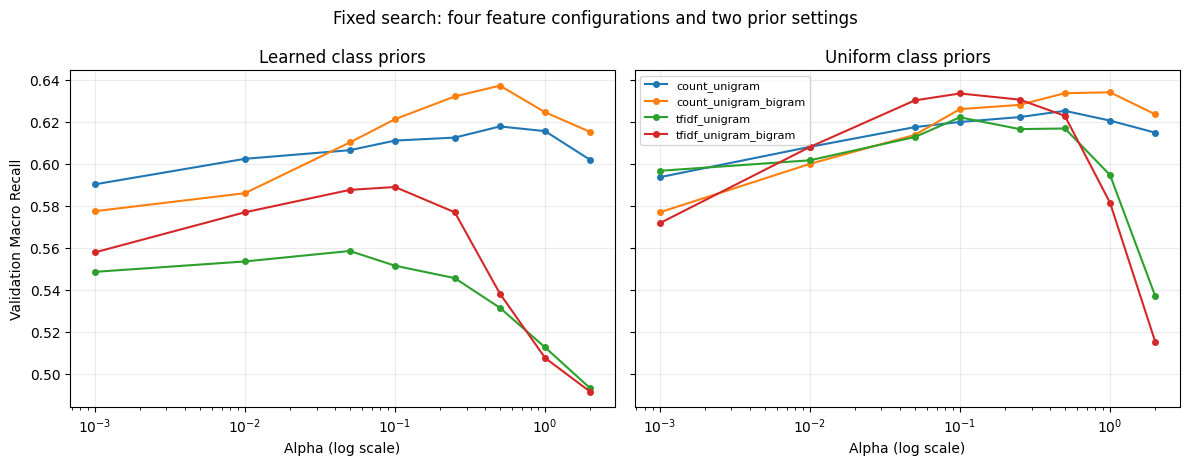

,Feature,Alpha,Fit Prior,Macro Recall,Macro F1,Accuracy
0,count_unigram_bigram,0.5,True,0.6371,0.6111,0.6290
3,tfidf_unigram_bigram,0.1,False,0.6334,0.6028,0.6215
9,count_unigram,0.5,False,0.6252,0.5886,0.6055
14,tfidf_unigram,0.1,False,0.6221,0.5862,0.6010


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), sharey=True)
for ax, fit_prior in zip(axes, PRIOR_SETTINGS):
    for feature in FEATURES:
        part = results_df[(results_df["Feature"] == feature) & (results_df["Fit Prior"] == fit_prior)].sort_values("Alpha")
        ax.plot(part["Alpha"], part["Macro Recall"], marker="o", markersize=4, label=feature)
    ax.set_xscale("log")
    ax.set_xlabel("Alpha (log scale)")
    ax.set_title("Learned class priors" if fit_prior else "Uniform class priors")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Validation Macro Recall")
axes[1].legend(fontsize=8, loc="best")
fig.suptitle("Fixed search: four feature configurations and two prior settings")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_search.png", dpi=160, bbox_inches="tight")
plt.show()

best_by_feature = results_df.drop_duplicates("Feature").copy()
display(best_by_feature[["Feature", "Alpha", "Fit Prior"] + SCORE_COLUMNS].round(4))
best_by_feature.to_csv(OUTPUT_DIR / "best_by_feature.csv", index=False)


## 24. Fit and Verify the Selected NBC
Refit the top-ranked NBC on the training split only and reproduce its validation scores. Training and validation data are never combined.

In [ ]:
best_row = results_df.iloc[0]
best_feature = str(best_row["Feature"])
best_alpha = float(best_row["Alpha"])
best_fit_prior = bool(best_row["Fit Prior"])
best_X_train, best_X_val = load_feature_pair(best_feature)
best_model = MultinomialNB(alpha=best_alpha, fit_prior=best_fit_prior)
best_model.fit(best_X_train, y_train)
best_val_pred = best_model.predict(best_X_val)
best_metrics = evaluate_predictions(y_val, best_val_pred)
np.testing.assert_allclose([best_metrics[k] for k in SCORE_COLUMNS], best_row[SCORE_COLUMNS].to_numpy(dtype=float), rtol=0, atol=1e-12)

comparison_df = pd.DataFrame([
    {"Model": "Training-majority baseline", **{k: majority_metrics[k] for k in SCORE_COLUMNS}},
    {"Model": "Count Unigram NB baseline (alpha=1.0, fit_prior=True)", **{k: baseline_metrics[k] for k in SCORE_COLUMNS}},
    {"Model": "Best of original 12", **{k: float(initial_results_df.iloc[0][k]) for k in SCORE_COLUMNS}},
    {"Model": "Selected NBC (64 candidates)", **{k: best_metrics[k] for k in SCORE_COLUMNS}},
])
comparison_df.to_csv(OUTPUT_DIR / "baseline_comparison.csv", index=False)
print("Selected feature:", best_feature)
print("Selected alpha:", best_alpha, "| fit_prior:", best_fit_prior)
display(comparison_df.round(4))
delta = best_metrics["Macro Recall"] - float(initial_results_df.iloc[0]["Macro Recall"])
print(f"Validation Macro Recall change from the previous selected NBC: {100 * delta:+.2f} percentage points.")


Selected feature: count_unigram_bigram
Selected alpha: 0.5 | fit_prior: True


,Model,Macro Recall,Macro F1,Accuracy
0,Training-majority baseline,0.3333,0.2019,0.4345
1,"Count Unigram NB baseline (alpha=1.0, fit_prio...",0.6155,0.6061,0.6300
2,Best of original 12,0.6371,0.6111,0.6290
3,Selected NBC (64 candidates),0.6371,0.6111,0.6290


Validation Macro Recall change from the previous selected NBC: +0.00 percentage points.


## 25. Selected NBC Validation Report
Show precision, recall and F1 for all three classes. These describe the validation set used for selection, not final test results.

              precision    recall  f1-score   support

    negative     0.4421    0.6603    0.5296       312
     neutral     0.6714    0.5455    0.6019       869
    positive     0.6981    0.7057    0.7019       819

    accuracy                         0.6290      2000
   macro avg     0.6038    0.6371    0.6111      2000
weighted avg     0.6465    0.6290    0.6316      2000



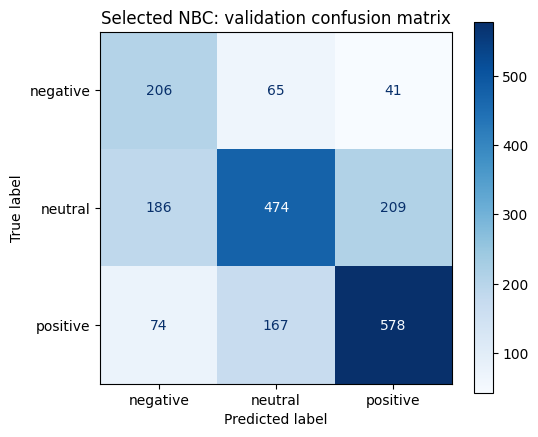

,Feature,Alpha,Fit Prior,negative_precision,negative_recall,negative_f1,negative_predicted_count,neutral_precision,neutral_recall,neutral_f1,neutral_predicted_count,positive_precision,positive_recall,positive_f1,positive_predicted_count
0,count_unigram_bigram,0.50,True,0.4421,0.6603,0.5296,466,0.6714,0.5455,0.6019,706,0.6981,0.7057,0.7019,828
1,count_unigram_bigram,1.00,False,0.4259,0.6538,0.5158,479,0.6763,0.5362,0.5982,689,0.7007,0.7118,0.7062,832
2,count_unigram_bigram,0.50,False,0.4077,0.6795,0.5096,520,0.6772,0.5167,0.5862,663,0.7062,0.7045,0.7054,817
3,tfidf_unigram_bigram,0.10,False,0.4147,0.6699,0.5123,504,0.6672,0.5259,0.5882,685,0.7115,0.7045,0.7080,811
4,count_unigram_bigram,0.25,True,0.4356,0.6506,0.5219,466,0.6620,0.5409,0.5953,710,0.7002,0.7045,0.7024,824


In [ ]:
selected_report = classification_report(
    y_val, best_val_pred, labels=CLASS_LABELS, target_names=CLASS_NAMES,
    digits=4, zero_division=0,
)
print(selected_report)
(OUTPUT_DIR / "selected_validation_report.txt").write_text(selected_report, encoding="utf-8")
report_data = classification_report(
    y_val, best_val_pred, labels=CLASS_LABELS, target_names=CLASS_NAMES,
    output_dict=True, zero_division=0,
)
pd.DataFrame(report_data).T.to_csv(OUTPUT_DIR / "selected_validation_report.csv", index_label="Class_or_average")
selected_cm = confusion_matrix(y_val, best_val_pred, labels=CLASS_LABELS)
pd.DataFrame(selected_cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    OUTPUT_DIR / "selected_validation_confusion_matrix.csv", index_label="True_label"
)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ConfusionMatrixDisplay(selected_cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("Selected NBC: validation confusion matrix")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "selected_validation_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

per_class_columns = [f"{name}_{metric}" for name in CLASS_NAMES for metric in ["precision", "recall", "f1", "predicted_count"]]
display(results_df[["Feature", "Alpha", "Fit Prior"] + per_class_columns].head(5).round(4))


### 25a. Validation Error Analysis
Export the validation mistakes with row IDs for qualitative review. Patterns such as negation or sarcasm are hypotheses to inspect, not proven causes; test predictions are not used here.

In [ ]:
# Validation-only error analysis; the test split is not loaded or used here.
validation_errors = b_data["validation"][["row_id", "text", "label"]].copy()
validation_errors["predicted_label"] = np.asarray(best_val_pred, dtype=int)
validation_errors["true_sentiment"] = validation_errors["label"].map(LABEL_MAPPING)
validation_errors["predicted_sentiment"] = validation_errors["predicted_label"].map(LABEL_MAPPING)
validation_errors = validation_errors.loc[
    validation_errors["label"] != validation_errors["predicted_label"]
].copy()
validation_errors = validation_errors[[
    "row_id", "text", "label", "true_sentiment",
    "predicted_label", "predicted_sentiment",
]]
validation_errors.to_csv(OUTPUT_DIR / "validation_errors.csv", index=False)

validation_error_summary = (
    validation_errors.groupby(
        ["label", "true_sentiment", "predicted_label", "predicted_sentiment"],
        as_index=False,
    )
    .size()
    .rename(columns={"size": "count"})
    .sort_values(["count", "label", "predicted_label"], ascending=[False, True, True])
)
validation_error_summary.to_csv(OUTPUT_DIR / "validation_error_summary.csv", index=False)
print(
    f"Validation misclassifications: {len(validation_errors)} / {len(b_data['validation'])} "
    f"({len(validation_errors) / len(b_data['validation']):.1%})."
)
print("Most frequent true-to-predicted error pairs:")
display(validation_error_summary.head(10))
print("Saved validation_errors.csv and validation_error_summary.csv. These are validation-only diagnostics.")

Validation misclassifications: 742 / 2000 (37.1%).
Most frequent true-to-predicted error pairs:


,label,true_sentiment,predicted_label,predicted_sentiment,count
3,1,neutral,2,positive,209
2,1,neutral,0,negative,186
5,2,positive,1,neutral,167
4,2,positive,0,negative,74
0,0,negative,1,neutral,65
1,0,negative,2,positive,41


Saved validation_errors.csv and validation_error_summary.csv. These are validation-only diagnostics.


### 25b. Metric Interpretation
Macro Recall is the main selection metric, Macro F1 breaks ties and accuracy is supplementary, so the selected model need not have the highest accuracy. The selected configuration is frozen before any test evaluation.

## 26. Verify the Matching Vectorizer
Load the vectorizer for the selected feature set and check its validation transformation without refitting it.

In [ ]:
# Avoid writing an import cache into the prepared-data folder.
sys.dont_write_bytecode = True
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import text_features
assert Path(text_features.__file__).resolve() == (ROOT / "text_features.py").resolve(), (
    "A different text_features module is loaded. Restart and run this notebook in order."
)
best_vectorizer = joblib.load(ROOT / "features" / best_feature / "vectorizer.joblib")
transformed_validation = best_vectorizer.transform(b_data["validation"]["text"])
assert transformed_validation.shape == best_X_val.shape
assert (transformed_validation != best_X_val).nnz == 0
assert len(best_vectorizer.vocabulary_) == best_model.n_features_in_
np.testing.assert_array_equal(best_model.predict(transformed_validation), best_val_pred)
print("The saved vectorizer reproduces the selected validation features and all predictions.")


A's vectorizer reproduces the selected validation features and all predictions.


## 27. Boundary and Prediction Checks
Use synthetic inputs to check pipeline behaviour, not sentiment accuracy. An all-zero vector is decided by the class prior; tied scores follow the classifier's class order.

In [ ]:
unseen_token = "zzztweetevalunseenwordqzx"
while best_vectorizer.transform([unseen_token]).nnz:
    unseen_token += "qzx"
repeat_token = "good" if "good" in best_vectorizer.vocabulary_ else next(
    word for word in best_vectorizer.get_feature_names_out() if word.isalpha()
)
boundary_inputs = [
    ("Empty text", ""), ("Whitespace only", "   "), ("Unseen token", unseen_token),
    ("Repeated token", " ".join([repeat_token] * 3)),
    ("Demonstration A", "I love this update!"),
    ("Demonstration A repeated", "I love this update!"),
    ("Demonstration B", "The meeting starts at three."),
    ("Demonstration C", "This service is terrible."),
]
boundary_texts = [text for _, text in boundary_inputs]
boundary_X = best_vectorizer.transform(boundary_texts)
boundary_pred = best_model.predict(boundary_X)
assert boundary_X[:3].nnz == 0
expected_zero_class = best_model.classes_[np.argmax(best_model.class_log_prior_)]
assert np.all(boundary_pred[:3] == expected_zero_class)
assert (boundary_X[4] != boundary_X[5]).nnz == 0 and boundary_pred[4] == boundary_pred[5]
individually_predicted = [int(best_model.predict(best_vectorizer.transform([text]))[0]) for text in boundary_texts]
np.testing.assert_array_equal(boundary_pred, individually_predicted)
if best_feature.startswith("count_"):
    assert boundary_X[3, best_vectorizer.vocabulary_[repeat_token]] == 3
assert np.isfinite(best_model.predict_log_proba(boundary_X)).all()
boundary_df = pd.DataFrame({
    "Case": [name for name, _ in boundary_inputs], "Text": boundary_texts,
    "Nonzero features": boundary_X.getnnz(axis=1),
    "Predicted label": boundary_pred,
    "Predicted sentiment": [LABEL_MAPPING[int(label)] for label in boundary_pred],
})
boundary_df.to_csv(OUTPUT_DIR / "boundary_checks.csv", index=False)
display(boundary_df)
print("Zero-vector, repeated-input, batch/single prediction and finite-score checks passed.")


,Case,Text,Nonzero features,Predicted label,Predicted sentiment
0,Empty text,,0,1,neutral
1,Whitespace only,,0,1,neutral
2,Unseen token,zzztweetevalunseenwordqzx,0,1,neutral
3,Repeated token,good good good,1,2,positive
4,Demonstration A,I love this update!,7,2,positive
5,Demonstration A repeated,I love this update!,7,2,positive
6,Demonstration B,The meeting starts at three.,9,1,neutral
7,Demonstration C,This service is terrible.,7,0,negative


Zero-vector, repeated-input, batch/single prediction and finite-score checks passed.


## 28. Save the NBC Model and Configuration
Save the selected classifier together with its matching vectorizer, and record both α and the prior setting.

In [ ]:
model_bundle = {
    "classifier": best_model, "vectorizer": best_vectorizer,
    "feature_configuration": best_feature, "alpha": best_alpha,
    "fit_prior": best_fit_prior, "label_mapping": LABEL_MAPPING,
}
joblib.dump(model_bundle, OUTPUT_DIR / "nbc_model_bundle.joblib", compress=3)
shutil.copy2(ROOT / "text_features.py", OUTPUT_DIR / "text_features.py")
shutil.copy2(ROOT / "metadata.json", OUTPUT_DIR / "group_a_metadata.json")
assert sha256_file(OUTPUT_DIR / "text_features.py") == source_metadata["module_sha256"]
assert sha256_file(OUTPUT_DIR / "group_a_metadata.json") == sha256_file(ROOT / "metadata.json")

selected_config = {
    "dataset_id": source_metadata["dataset_id"], "dataset_revision": DATASET_REVISION,
    "feature_configuration": best_feature, "classifier": "MultinomialNB",
    "model_parameters": best_model.get_params(), "label_mapping": LABEL_MAPPING,
    "selection_rule": SELECTION_RULE, "candidate_count": int(len(results_df)),
    "initial_candidate_count": 12, "new_candidate_count": new_candidate_count,
    "search_grid": {"features": FEATURES, "alpha": EXTENDED_ALPHAS, "fit_prior": PRIOR_SETTINGS},
    "validation_metrics": {name: float(best_metrics[name]) for name in SCORE_COLUMNS},
    "trained_on": "Official training split only", "test_used_for_selection": False,
    "test_evaluated_by_group_b": False, "python_version": sys.version.split()[0],
    "package_versions": runtime_versions,
    "source_training_csv_sha256": source_metadata["data_sha256"]["train"],
    "source_validation_csv_sha256": source_metadata["data_sha256"]["validation"],
    "source_module_sha256": source_metadata["module_sha256"],
    "created_utc": datetime.now(timezone.utc).isoformat(),
}
(OUTPUT_DIR / "selected_config.json").write_text(json.dumps(selected_config, indent=2), encoding="utf-8")
(OUTPUT_DIR / "requirements.txt").write_text(
    "\n".join(f"{name}=={runtime_versions[name]}" for name in PACKAGES) + "\n", encoding="utf-8"
)
validation_predictions = b_data["validation"][["row_id", "label"]].rename(columns={"label": "true_label"}).copy()
validation_predictions["predicted_label"] = best_val_pred
validation_predictions.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)
majority_record = {"training_majority_label": majority_label, "training_majority_name": LABEL_MAPPING[majority_label],
                   "validation_metrics": majority_metrics}
(OUTPUT_DIR / "majority_baseline.json").write_text(json.dumps(majority_record, indent=2), encoding="utf-8")
print("Selected model, matching vectorizer, validation records and environment saved.")


Selected model, matching vectorizer, validation records and environment saved.


## 29. Verify Reloading in a Fresh Process
Load the saved NBC bundle in a separate Python process and confirm that every validation prediction is reproduced.

In [ ]:
reload_script = textwrap.dedent("""
    from pathlib import Path
    import sys, json
    import numpy as np
    import pandas as pd
    import joblib
    sys.dont_write_bytecode = True
    b_dir, validation_csv = map(Path, sys.argv[1:3])
    sys.path.insert(0, str(b_dir))
    import text_features
    assert Path(text_features.__file__).resolve() == (b_dir / "text_features.py").resolve()
    bundle = joblib.load(b_dir / "nbc_model_bundle.joblib")
    config = json.loads((b_dir / "selected_config.json").read_text(encoding="utf-8"))
    frame = pd.read_csv(validation_csv, keep_default_na=False)
    saved = pd.read_csv(b_dir / "validation_predictions.csv", keep_default_na=False)
    np.testing.assert_array_equal(frame["row_id"], saved["row_id"])
    np.testing.assert_array_equal(frame["label"], saved["true_label"])
    assert bundle["classifier"].get_params() == config["model_parameters"]
    assert bundle["feature_configuration"] == config["feature_configuration"]
    pred = bundle["classifier"].predict(bundle["vectorizer"].transform(frame["text"]))
    np.testing.assert_array_equal(pred, saved["predicted_label"])
    print(json.dumps({"status": "passed", "validation_rows": len(frame), "fresh_process": True}))
""")
reload_workdir = OUTPUT_DIR / "_fresh_process_work"
reload_workdir.mkdir(exist_ok=True)
reload_result = subprocess.run(
    [sys.executable, "-X", "utf8", "-c", reload_script,
     str(OUTPUT_DIR.resolve()), str((ROOT / "data" / "validation.csv").resolve())],
    cwd=reload_workdir, capture_output=True, text=True, encoding="utf-8", timeout=180,
)
if reload_result.returncode != 0:
    raise RuntimeError(f"Fresh-process reload failed:\n{reload_result.stdout}\n{reload_result.stderr}")
verification = json.loads(reload_result.stdout.strip())
validation_errors_check = pd.read_csv(OUTPUT_DIR / "validation_errors.csv", keep_default_na=False)
validation_error_summary_check = pd.read_csv(OUTPUT_DIR / "validation_error_summary.csv")
validation_row_ids = set(b_data["validation"]["row_id"])
assert set(validation_errors_check["row_id"]).issubset(validation_row_ids)
assert (validation_errors_check["label"] != validation_errors_check["predicted_label"]).all()
assert int(validation_error_summary_check["count"].sum()) == len(validation_errors_check)
verification.update({
    "initial_12_results_reproduced": True, "unique_candidates": len(results_df),
    "boundary_checks": "passed", "input_alignment": "passed",
    "validation_error_rows": int(len(validation_errors_check)),
    "validation_error_summary_pairs": int(len(validation_error_summary_check)),
    "validation_error_exports": "passed", "test_evaluated": False,
    "checked_utc": datetime.now(timezone.utc).isoformat(),
})
(OUTPUT_DIR / "verification.json").write_text(json.dumps(verification, indent=2), encoding="utf-8")
print("Fresh-process reload passed:", verification["validation_rows"], "matching validation predictions.")


Fresh-process reload passed: 2000 matching validation predictions.


## 30. Save the Intermediate NBC Package
Archive the NBC results as an intermediate record. The final package with all three models is created in Step 39.

In [ ]:
readme = f"""TweetEval Group B: optimized handoff

SELECTED CONFIGURATION
Classifier: MultinomialNB
Feature: {best_feature}
Alpha: {best_alpha}
fit_prior: {best_fit_prior}
Labels: 0=negative, 1=neutral, 2=positive
Trained on the official training split only.

VALIDATION-ONLY SELECTION
{SELECTION_RULE}
64 unique candidates: 4 features x 8 alpha values x 2 prior settings.
The original 12 results are retained; 52 additional candidates were evaluated.
Macro Recall: {best_metrics['Macro Recall']:.12f}
Macro F1: {best_metrics['Macro F1']:.12f}
Accuracy: {best_metrics['Accuracy']:.12f}
These are validation scores, not final test scores.

INPUT DEPENDENCY
Use the original A prepared-data package or run Part A in the integrated notebook.
Dataset revision: {DATASET_REVISION}
A's preprocessing, original splits and rows are unchanged.

LOAD THE UPDATED MODEL
Install the recorded B library versions from requirements.txt.
Set B_DIR to this extracted ZIP folder. Keep text_features.py beside the model bundle.

    from pathlib import Path
    import sys, joblib
    B_DIR = Path("/content/TweetEval_GroupB_ThreeMethods_NBC_Work")
    sys.path.insert(0, str(B_DIR))
    import text_features
    bundle = joblib.load(B_DIR / "nbc_model_bundle.joblib")
    texts = ["I love this update!"]
    pred = bundle["classifier"].predict(bundle["vectorizer"].transform(texts))
    print([bundle["label_mapping"][int(label)] for label in pred])

GROUP C: FINAL TEST EVALUATION
Use this updated bundle; do not assume the original alpha=0.5 configuration is still selected.
Use A's features/{best_feature}/X_test.npz, y_test.npy and row_ids_test.csv.
Verify row correspondence with data/test.csv and retain all rows, including all-zero rows.
Apply the saved classifier to the matching matrix. Do not refit or tune on test results.
Report Macro Recall, Macro F1, Accuracy, per-class metrics, confusion matrix and errors.
A majority baseline must use training labels; majority_baseline.json records that choice.
Append C's evaluation after the notebook's final Group C boundary.

RECORDS
initial_validation_results.csv: original 12 experiments with per-class metrics.
validation_results.csv: all 64 unique experiments with per-class metrics.
baseline_comparison.csv: majority, original baseline, original winner and new selection.
validation_predictions.csv: selected-model validation predictions with stable row IDs.
validation_errors.csv: validation-only misclassified examples with row IDs, text and labels.
validation_error_summary.csv: counts for each true-to-predicted validation error pair.
selected_config.json: full grid, selected parameters, versions and selection rule.
selected_validation_report.* and selected_validation_confusion_matrix.*: validation only.
boundary_checks.csv: synthetic pipeline checks, not a labeled evaluation dataset.
verification.json: alignment, original-result and fresh-process checks.
manifest_sha256.json: integrity hashes of the package contents.

Theory, report writing and slides are maintained separately.
Group B has not performed final test evaluation.
"""
(OUTPUT_DIR / "README.txt").write_text(textwrap.dedent(readme), encoding="utf-8")
handoff_files = [
    "README.txt", "nbc_model_bundle.joblib", "text_features.py", "requirements.txt",
    "selected_config.json", "group_a_metadata.json", "input_checks.csv",
    "initial_validation_results.csv", "validation_results.csv", "best_by_feature.csv",
    "baseline_comparison.csv", "majority_baseline.json", "validation_search.png",
    "validation_predictions.csv", "validation_errors.csv", "validation_error_summary.csv",
    "selected_validation_report.txt", "selected_validation_report.csv",
    "selected_validation_confusion_matrix.csv", "selected_validation_confusion_matrix.png",
    "boundary_checks.csv", "verification.json",
]
assert all((OUTPUT_DIR / name).is_file() for name in handoff_files)
manifest = {name: sha256_file(OUTPUT_DIR / name) for name in handoff_files}
(OUTPUT_DIR / "manifest_sha256.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
handoff_files.append("manifest_sha256.json")
zip_path = OUTPUT_DIR.parent / "TweetEval_GroupB_ThreeMethods_NBC_Intermediate.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in handoff_files:
        archive.write(OUTPUT_DIR / name, arcname=name)
with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None
    for name, digest in manifest.items():
        assert hashlib.sha256(archive.read(name)).hexdigest() == digest
print("Intermediate NBC ZIP verified:", zip_path)
print("Included files:", len(handoff_files))
print("Selected configuration:", best_feature, "| alpha =", best_alpha, "| fit_prior =", best_fit_prior)
print("Intermediate NBC archive only. Continue to Step 39 for the final three-model ZIP.")


Updated handoff ZIP verified: /content/drive/MyDrive/CSCI323/TweetEval_GroupB_ThreeMethods_NBC_Intermediate.zip
Included files: 23
Selected configuration: count_unigram_bigram | alpha = 0.5 | fit_prior = True
Intermediate NBC archive only. Continue to B24 for the final three-method ZIP.


## Research Basis for the Three Methods
The three model families follow Pang, Lee and Vaithyanathan (2002), *Thumbs up? Sentiment Classification using Machine Learning Techniques* ([DOI: 10.3115/1118693.1118704](https://doi.org/10.3115/1118693.1118704)), adapted from binary movie reviews to three-class tweets; the paper's ranking is not assumed to hold here. Course links: NBC – Lecture 7, p. 5 (Bayes' theorem); Logistic Regression – Lab 1, pp. 13 and 31 (classification and cross-entropy); Linear SVM – Lecture 2, p. 22 (scores and margins).

## 31. Declare the Three-Method Protocol
Reuse the four feature sets. Logistic Regression and Linear SVM each search C ∈ {0.1, 1, 10} with no class re-weighting, giving 88 configurations in total (64 NBC + 12 LR + 12 SVM). A convergence warning only raises the iteration cap; a final failure stops the run.

In [ ]:
import warnings
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

METHOD_IDS = ["multinomial_nb", "logistic_regression", "linear_svm"]
METHOD_NAMES = {
    "multinomial_nb": "Multinomial NBC",
    "logistic_regression": "Logistic Regression",
    "linear_svm": "Linear SVM",
}
C_VALUES = [0.1, 1.0, 10.0]
ITERATION_CAPS = {"logistic_regression": [1500, 4500], "linear_svm": [10000, 30000]}
OPTIMISER_TOLERANCE = 1e-4
EXPERIMENT_SEED = 42
THREAD_LIMIT = 2
MULTI_OUTPUT_DIR = ROOT.parent / "TweetEval_GroupB_ThreeMethods_Output"
assert ROOT not in MULTI_OUTPUT_DIR.resolve().parents
assert MULTI_OUTPUT_DIR.resolve() not in [ROOT, OUTPUT_DIR.resolve()]
MULTI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fit_attempts = []
method_winners = {}


def make_linear_estimator(method_id, c_value, iteration_cap):
    common = dict(C=float(c_value), penalty="l2", class_weight=None,
                  tol=OPTIMISER_TOLERANCE, max_iter=int(iteration_cap),
                  random_state=EXPERIMENT_SEED, fit_intercept=True)
    if method_id == "logistic_regression":
        return LogisticRegression(solver="lbfgs", **common)
    if method_id == "linear_svm":
        return LinearSVC(loss="squared_hinge", multi_class="ovr", dual=False, **common)
    raise ValueError(f"Unknown linear method: {method_id}")


def rank_linear_candidates(frame):
    return frame.sort_values(
        ["Macro Recall", "Macro F1", "Feature", "C"],
        ascending=[False, False, True, True],
    ).reset_index(drop=True)


def run_linear_search(method_id):
    rows = []
    best_rank = None
    for feature in FEATURES:
        train_matrix, validation_matrix = load_feature_pair(feature)
        for c_value in C_VALUES:
            total_fit_seconds = 0.0
            for attempt_number, cap in enumerate(ITERATION_CAPS[method_id], start=1):
                estimator = make_linear_estimator(method_id, c_value, cap)
                with threadpool_limits(limits=THREAD_LIMIT), warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always", ConvergenceWarning)
                    started = perf_counter()
                    estimator.fit(train_matrix, y_train)
                    elapsed = perf_counter() - started
                total_fit_seconds += elapsed
                convergence_messages = [str(w.message) for w in caught
                                        if issubclass(w.category, ConvergenceWarning)]
                other_messages = [str(w.message) for w in caught
                                  if not issubclass(w.category, ConvergenceWarning)]
                fit_attempts.append({
                    "Method": method_id, "Feature": feature, "C": float(c_value),
                    "Attempt": attempt_number, "Iteration Cap": cap,
                    "Iterations": int(np.max(estimator.n_iter_)), "Fit Seconds": elapsed,
                    "Converged": not convergence_messages,
                    "Convergence Messages": " | ".join(convergence_messages),
                    "Other Warnings": " | ".join(other_messages),
                })
                if not convergence_messages:
                    break
                print(f"Convergence retry: {method_id}, {feature}, C={c_value}, cap={cap}", flush=True)
            else:
                pd.DataFrame(fit_attempts).to_csv(MULTI_OUTPUT_DIR / "linear_fit_attempts.csv", index=False)
                raise RuntimeError(
                    f"{method_id}, {feature}, C={c_value} did not converge under the declared caps. "
                    "Inspect linear_fit_attempts.csv before freezing this experiment."
                )
            with threadpool_limits(limits=THREAD_LIMIT):
                predicted = estimator.predict(validation_matrix)
            row = {
                "Method": method_id, "Feature": feature, "C": float(c_value),
                "Feature Count": train_matrix.shape[1], "Fit Seconds": total_fit_seconds,
                "Iterations": int(np.max(estimator.n_iter_)), "Iteration Cap": cap,
                "Fit Attempts": attempt_number, "Converged": True,
                "Model Parameters": json.dumps(estimator.get_params(), sort_keys=True),
                **evaluate_predictions(y_val, predicted),
            }
            rows.append(row)
            rank_key = (-row["Macro Recall"], -row["Macro F1"], feature, float(c_value))
            if best_rank is None or rank_key < best_rank:
                best_rank = rank_key
                method_winners[method_id] = {
                    "feature": feature, "parameters": estimator.get_params(),
                    "validation_predictions": predicted.copy(), "row": row.copy(),
                }
            pd.DataFrame(fit_attempts).to_csv(MULTI_OUTPUT_DIR / "linear_fit_attempts.csv", index=False)
            print(f"{method_id}: {feature}, C={c_value} | Macro Recall={row['Macro Recall']:.4f}", flush=True)
    frame = rank_linear_candidates(pd.DataFrame(rows))
    assert len(frame) == len(FEATURES) * len(C_VALUES) == 12
    assert not frame.duplicated(["Method", "Feature", "C"]).any()
    assert frame["Converged"].all()
    frame.to_csv(MULTI_OUTPUT_DIR / f"{method_id}_validation_results.csv", index=False)
    pd.DataFrame(fit_attempts).to_csv(MULTI_OUTPUT_DIR / "linear_fit_attempts.csv", index=False)
    return frame


print("Declared methods:", ", ".join(METHOD_NAMES.values()))
print("Candidate counts: NBC=64, LR=12, Linear SVM=12; total=88.")
print("Linear SVM uses the deterministic primal solver (dual=False) for the same squared-hinge objective.")
print("Shared validation selection: Macro Recall, then Macro F1; exact linear ties: feature name, then C ascending.")
print("All selected models remain trained on the official training split only.")


Declared methods: Multinomial NBC, Logistic Regression, Linear SVM
Candidate counts: NBC=64, LR=12, Linear SVM=12; total=88.
Linear SVM uses the deterministic primal solver (dual=False) for the same squared-hinge objective.
Shared validation selection: Macro Recall, then Macro F1; exact linear ties: feature name, then C ascending.
All selected models remain trained on the official training split only.


## 32. Train and Validate Logistic Regression
Fit multinomial Logistic Regression on the training split and evaluate all 12 feature/C combinations on validation, saving per-class metrics, convergence and timing records.

In [ ]:
lr_results_df = run_linear_search("logistic_regression")
display(lr_results_df[["Feature", "C", "Converged"] + SCORE_COLUMNS].round(4))


logistic_regression: count_unigram, C=0.1 | Macro Recall=0.6205
logistic_regression: count_unigram, C=1.0 | Macro Recall=0.6345
logistic_regression: count_unigram, C=10.0 | Macro Recall=0.6048
logistic_regression: count_unigram_bigram, C=0.1 | Macro Recall=0.6461
logistic_regression: count_unigram_bigram, C=1.0 | Macro Recall=0.6395
logistic_regression: count_unigram_bigram, C=10.0 | Macro Recall=0.6297
logistic_regression: tfidf_unigram, C=0.1 | Macro Recall=0.5235
logistic_regression: tfidf_unigram, C=1.0 | Macro Recall=0.6257
logistic_regression: tfidf_unigram, C=10.0 | Macro Recall=0.6313
logistic_regression: tfidf_unigram_bigram, C=0.1 | Macro Recall=0.4899
logistic_regression: tfidf_unigram_bigram, C=1.0 | Macro Recall=0.6200
logistic_regression: tfidf_unigram_bigram, C=10.0 | Macro Recall=0.6345


,Feature,C,Converged,Macro Recall,Macro F1,Accuracy
0,count_unigram_bigram,0.1,True,0.6461,0.6615,0.6985
1,count_unigram_bigram,1.0,True,0.6395,0.6475,0.6775
2,tfidf_unigram_bigram,10.0,True,0.6345,0.6435,0.6765
3,count_unigram,1.0,True,0.6345,0.6427,0.6720
4,tfidf_unigram,10.0,True,0.6313,0.6392,0.6695
5,count_unigram_bigram,10.0,True,0.6297,0.6354,0.6625
6,tfidf_unigram,1.0,True,0.6257,0.6414,0.6865
7,count_unigram,0.1,True,0.6205,0.6345,0.6815
8,tfidf_unigram_bigram,1.0,True,0.6200,0.6376,0.6835
9,count_unigram,10.0,True,0.6048,0.6057,0.6330


## 33. Train and Validate Linear SVM
Fit one-vs-rest Linear SVM on the same data and grid, using the primal solver (`dual=False`) for the squared-hinge loss. Its decision scores are not probabilities.

In [ ]:
svm_results_df = run_linear_search("linear_svm")
display(svm_results_df[["Feature", "C", "Converged"] + SCORE_COLUMNS].round(4))


linear_svm: count_unigram, C=0.1 | Macro Recall=0.6421
linear_svm: count_unigram, C=1.0 | Macro Recall=0.6144
linear_svm: count_unigram, C=10.0 | Macro Recall=0.5732
linear_svm: count_unigram_bigram, C=0.1 | Macro Recall=0.6337
linear_svm: count_unigram_bigram, C=1.0 | Macro Recall=0.6091
linear_svm: count_unigram_bigram, C=10.0 | Macro Recall=0.6017
linear_svm: tfidf_unigram, C=0.1 | Macro Recall=0.6079
linear_svm: tfidf_unigram, C=1.0 | Macro Recall=0.6407
linear_svm: tfidf_unigram, C=10.0 | Macro Recall=0.6056
linear_svm: tfidf_unigram_bigram, C=0.1 | Macro Recall=0.5960
linear_svm: tfidf_unigram_bigram, C=1.0 | Macro Recall=0.6370
linear_svm: tfidf_unigram_bigram, C=10.0 | Macro Recall=0.6119


,Feature,C,Converged,Macro Recall,Macro F1,Accuracy
0,count_unigram,0.1,True,0.6421,0.6542,0.6870
1,tfidf_unigram,1.0,True,0.6407,0.6511,0.6850
2,tfidf_unigram_bigram,1.0,True,0.6370,0.6476,0.6805
3,count_unigram_bigram,0.1,True,0.6337,0.6414,0.6710
4,count_unigram,1.0,True,0.6144,0.6190,0.6470
5,tfidf_unigram_bigram,10.0,True,0.6119,0.6162,0.6440
6,count_unigram_bigram,1.0,True,0.6091,0.6152,0.6440
7,tfidf_unigram,0.1,True,0.6079,0.6253,0.6820
8,tfidf_unigram,10.0,True,0.6056,0.6081,0.6340
9,count_unigram_bigram,10.0,True,0.6017,0.6061,0.6320


## 34. Compare All Three Methods on Validation
Keep each method's best configuration and also compare the methods within each feature set. Rankings use Macro Recall first and Macro F1 second.

In [ ]:
nb_results_df = results_df.copy()
nb_results_df.insert(0, "Method", "multinomial_nb")
nb_results_df["Converged"] = True
nb_results_df["Model Parameters"] = [
    json.dumps(MultinomialNB(alpha=float(row["Alpha"]), fit_prior=bool(row["Fit Prior"])).get_params(), sort_keys=True)
    for _, row in nb_results_df.iterrows()
]
all_methods_results = pd.concat([nb_results_df, lr_results_df, svm_results_df], ignore_index=True)
assert all_methods_results.groupby("Method").size().to_dict() == {
    "linear_svm": 12, "logistic_regression": 12, "multinomial_nb": 64,
}
assert len(all_methods_results) == 88
assert np.isfinite(all_methods_results[SCORE_COLUMNS].to_numpy()).all()
assert not all_methods_results.duplicated(["Method", "Feature", "Model Parameters"]).any()
all_methods_results.to_csv(MULTI_OUTPUT_DIR / "all_methods_validation_results.csv", index=False)

method_winners["multinomial_nb"] = {
    "feature": best_feature, "parameters": best_model.get_params(),
    "validation_predictions": best_val_pred.copy(), "row": nb_results_df.iloc[0].to_dict(),
}
selected_rows = []
matched_rows = []
for method_id in METHOD_IDS:
    winner = method_winners[method_id]
    selected_rows.append({
        "Method": method_id, "Display Name": METHOD_NAMES[method_id],
        "Feature": winner["feature"], "Candidate Count": 64 if method_id == "multinomial_nb" else 12,
        "Model Parameters": json.dumps(winner["parameters"], sort_keys=True),
        **{metric: float(winner["row"][metric]) for metric in SCORE_COLUMNS},
    })
    frame = {"multinomial_nb": nb_results_df, "logistic_regression": lr_results_df,
             "linear_svm": svm_results_df}[method_id]
    for feature in FEATURES:
        row = frame.loc[frame["Feature"] == feature].iloc[0]
        matched_rows.append({"Method": method_id, "Feature": feature,
                             "Model Parameters": row["Model Parameters"],
                             **{metric: float(row[metric]) for metric in SCORE_COLUMNS}})
selected_methods_df = pd.DataFrame(selected_rows)
matched_feature_df = pd.DataFrame(matched_rows)
selected_methods_df.to_csv(MULTI_OUTPUT_DIR / "selected_methods_validation.csv", index=False)
matched_feature_df.to_csv(MULTI_OUTPUT_DIR / "matched_feature_validation.csv", index=False)
display(selected_methods_df[["Display Name", "Feature", "Candidate Count"] + SCORE_COLUMNS].round(4))
print("Best validation Macro Recall per method within the same feature representation:")
display(matched_feature_df.pivot(index="Feature", columns="Method", values="Macro Recall").round(4))
print("NBC has a larger historical search budget; compare both tables and disclose that limitation.")
print("All three selected methods are exported, regardless of their ranking.")


,Display Name,Feature,Candidate Count,Macro Recall,Macro F1,Accuracy
0,Multinomial NBC,count_unigram_bigram,64,0.6371,0.6111,0.6290
1,Logistic Regression,count_unigram_bigram,12,0.6461,0.6615,0.6985
2,Linear SVM,count_unigram,12,0.6421,0.6542,0.6870


Best validation Macro Recall per method within the same feature representation:


Method,linear_svm,logistic_regression,multinomial_nb
Feature,,,
count_unigram,0.6421,0.6345,0.6252
count_unigram_bigram,0.6337,0.6461,0.6371
tfidf_unigram,0.6407,0.6313,0.6221
tfidf_unigram_bigram,0.6370,0.6345,0.6334


NBC has a larger historical search budget; compare both tables and disclose that limitation.
All three selected methods are exported, regardless of their ranking.


## 35. Refit, Verify and Export the Three Selected Models
Refit each selected configuration on the training split, confirm its validation predictions and label order, and record fit and prediction times (descriptive only).

In [ ]:
selected_bundles = {}
selected_predictions = {}
export_registry = {}
selected_refit_rows = []
for method_id in METHOD_IDS:
    winner = method_winners[method_id]
    feature = winner["feature"]
    train_matrix, validation_matrix = load_feature_pair(feature)
    if method_id == "multinomial_nb":
        estimator = MultinomialNB(**winner["parameters"])
    elif method_id == "logistic_regression":
        estimator = LogisticRegression(**winner["parameters"])
    else:
        estimator = LinearSVC(**winner["parameters"])
    with threadpool_limits(limits=THREAD_LIMIT), warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        started = perf_counter()
        estimator.fit(train_matrix, y_train)
        selected_fit_seconds = perf_counter() - started
        predicted = estimator.predict(validation_matrix)
        prediction_times = []
        for _ in range(5):
            started = perf_counter()
            timed_prediction = estimator.predict(validation_matrix)
            prediction_times.append(perf_counter() - started)
            np.testing.assert_array_equal(timed_prediction, predicted)
    assert not any(issubclass(w.category, ConvergenceWarning) for w in caught), method_id
    np.testing.assert_array_equal(estimator.classes_, CLASS_LABELS)
    np.testing.assert_array_equal(predicted, winner["validation_predictions"])
    vectorizer = joblib.load(ROOT / "features" / feature / "vectorizer.joblib")
    reproduced_matrix = vectorizer.transform(b_data["validation"]["text"])
    assert reproduced_matrix.shape == validation_matrix.shape
    assert (reproduced_matrix != validation_matrix).nnz == 0
    assert estimator.n_features_in_ == len(vectorizer.vocabulary_)
    np.testing.assert_array_equal(estimator.predict(reproduced_matrix), predicted)
    bundle = {
        "classifier": estimator, "vectorizer": vectorizer, "method_id": method_id,
        "feature_configuration": feature, "model_parameters": estimator.get_params(),
        "label_mapping": LABEL_MAPPING, "trained_on": "Official training split only",
    }
    model_file = f"{method_id}_bundle.joblib"
    joblib.dump(bundle, MULTI_OUTPUT_DIR / model_file, compress=3)
    selected_bundles[method_id] = bundle
    selected_predictions[method_id] = predicted.copy()
    frame = b_data["validation"][["row_id", "label"]].rename(columns={"label": "true_label"}).copy()
    frame["predicted_label"] = predicted
    prediction_file = f"{method_id}_validation_predictions.csv"
    frame.to_csv(MULTI_OUTPUT_DIR / prediction_file, index=False)
    scores = evaluate_predictions(y_val, predicted)
    for metric in SCORE_COLUMNS:
        np.testing.assert_allclose(scores[metric], winner["row"][metric], rtol=0, atol=1e-12)
    export_registry[method_id] = {
        "display_name": METHOD_NAMES[method_id], "bundle_file": model_file,
        "validation_predictions_file": prediction_file,
        "feature_configuration": feature, "model_parameters": estimator.get_params(),
        "validation_metrics": {metric: float(scores[metric]) for metric in SCORE_COLUMNS},
        "candidate_count": 64 if method_id == "multinomial_nb" else 12,
        "bundle_sha256": sha256_file(MULTI_OUTPUT_DIR / model_file),
    }
    selected_refit_rows.append({
        "Method": method_id, "Feature": feature, "Training Rows": len(y_train),
        "Validation Rows": len(y_val), "Feature Count": train_matrix.shape[1],
        "Selected Refit Seconds": selected_fit_seconds,
        "Validation Predict Seconds Median Of Five": float(np.median(prediction_times)),
        "Bundle Bytes Including Vectorizer": (MULTI_OUTPUT_DIR / model_file).stat().st_size,
        "Thread Limit": THREAD_LIMIT,
    })
    print("Verified and exported:", METHOD_NAMES[method_id], "|", feature)
pd.DataFrame(selected_refit_rows).to_csv(MULTI_OUTPUT_DIR / "selected_runtime_and_size.csv", index=False)
display(pd.DataFrame(selected_refit_rows).round(4))
print("Fit times exclude feature loading; prediction times exclude vectorization. Model files include the vectorizer.")


Verified and exported: Multinomial NBC | count_unigram_bigram
Verified and exported: Logistic Regression | count_unigram_bigram
Verified and exported: Linear SVM | count_unigram


,Method,Feature,Training Rows,Validation Rows,Feature Count,Selected Refit Seconds,Validation Predict Seconds Median Of Five,Bundle Bytes Including Vectorizer,Thread Limit
0,multinomial_nb,count_unigram_bigram,45615,2000,60000,0.0200,0.0012,967232,2
1,logistic_regression,count_unigram_bigram,45615,2000,60000,29.0964,0.0021,1977656,2
2,linear_svm,count_unigram,45615,2000,20175,9.4457,0.0007,652616,2


Fit times exclude feature loading; prediction times exclude vectorization. Model files include the vectorizer.


## 36. Validation Diagnostics for Every Method
Save classification reports, confusion matrices and all validation mistakes with row IDs, plus error pairs and disagreements between models.

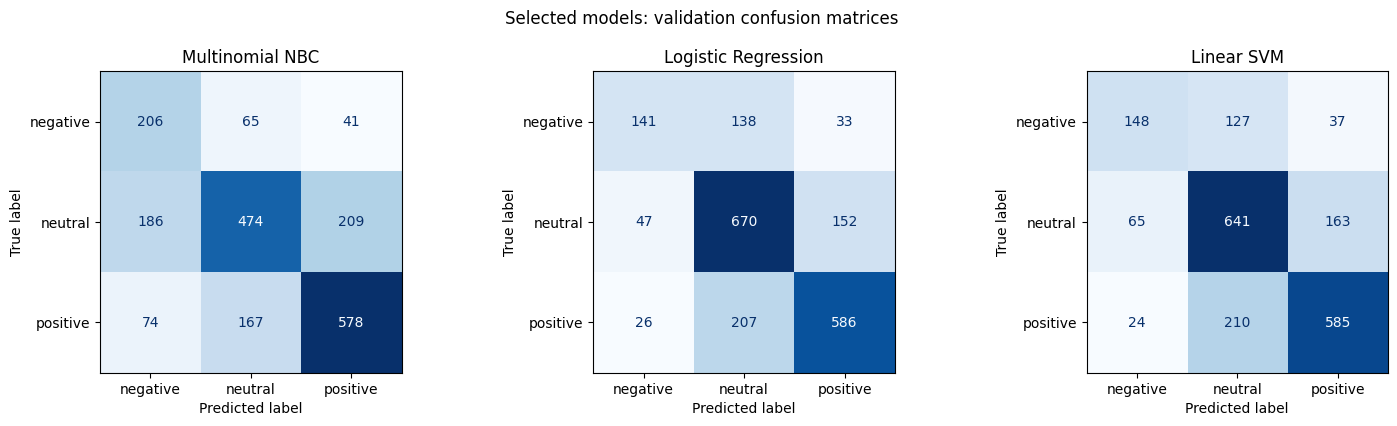

,Method,Class,precision,recall,f1-score,support
0,multinomial_nb,negative,0.4421,0.6603,0.5296,312.0
1,multinomial_nb,neutral,0.6714,0.5455,0.6019,869.0
2,multinomial_nb,positive,0.6981,0.7057,0.7019,819.0
3,logistic_regression,negative,0.6589,0.4519,0.5361,312.0
4,logistic_regression,neutral,0.6601,0.7710,0.7113,869.0
5,logistic_regression,positive,0.7601,0.7155,0.7371,819.0
6,linear_svm,negative,0.6245,0.4744,0.5392,312.0
7,linear_svm,neutral,0.6554,0.7376,0.6941,869.0
8,linear_svm,positive,0.7452,0.7143,0.7294,819.0


Validation mistakes per method:


,Mistakes
Method,
linear_svm,626
logistic_regression,603
multinomial_nb,742


Validation rows with model disagreement: 721


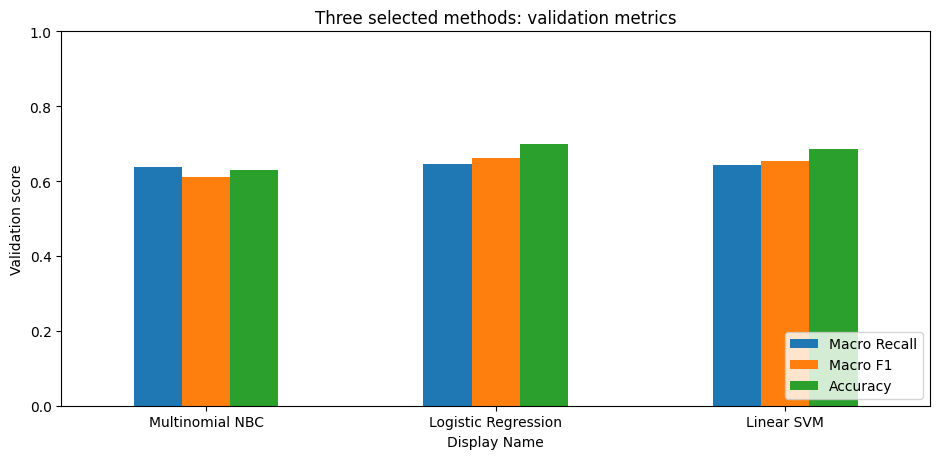

In [ ]:
validation_error_frames = []
per_class_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
disagreements = b_data["validation"][["row_id", "text", "label"]].copy()
for ax, method_id in zip(axes, METHOD_IDS):
    predicted = selected_predictions[method_id]
    disagreements[method_id] = predicted
    report = classification_report(y_val, predicted, labels=CLASS_LABELS, target_names=CLASS_NAMES,
                                   output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(MULTI_OUTPUT_DIR / f"{method_id}_validation_report.csv", index_label="Class_or_average")
    report_text = classification_report(y_val, predicted, labels=CLASS_LABELS, target_names=CLASS_NAMES,
                                       digits=4, zero_division=0)
    (MULTI_OUTPUT_DIR / f"{method_id}_validation_report.txt").write_text(report_text, encoding="utf-8")
    matrix = confusion_matrix(y_val, predicted, labels=CLASS_LABELS)
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        MULTI_OUTPUT_DIR / f"{method_id}_validation_confusion_matrix.csv", index_label="True_label")
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(METHOD_NAMES[method_id])
    for name in CLASS_NAMES:
        per_class_rows.append({"Method": method_id, "Class": name, **report[name]})
    errors = b_data["validation"][["row_id", "text", "label"]].copy()
    errors.insert(0, "Method", method_id)
    errors["predicted_label"] = predicted
    errors["true_sentiment"] = errors["label"].map(LABEL_MAPPING)
    errors["predicted_sentiment"] = errors["predicted_label"].map(LABEL_MAPPING)
    validation_error_frames.append(errors.loc[errors["label"] != errors["predicted_label"]].copy())
fig.suptitle("Selected models: validation confusion matrices")
fig.tight_layout()
fig.savefig(MULTI_OUTPUT_DIR / "three_methods_validation_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()
all_validation_errors = pd.concat(validation_error_frames, ignore_index=True)
all_validation_errors.to_csv(MULTI_OUTPUT_DIR / "all_methods_validation_errors.csv", index=False)
error_pairs = all_validation_errors.groupby(
    ["Method", "label", "true_sentiment", "predicted_label", "predicted_sentiment"], as_index=False
).size().rename(columns={"size": "count"}).sort_values(["Method", "count"], ascending=[True, False])
error_pairs.to_csv(MULTI_OUTPUT_DIR / "validation_error_pairs.csv", index=False)
pd.DataFrame(per_class_rows).to_csv(MULTI_OUTPUT_DIR / "selected_per_class_validation.csv", index=False)
disagreements["All Models Agree"] = disagreements[METHOD_IDS].nunique(axis=1) == 1
disagreements.loc[~disagreements["All Models Agree"]].to_csv(
    MULTI_OUTPUT_DIR / "validation_disagreements.csv", index=False)
display(pd.DataFrame(per_class_rows).round(4))
print("Validation mistakes per method:")
display(all_validation_errors.groupby("Method").size().rename("Mistakes").to_frame())
print("Validation rows with model disagreement:", int((~disagreements["All Models Agree"]).sum()))

plot_frame = selected_methods_df.set_index("Display Name")[SCORE_COLUMNS]
ax = plot_frame.plot.bar(figsize=(9.5, 4.7), rot=0, ylim=(0, 1))
ax.set_ylabel("Validation score")
ax.set_title("Three selected methods: validation metrics")
ax.legend(loc="lower right")
ax.figure.tight_layout()
ax.figure.savefig(MULTI_OUTPUT_DIR / "three_methods_validation_metrics.png", dpi=160, bbox_inches="tight")
plt.show()


## 37. Boundary Inputs and Prediction Consistency
Check empty text, whitespace, unseen tokens, repeated words and batch versus single-row prediction for every selected model. These checks do not affect model selection.

In [ ]:
boundary_records = []
for method_id in METHOD_IDS:
    bundle = selected_bundles[method_id]
    vectorizer = bundle["vectorizer"]
    classifier = bundle["classifier"]
    unseen = "zzztweetevalunseenwordqzx"
    while vectorizer.transform([unseen]).nnz:
        unseen += "qzx"
    repeated = "good" if "good" in vectorizer.vocabulary_ else next(
        token for token in vectorizer.get_feature_names_out() if token.isalpha())
    cases = [
        ("Empty text", ""), ("Whitespace", "   "), ("Unseen word", unseen),
        ("Repeated word", " ".join([repeated] * 3)),
        ("Example A", "I love this update!"), ("Example A repeated", "I love this update!"),
        ("Example B", "The meeting starts at three."), ("Example C", "This service is terrible."),
    ]
    texts = [text for _, text in cases]
    matrix = vectorizer.transform(texts)
    predicted = classifier.predict(matrix)
    assert matrix[:3].nnz == 0 and (matrix[4] != matrix[5]).nnz == 0
    assert predicted[4] == predicted[5] and np.all(predicted[:3] == predicted[0])
    individually = [classifier.predict(vectorizer.transform([text]))[0] for text in texts]
    np.testing.assert_array_equal(predicted, individually)
    if bundle["feature_configuration"].startswith("count_"):
        assert matrix[3, vectorizer.vocabulary_[repeated]] == 3
    if hasattr(classifier, "predict_proba"):
        scores = classifier.predict_proba(matrix)
        np.testing.assert_allclose(scores.sum(axis=1), 1.0, rtol=0, atol=1e-12)
        assert (scores >= 0).all() and (scores <= 1).all()
        score_kind = "Class probabilities"
    else:
        scores = classifier.decision_function(matrix)
        score_kind = "One-vs-rest decision scores (not probabilities)"
    assert scores.shape == (len(cases), len(CLASS_LABELS)) and np.isfinite(scores).all()
    np.testing.assert_array_equal(classifier.classes_[np.argmax(scores, axis=1)], predicted)
    for i, (name, text) in enumerate(cases):
        boundary_records.append({"Method": method_id, "Case": name, "Text": text,
                                 "Nonzero Features": int(matrix[i].nnz),
                                 "Predicted Label": int(predicted[i]),
                                 "Predicted Sentiment": LABEL_MAPPING[int(predicted[i])],
                                 "Score Kind": score_kind})
three_method_boundaries = pd.DataFrame(boundary_records)
assert len(three_method_boundaries) == 24
three_method_boundaries.to_csv(MULTI_OUTPUT_DIR / "three_methods_boundary_checks.csv", index=False)
display(three_method_boundaries[["Method", "Case", "Nonzero Features", "Predicted Sentiment"]])
print("All three pipelines passed boundary, finite-score and batch/single consistency checks.")


,Method,Case,Nonzero Features,Predicted Sentiment
0,multinomial_nb,Empty text,0,neutral
1,multinomial_nb,Whitespace,0,neutral
2,multinomial_nb,Unseen word,0,neutral
3,multinomial_nb,Repeated word,1,positive
4,multinomial_nb,Example A,7,positive
5,multinomial_nb,Example A repeated,7,positive
6,multinomial_nb,Example B,9,neutral
7,multinomial_nb,Example C,7,negative
8,logistic_regression,Empty text,0,neutral
9,logistic_regression,Whitespace,0,neutral


All three pipelines passed boundary, finite-score and batch/single consistency checks.


## 38. Freeze Configurations and Verify Fresh-Process Loading
Freeze all three configurations with file hashes and versions, then reload them in a fresh Python process and confirm every validation prediction. No training happens in that process.

In [ ]:
import platform
import os

shutil.copy2(ROOT / "text_features.py", MULTI_OUTPUT_DIR / "text_features.py")
shutil.copy2(ROOT / "metadata.json", MULTI_OUTPUT_DIR / "group_a_metadata.json")
assert sha256_file(MULTI_OUTPUT_DIR / "text_features.py") == source_metadata["module_sha256"]
for name in ["initial_validation_results.csv", "validation_results.csv", "baseline_comparison.csv",
             "input_checks.csv", "selected_config.json", "verification.json", "validation_errors.csv",
             "validation_error_summary.csv"]:
    shutil.copy2(OUTPUT_DIR / name, MULTI_OUTPUT_DIR / f"nbc_{name}")

protocol = {
    "dataset_id": source_metadata["dataset_id"], "dataset_revision": DATASET_REVISION,
    "dataset_configuration": "sentiment", "class_order": CLASS_LABELS, "labels": LABEL_MAPPING,
    "training_rows": len(y_train), "validation_rows": len(y_val),
    "trained_on": "Official training split only", "validation_used_for_selection": True,
    "test_loaded_by_group_b": False, "test_used_for_selection": False,
    "feature_fit_data": "Original A training split only; A vectorizers never refitted in B",
    "features": FEATURES, "primary_metric": "Macro Recall", "secondary_metric": "Macro F1",
    "nbc_selection_rule": SELECTION_RULE,
    "linear_selection_rule": "Macro Recall descending, Macro F1 descending; exact ties: feature name ascending, C ascending",
    "search_grids": {
        "multinomial_nb": {"alpha": EXTENDED_ALPHAS, "fit_prior": PRIOR_SETTINGS, "candidate_count": 64},
        "logistic_regression": {"C": C_VALUES, "solver": "lbfgs", "penalty": "l2",
                                "class_weight": None, "candidate_count": 12},
        "linear_svm": {"C": C_VALUES, "loss": "squared_hinge", "penalty": "l2", "dual": False,
                       "multi_class": "ovr", "class_weight": None, "candidate_count": 12},
    },
    "total_unique_candidates": 88, "random_state": EXPERIMENT_SEED,
    "linear_tolerance": OPTIMISER_TOLERANCE, "linear_iteration_caps": ITERATION_CAPS,
    "convergence_policy": "Retry only after a convergence warning, with the next declared cap; stop after final failure",
    "svm_solver_reason": "Fixed primal formulation avoids slow dual optimisation on high-dimensional count features; the squared-hinge objective and validation criteria are unchanged.",
    "runtime_measurement": {
        "thread_limit": THREAD_LIMIT, "selected_fit_repeats": 1,
        "prediction_repeats_after_warmup": 5, "prediction_aggregation": "median",
        "includes_vectorization": False, "validation_batch_rows": len(y_val),
    },
    "source_training_csv_sha256": source_metadata["data_sha256"]["train"],
    "source_validation_csv_sha256": source_metadata["data_sha256"]["validation"],
    "source_module_sha256": source_metadata["module_sha256"],
    "source_training_and_validation_files_sha256": {
        str(path.relative_to(ROOT)).replace("\\", "/"): sha256_file(path)
        for feature in FEATURES
        for split in ["train", "validation"]
        for path in [ROOT / "features" / feature / f"X_{split}.npz"]
    },
    "design_limitations": [
        "NBC has a larger historical search budget than LR and SVM; disclose this in the comparison.",
        "Validation is reused for model selection; its scores are not an unbiased final evaluation.",
        "A documents duplicate records, conflicting labels and split overlap and retains them; do not claim deduplicated splits.",
        "Bag-of-words features may miss pragmatic or contextual information; inspect errors before attributing causes.",
        "LinearSVC decision scores are not calibrated class probabilities.",
        "Hardware-dependent timings are measured locally and are not universal speed claims.",
    ],
    "paper": {"authors": "Pang, Lee and Vaithyanathan", "year": 2002,
              "title": "Thumbs up? Sentiment Classification using Machine Learning Techniques",
              "doi": "10.3115/1118693.1118704", "url": "https://aclanthology.org/W02-1011/",
              "relationship": "Adaptation of model families, not exact reproduction of binary movie-review experiments"},
    "group_c_final_test_status": "Not performed by Group B; handoff required",
    "created_utc": datetime.now(timezone.utc).isoformat(),
}
(MULTI_OUTPUT_DIR / "experiment_protocol.json").write_text(json.dumps(protocol, indent=2), encoding="utf-8")
selected_models_record = {"class_order": CLASS_LABELS, "label_mapping": LABEL_MAPPING,
                          "training_split_only": True, "test_evaluated": False,
                          "models": export_registry}
(MULTI_OUTPUT_DIR / "selected_models.json").write_text(json.dumps(selected_models_record, indent=2), encoding="utf-8")
environment_versions = dict(runtime_versions)
environment_versions["threadpoolctl"] = importlib.metadata.version("threadpoolctl")
environment_record = {"python": sys.version.split()[0], "platform": platform.platform(),
                      "packages": environment_versions,
                      "note": "A's pinned processing/model library versions are retained; exact transitive packages are recorded below.",
                      "installed_distributions": sorted(
                          [{"name": d.metadata["Name"], "version": d.version} for d in importlib.metadata.distributions()],
                          key=lambda item: item["name"].lower())}
(MULTI_OUTPUT_DIR / "environment.json").write_text(json.dumps(environment_record, indent=2), encoding="utf-8")
(MULTI_OUTPUT_DIR / "requirements.txt").write_text(
    "\n".join(f"{name}=={version}" for name, version in environment_versions.items()) + "\n", encoding="utf-8")
frozen_files = ["text_features.py", "experiment_protocol.json", "selected_models.json"] + [
    export_registry[method]["bundle_file"] for method in METHOD_IDS]
freeze_record = {"frozen_utc": datetime.now(timezone.utc).isoformat(),
                 "test_evaluated": False,
                 "files_sha256": {name: sha256_file(MULTI_OUTPUT_DIR / name) for name in frozen_files}}
(MULTI_OUTPUT_DIR / "freeze_record.json").write_text(json.dumps(freeze_record, indent=2), encoding="utf-8")

three_reload_script = textwrap.dedent("""
    import sys, json, hashlib
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import joblib
    from sklearn.metrics import recall_score, f1_score, accuracy_score
    sys.dont_write_bytecode = True
    directory, validation_csv = map(Path, sys.argv[1:3])
    sys.path.insert(0, str(directory))
    import text_features
    assert Path(text_features.__file__).resolve() == (directory / 'text_features.py').resolve()
    record = json.loads((directory / 'selected_models.json').read_text(encoding='utf-8'))
    frozen = json.loads((directory / 'freeze_record.json').read_text(encoding='utf-8'))
    protocol = json.loads((directory / 'experiment_protocol.json').read_text(encoding='utf-8'))
    assert hashlib.sha256(validation_csv.read_bytes()).hexdigest() == protocol['source_validation_csv_sha256']
    for name, digest in frozen['files_sha256'].items():
        assert hashlib.sha256((directory / name).read_bytes()).hexdigest() == digest
    frame = pd.read_csv(validation_csv, keep_default_na=False)
    assert len(frame) == 2000
    rows = {}
    for method_id, config in record['models'].items():
        bundle = joblib.load(directory / config['bundle_file'])
        assert bundle['method_id'] == method_id
        assert bundle['classifier'].get_params() == config['model_parameters']
        assert bundle['feature_configuration'] == config['feature_configuration']
        np.testing.assert_array_equal(bundle['classifier'].classes_, record['class_order'])
        saved = pd.read_csv(directory / config['validation_predictions_file'], keep_default_na=False)
        np.testing.assert_array_equal(frame['row_id'], saved['row_id'])
        np.testing.assert_array_equal(frame['label'], saved['true_label'])
        predicted = bundle['classifier'].predict(bundle['vectorizer'].transform(frame['text']))
        np.testing.assert_array_equal(predicted, saved['predicted_label'])
        scores = {
            'Macro Recall': recall_score(frame['label'], predicted, labels=record['class_order'], average='macro'),
            'Macro F1': f1_score(frame['label'], predicted, labels=record['class_order'], average='macro'),
            'Accuracy': accuracy_score(frame['label'], predicted),
        }
        for metric, score in scores.items():
            np.testing.assert_allclose(score, config['validation_metrics'][metric], rtol=0, atol=1e-12)
        rows[method_id] = len(predicted)
    print(json.dumps({'status': 'passed', 'fresh_process': True, 'validation_rows_per_model': rows}))
""")
reload_directory = MULTI_OUTPUT_DIR / "_fresh_process_work"
reload_directory.mkdir(exist_ok=True)
reload_environment = dict(os.environ, PYTHONDONTWRITEBYTECODE="1")
three_reload_result = subprocess.run(
    [sys.executable, "-X", "utf8", "-c", three_reload_script, str(MULTI_OUTPUT_DIR.resolve()),
     str((ROOT / "data" / "validation.csv").resolve())],
    cwd=reload_directory, capture_output=True, text=True, encoding="utf-8", timeout=180,
    env=reload_environment,
)
if three_reload_result.returncode:
    raise RuntimeError(f"Three-model reload failed:\n{three_reload_result.stdout}\n{three_reload_result.stderr}")
three_method_verification = json.loads(three_reload_result.stdout.strip())
three_method_verification.update({
    "candidate_counts": {method_id: int((all_methods_results["Method"] == method_id).sum()) for method_id in METHOD_IDS},
    "all_linear_selected_fits_converged": True,
    "selected_refit_predictions_reproduced": True, "a_vectorizer_alignment": "passed",
    "boundary_checks": "passed", "original_nbc_twelve_results_reproduced": True,
    "test_evaluated": False, "checked_utc": datetime.now(timezone.utc).isoformat(),
})
assert three_method_verification["validation_rows_per_model"] == dict.fromkeys(METHOD_IDS, 2000)
(MULTI_OUTPUT_DIR / "three_method_verification.json").write_text(
    json.dumps(three_method_verification, indent=2), encoding="utf-8")
print("Frozen three-model configuration and fresh-process checks passed.")
display(pd.DataFrame(export_registry).T[["display_name", "feature_configuration", "candidate_count"]])


Frozen three-model configuration and fresh-process checks passed.


,display_name,feature_configuration,candidate_count
multinomial_nb,Multinomial NBC,count_unigram_bigram,64
logistic_regression,Logistic Regression,count_unigram_bigram,12
linear_svm,Linear SVM,count_unigram,12


## 39. Package the Three Trained Models
Create one verified ZIP with the three models, their vectorizers, selection records, validation diagnostics and environment details. It contains no test results.

In [ ]:
majority_reference = json.loads((OUTPUT_DIR / "majority_baseline.json").read_text(encoding="utf-8"))
(MULTI_OUTPUT_DIR / "training_majority_baseline.json").write_text(
    json.dumps(majority_reference, indent=2), encoding="utf-8")
selection_lines = "\n".join(
    f"{method_id}: feature={config['feature_configuration']}; parameters={json.dumps(config['model_parameters'], sort_keys=True)}; "
    f"validation={json.dumps(config['validation_metrics'], sort_keys=True)}"
    for method_id, config in export_registry.items()
)
handoff_readme = f"""TweetEval Group B: final three-method handoff

PURPOSE
This package contains B's training/validation evidence and three selected models.
It contains no final test metrics or test predictions. C performs final testing.
Use this package instead of the intermediate NBC-only archive.

INPUT DEPENDENCY
A's original prepared-data folder/ZIP is required for C's final test evaluation.
Dataset: cardiffnlp/tweet_eval, sentiment subset.
Revision: {DATASET_REVISION}
Original splits and A preprocessing/feature definitions are retained.
Labels: 0=negative, 1=neutral, 2=positive.

EXPERIMENT DESIGN
NBC: 64 configurations, retaining the original 12-result regression check.
Logistic Regression: 4 features x 3 C values = 12 configurations.
Linear SVM: 4 features x 3 C values = 12 configurations.
Primary selection metric: validation Macro Recall; secondary: Macro F1.
All three methods are selected individually and trained on the official training split only.
NBC's historical search budget is larger; disclose this limitation.
See matched_feature_validation.csv for comparisons within the same feature representation.
Convergence retries and full parameters are recorded, not silently discarded.

SELECTED MODELS (VALIDATION SCORES ONLY)
{selection_lines}

LOAD ONE PIPELINE IN A FRESH SESSION
Install requirements.txt, keep text_features.py beside the model bundles, then:

    from pathlib import Path
    import sys, json, joblib
    B_DIR = Path('/content/TweetEval_GroupB_ThreeMethods_Output')
    sys.path.insert(0, str(B_DIR))
    import text_features
    registry = json.loads((B_DIR / 'selected_models.json').read_text())
    method_id = 'multinomial_nb'  # Also: 'logistic_regression' or 'linear_svm'
    config = registry['models'][method_id]
    bundle = joblib.load(B_DIR / config['bundle_file'])
    prediction = bundle['classifier'].predict(bundle['vectorizer'].transform(['I love this update!']))
    print([bundle['label_mapping'][int(label)] for label in prediction])

GROUP C HANDOFF
Evaluate ALL THREE fixed pipelines on the same official test records.
For each model use A's features/<feature_configuration>/X_test.npz,
y_test.npy and row_ids_test.csv. Check their labels/row order against data/test.csv.
Alternatively transform original test texts using that model's saved vectorizer only.
Do not fit a vectorizer, change splits, drop zero vectors or retrain/select settings using test results.
Report Macro Recall, Macro F1, Accuracy, class-level metrics, confusion matrices and error analysis.
Include timing/model-size trade-offs with hardware and timing scope disclosed.
The NBC majority reference is derived from training labels, not test frequencies.
training_majority_baseline.json records the fixed label and validation reference scores.
Linear SVM decision scores are not calibrated class probabilities.
Existing A diagnostics document duplicates, conflicts and split overlap; retain and discuss them.

CORE RECORDS
selected_models.json and freeze_record.json identify fixed pipelines and integrity hashes.
experiment_protocol.json records search grids, metric rules, seeds and design limitations.
all_methods_validation_results.csv contains 88 unique candidates with class-level results.
selected_methods_validation.csv contains one selected row per method.
selected_runtime_and_size.csv uses a common two-thread refit/prediction procedure.
all_methods_validation_errors.csv and validation_disagreements.csv are VALIDATION ONLY.
three_method_verification.json records fresh-process loading and 2,000 matching rows per method.
manifest_sha256.json hashes every packaged file except the manifest itself.
environment.json records Python, OS, direct and installed dependency versions.
requirements_coverage.csv separates completed B evidence from work still owned by C/the group.

ACADEMIC SCOPE
Pang, Lee and Vaithyanathan (2002), DOI 10.3115/1118693.1118704, supports the model-family comparison.
This is an adaptation to three-class tweets, not an exact reproduction of their binary movie-review study.
No novel algorithm is claimed. Read the paper, understand the implementation and discuss deviations.
Write full theory/mathematical reasoning, report, contributions, AI-use disclosure and slides separately.
"""
(MULTI_OUTPUT_DIR / "README.txt").write_text(handoff_readme, encoding="utf-8")
(MULTI_OUTPUT_DIR / "CHANGELOG.txt").write_text(
    "Revision: lecturer's three-method clarification.\n"
    "A: all 33 original cells, code, comments, metadata and saved outputs preserved from the teammate notebook.\n"
    "Existing B1-B15: original NBC model/search/selection and teammate validation-error logic retained.\n"
    "Existing code changes: B2 writes to a separate NBC working folder; B15 marks the NBC archive intermediate and defers download to B24.\n"
    "B16-B24: LR, Linear SVM, shared validation comparison, runtime checks and combined export added.\n"
    "Guide/headings: updated for navigation, research basis, scope and accurate provenance.\n"
    "C final testing and separate report/presentation work are not performed by B.\n",
    encoding="utf-8",
)
coverage = pd.DataFrame([
    {"Requirement": "Original training/validation/test organisation", "Owner": "A",
     "Status": "Supplied by A; preserved", "Evidence": "group_a_metadata.json; original A cells"},
    {"Requirement": "NBC implementation and hyperparameter optimisation", "Owner": "B",
     "Status": "Completed", "Evidence": "nbc_validation_results.csv; multinomial_nb_bundle.joblib"},
    {"Requirement": "At least three meaningfully different methods", "Owner": "B",
     "Status": "Three model families implemented and validated", "Evidence": "selected_models.json; all_methods_validation_results.csv"},
    {"Requirement": "Relevant research article and method traceability", "Owner": "Whole group",
     "Status": "Research basis linked; members must read and explain", "Evidence": "REFERENCES.txt; notebook research basis"},
    {"Requirement": "Systematic experimental comparisons", "Owner": "B and C",
     "Status": "Validation evidence completed; C final test comparison pending", "Evidence": "selected_methods_validation.csv; matched_feature_validation.csv; diagnostics"},
    {"Requirement": "Marginal/boundary cases", "Owner": "B and whole group",
     "Status": "Executable pipeline checks completed; mathematical interpretation remains for report",
     "Evidence": "three_methods_boundary_checks.csv; course-linked method notes"},
    {"Requirement": "Reproducible model/configuration handoff", "Owner": "B",
     "Status": "Completed", "Evidence": "freeze_record.json; three_method_verification.json; manifest_sha256.json"},
    {"Requirement": "Systematic final test evaluation", "Owner": "C",
     "Status": "Pending C; no test execution by B", "Evidence": "README.txt instructions"},
    {"Requirement": "Full theory, mathematical reasoning and lecture connections", "Owner": "Whole group",
     "Status": "Write and verify in separate report", "Evidence": "Notebook method/course references are preparation only"},
    {"Requirement": "Report, individual contributions, references, GenAI disclosure and presentation", "Owner": "Whole group",
     "Status": "Separate deliverables pending", "Evidence": "Original Project Instruction and current Moodle requirements"},
])
coverage.to_csv(MULTI_OUTPUT_DIR / "requirements_coverage.csv", index=False)
(MULTI_OUTPUT_DIR / "REFERENCES.txt").write_text(
    "Pang, B., Lee, L., & Vaithyanathan, S. (2002). Thumbs up? Sentiment Classification using Machine Learning Techniques. EMNLP, 79-86. DOI: 10.3115/1118693.1118704. https://aclanthology.org/W02-1011/\n"
    "scikit-learn 1.6 documentation: https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.LogisticRegression.html\n"
    "scikit-learn 1.6 documentation: https://scikit-learn.org/1.6/modules/generated/sklearn.svm.LinearSVC.html\n"
    "scikit-learn 1.6 documentation: https://scikit-learn.org/1.6/modules/generated/sklearn.naive_bayes.MultinomialNB.html\n"
    "Dataset source: https://huggingface.co/datasets/cardiffnlp/tweet_eval ; revision recorded in experiment_protocol.json.\n"
    "TweetEval evaluation script: https://github.com/cardiffnlp/tweeteval/blob/main/evaluation_script.py\n"
    "Course links verified: Lecture 7 PDF p.5; Lecture 2 PDF p.22; Lab 1 PDF pp.13,31.\n"
    "Requirements sources: Project Instruction.pdf; CSCI323_Project_Topics.pdf sentiment topic; lecturer clarification dated 26 October 2026 supplied by the group.\n",
    encoding="utf-8",
)
handoff_files = [
    "README.txt", "CHANGELOG.txt", "REFERENCES.txt", "requirements_coverage.csv",
    "requirements.txt", "environment.json", "text_features.py", "group_a_metadata.json", "training_majority_baseline.json",
    "experiment_protocol.json", "selected_models.json", "freeze_record.json", "three_method_verification.json",
    "all_methods_validation_results.csv", "logistic_regression_validation_results.csv",
    "linear_svm_validation_results.csv", "linear_fit_attempts.csv", "selected_methods_validation.csv",
    "matched_feature_validation.csv", "selected_runtime_and_size.csv", "selected_per_class_validation.csv",
    "all_methods_validation_errors.csv", "validation_error_pairs.csv", "validation_disagreements.csv",
    "three_methods_validation_confusion_matrices.png", "three_methods_validation_metrics.png",
    "three_methods_boundary_checks.csv", "nbc_initial_validation_results.csv", "nbc_validation_results.csv",
    "nbc_baseline_comparison.csv", "nbc_input_checks.csv", "nbc_selected_config.json", "nbc_verification.json",
    "nbc_validation_errors.csv", "nbc_validation_error_summary.csv",
]
for method_id in METHOD_IDS:
    handoff_files.extend([
        f"{method_id}_bundle.joblib", f"{method_id}_validation_predictions.csv",
        f"{method_id}_validation_report.txt", f"{method_id}_validation_report.csv",
        f"{method_id}_validation_confusion_matrix.csv",
    ])
assert len(handoff_files) == len(set(handoff_files))
assert all((MULTI_OUTPUT_DIR / name).is_file() for name in handoff_files)
manifest = {name: sha256_file(MULTI_OUTPUT_DIR / name) for name in handoff_files}
(MULTI_OUTPUT_DIR / "manifest_sha256.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
handoff_files.append("manifest_sha256.json")
final_zip_path = MULTI_OUTPUT_DIR.parent / "TweetEval_GroupB_ThreeMethods_Handoff.zip"
with zipfile.ZipFile(final_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in handoff_files:
        archive.write(MULTI_OUTPUT_DIR / name, arcname=name)
with zipfile.ZipFile(final_zip_path) as archive:
    assert archive.testzip() is None
    assert set(archive.namelist()) == set(handoff_files)
    for name, digest in manifest.items():
        assert hashlib.sha256(archive.read(name)).hexdigest() == digest
print("FINAL THREE-MODEL PACKAGE:", final_zip_path)
print("Verified package files:", len(handoff_files))
print("Models:", ", ".join(METHOD_NAMES.values()))
print("Validation completed; the final test evaluation follows in Part 3.")
display(selected_methods_df[["Display Name", "Feature"] + SCORE_COLUMNS].round(4))
try:
    from google.colab import files
except ImportError:
    from IPython.display import FileLink
    display(FileLink(str(final_zip_path)))
else:
    files.download(str(final_zip_path))


FINAL THREE-METHOD HANDOFF: /content/drive/MyDrive/CSCI323/TweetEval_GroupB_ThreeMethods_Handoff.zip
Verified package files: 51
Models: Multinomial NBC, Logistic Regression, Linear SVM
Validation completed; final test evaluation remains with Group C.


,Display Name,Feature,Macro Recall,Macro F1,Accuracy
0,Multinomial NBC,count_unigram_bigram,0.6371,0.6111,0.6290
1,Logistic Regression,count_unigram_bigram,0.6461,0.6615,0.6985
2,Linear SVM,count_unigram,0.6421,0.6542,0.6870


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 3: Final Test Evaluation and Analysis
Load the three frozen models, evaluate them once on the official test set and analyse their errors, marginal cases and features. No model is retrained or re-selected in this part.

## 40. Set Up and Locate the Saved Files
Mount Google Drive, set the paths to the prepared data, the trained-model ZIP and the output folder, and check library versions against the training environment.

In [ ]:

import sys, json, hashlib, zipfile, shutil, importlib.metadata
from pathlib import Path
from datetime import datetime, timezone

sys.dont_write_bytecode = True  # do not write cache files into the extracted model folders

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    pass

BASE = Path("/content/drive/MyDrive/CSCI323")
A_DIR = BASE / "TweetEval_Prepared"
B_ZIP = BASE / "TweetEval_GroupB_ThreeMethods_Handoff.zip"
C_DIR = BASE / "TweetEval_GroupC_Evaluation"
B_HANDOFF = C_DIR / "b_handoff"

for required in [A_DIR / "metadata.json", A_DIR / "data" / "test.csv",
                 A_DIR / "checks" / "record_diagnostics.csv", B_ZIP]:
    assert required.exists(), f"Missing required file: {required}"

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

C_DIR.mkdir(parents=True, exist_ok=True)
for sub in ["tables", "figures", "errors"]:
    (C_DIR / sub).mkdir(exist_ok=True)


if B_HANDOFF.exists():
    shutil.rmtree(B_HANDOFF)
with zipfile.ZipFile(B_ZIP) as archive:
    assert archive.testzip() is None, "Model ZIP is corrupted."
    archive.extractall(B_HANDOFF)


required_versions = {}
for line in (B_HANDOFF / "requirements.txt").read_text(encoding="utf-8").splitlines():
    if "==" in line:
        name, version = line.strip().split("==")
        required_versions[name] = version

critical = {"numpy", "scipy", "scikit-learn", "joblib", "pandas"}
version_rows = []
for name, wanted in required_versions.items():
    try:
        installed = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    version_rows.append((name, wanted, installed, installed == wanted))

print(f"{'Package':<18}{'Required':<12}{'Installed':<12}Match")
for name, wanted, installed, ok in version_rows:
    print(f"{name:<18}{wanted:<12}{str(installed):<12}{'yes' if ok else 'NO'}")

critical_mismatch = [r for r in version_rows if r[0] in critical and not r[3]]
if critical_mismatch:
    pins = " ".join(f"{n}=={w}" for n, w, _, _ in version_rows if n in critical | {"matplotlib"})
    raise RuntimeError(
        "Critical package versions differ from the training environment.\n"
        f"Run:  %pip -q install {pins}\nthen restart the runtime and rerun Step 40."
    )

C_STARTED_UTC = datetime.now(timezone.utc).isoformat()
print("\nPrepared data folder  :", A_DIR)
print("Model package (ZIP)   :", B_ZIP)
print("Extracted model files :", B_HANDOFF)
print("Results output folder :", C_DIR)
print("Files extracted       :", len(list(B_HANDOFF.iterdir())))

Mounted at /content/drive
Package           Required    Installed   Match
datasets          4.8.5       4.8.5       yes
huggingface_hub   1.33.0      1.33.0      yes
numpy             2.1.3       2.1.3       yes
pandas            2.2.3       2.2.3       yes
scipy             1.16.3      1.16.3      yes
scikit-learn      1.6.1       1.6.1       yes
joblib            1.6.0       1.6.0       yes
matplotlib        3.10.0      3.10.0      yes
threadpoolctl     3.7.0       3.7.0       yes

Group A prepared data : /content/drive/MyDrive/CSCI323/TweetEval_Prepared
Group B handoff (ZIP): /content/drive/MyDrive/CSCI323/TweetEval_GroupB_ThreeMethods_Handoff.zip
Extracted handoff     : /content/drive/MyDrive/CSCI323/TweetEval_GroupC_Evaluation/b_handoff
Group C output folder : /content/drive/MyDrive/CSCI323/TweetEval_GroupC_Evaluation
Files extracted       : 51


## 41. Verify the Model Package and Load the Three Models
Check every file against its SHA-256 manifest, load the three saved pipelines and the baseline, and reproduce their validation predictions.

In [ ]:

import numpy as np
import pandas as pd
import joblib
from IPython.display import display
from sklearn.metrics import recall_score, f1_score, accuracy_score


manifest = json.loads((B_HANDOFF / "manifest_sha256.json").read_text(encoding="utf-8"))
bad_files = [name for name, digest in manifest.items() if sha256_file(B_HANDOFF / name) != digest]
assert not bad_files, f"Files changed after the model package was created: {bad_files}"

freeze = json.loads((B_HANDOFF / "freeze_record.json").read_text(encoding="utf-8"))
for name, digest in freeze["files_sha256"].items():
    assert sha256_file(B_HANDOFF / name) == digest, f"Frozen file changed: {name}"
assert freeze["test_evaluated"] is False, "The saved record shows that the test set was already evaluated."


protocol = json.loads((B_HANDOFF / "experiment_protocol.json").read_text(encoding="utf-8"))
selected = json.loads((B_HANDOFF / "selected_models.json").read_text(encoding="utf-8"))
a_meta = json.loads((A_DIR / "metadata.json").read_text(encoding="utf-8"))
assert protocol["dataset_revision"] == a_meta["revision"]
assert protocol["source_module_sha256"] == a_meta["module_sha256"]
assert sha256_file(B_HANDOFF / "text_features.py") == a_meta["module_sha256"]
assert protocol["test_loaded_by_group_b"] is False and protocol["test_used_for_selection"] is False

CLASS_LABELS = [0, 1, 2]
LABEL_MAPPING = {0: "negative", 1: "neutral", 2: "positive"}
CLASS_NAMES = [LABEL_MAPPING[label] for label in CLASS_LABELS]
assert selected["class_order"] == CLASS_LABELS

METHOD_IDS = ["multinomial_nb", "logistic_regression", "linear_svm"]
assert set(selected["models"]) == set(METHOD_IDS)
METHOD_NAMES = {m: selected["models"][m]["display_name"] for m in METHOD_IDS}

# 3) Import the shared text processing module BEFORE unpickling the bundles.
if str(B_HANDOFF) not in sys.path:
    sys.path.insert(0, str(B_HANDOFF))
import text_features
assert sha256_file(text_features.__file__) == a_meta["module_sha256"], (
    "A different text_features.py is loaded. Restart the runtime and rerun Steps 40-41.")

# 4) Load each bundle and check that its stored settings match selected_models.json.
bundles = {}
for method_id in METHOD_IDS:
    config = selected["models"][method_id]
    bundle = joblib.load(B_HANDOFF / config["bundle_file"])
    assert bundle["method_id"] == method_id
    assert bundle["feature_configuration"] == config["feature_configuration"]
    assert bundle["classifier"].get_params() == config["model_parameters"]
    np.testing.assert_array_equal(bundle["classifier"].classes_, CLASS_LABELS)
    assert bundle["classifier"].n_features_in_ == len(bundle["vectorizer"].vocabulary_)
    bundles[method_id] = bundle


val_csv = A_DIR / "data" / "validation.csv"
assert sha256_file(val_csv) == a_meta["data_sha256"]["validation"]
val_df = pd.read_csv(val_csv, keep_default_na=False)
y_val = val_df["label"].to_numpy()

reference_rows = []
for method_id in METHOD_IDS:
    config, bundle = selected["models"][method_id], bundles[method_id]
    saved = pd.read_csv(B_HANDOFF / config["validation_predictions_file"], keep_default_na=False)
    np.testing.assert_array_equal(saved["row_id"], val_df["row_id"])
    predicted = bundle["classifier"].predict(bundle["vectorizer"].transform(val_df["text"]))
    np.testing.assert_array_equal(predicted, saved["predicted_label"])
    scores = {
        "Macro Recall": recall_score(y_val, predicted, labels=CLASS_LABELS, average="macro"),
        "Macro F1": f1_score(y_val, predicted, labels=CLASS_LABELS, average="macro"),
        "Accuracy": accuracy_score(y_val, predicted),
    }
    for metric, value in scores.items():
        np.testing.assert_allclose(value, config["validation_metrics"][metric], rtol=0, atol=1e-12)
    params = config["model_parameters"]
    key_settings = (f"alpha={params['alpha']}, fit_prior={params['fit_prior']}"
                    if method_id == "multinomial_nb" else f"C={params['C']}, penalty={params['penalty']}")
    reference_rows.append({"Method": METHOD_NAMES[method_id],
                           "Feature": config["feature_configuration"],
                           "Key settings": key_settings,
                           "Candidates searched": config["candidate_count"], **scores})

validation_reference = pd.DataFrame(reference_rows)
validation_reference.to_csv(C_DIR / "tables" / "c00_validation_reference.csv", index=False)


majority_record = json.loads((B_HANDOFF / "training_majority_baseline.json").read_text(encoding="utf-8"))
MAJORITY_LABEL = int(majority_record["training_majority_label"])

print(f"Manifest verified: {len(manifest)} files | frozen files verified: {len(freeze['files_sha256'])}")
print("Loaded pipelines:", ", ".join(METHOD_NAMES.values()))
print("All 2,000 validation predictions reproduced for every model.")
print(f"Training-majority baseline: label {MAJORITY_LABEL} ({LABEL_MAPPING[MAJORITY_LABEL]})")
print("\nValidation reference scores (used for model selection, NOT final results):")
display(validation_reference.round(4))

Manifest verified: 50 files | frozen files verified: 6
Loaded pipelines: Multinomial NBC, Logistic Regression, Linear SVM
All 2,000 validation predictions reproduced for every model.
Training-majority baseline: label 1 (neutral)

Validation reference scores (used by B for selection, NOT final results):


,Method,Feature,Key settings,Candidates searched,Macro Recall,Macro F1,Accuracy
0,Multinomial NBC,count_unigram_bigram,"alpha=0.5, fit_prior=True",64,0.6371,0.6111,0.6290
1,Logistic Regression,count_unigram_bigram,"C=0.1, penalty=l2",12,0.6461,0.6615,0.6985
2,Linear SVM,count_unigram,"C=0.1, penalty=l2",12,0.6421,0.6542,0.6870


## 42. Verify Test-Set Alignment (No Predictions Yet)
Confirm that the test text, feature matrices, labels and row IDs all match. All 12,284 test records are kept, including duplicates, conflicting labels and all-zero vectors.

In [ ]:
# Step 42. Verify that the test matrices, labels and row IDs match the original test records
import scipy.sparse as sp


test_csv = A_DIR / "data" / "test.csv"
assert sha256_file(test_csv) == a_meta["data_sha256"]["test"], "test.csv differs from the prepared-data metadata."
test_df = pd.read_csv(test_csv, keep_default_na=False)
assert len(test_df) == 12284
assert test_df["row_id"].is_unique
assert np.array_equal(test_df["row_id"].to_numpy(), [f"test_{i:06d}" for i in range(len(test_df))])
assert set(test_df["label"].unique()) == set(CLASS_LABELS)
y_test = test_df["label"].to_numpy()


X_test = {}
alignment_rows = []
for method_id in METHOD_IDS:
    feature = selected["models"][method_id]["feature_configuration"]
    folder = A_DIR / "features" / feature
    matrix = sp.load_npz(folder / "X_test.npz").tocsr()
    labels = np.load(folder / "y_test.npy", allow_pickle=False)
    row_ids = pd.read_csv(folder / "row_ids_test.csv", keep_default_na=False)["row_id"].to_numpy()

    assert matrix.shape == (len(test_df), bundles[method_id]["classifier"].n_features_in_)
    np.testing.assert_array_equal(labels, y_test)
    np.testing.assert_array_equal(row_ids, test_df["row_id"].to_numpy())
    assert np.isfinite(matrix.data).all() and (matrix.data >= 0).all()

    retransformed = bundles[method_id]["vectorizer"].transform(test_df["text"]).tocsr()
    assert retransformed.shape == matrix.shape and (retransformed != matrix).nnz == 0

    X_test[method_id] = matrix
    zero_rows = int((matrix.getnnz(axis=1) == 0).sum())
    alignment_rows.append({"Method": METHOD_NAMES[method_id], "Feature": feature,
                           "Rows": matrix.shape[0], "Columns": matrix.shape[1],
                           "All-zero rows (retained)": zero_rows,
                           "Labels match": True, "Row IDs match": True,
                           "Saved vectorizer reproduces matrix": True})

test_alignment = pd.DataFrame(alignment_rows)
test_alignment.to_csv(C_DIR / "tables" / "c01_test_alignment.csv", index=False)

# 3) Documented data-quality issues in test are retained, not removed.
quality = pd.read_csv(A_DIR / "checks" / "quality_checks.csv").set_index("split")
conflicts = pd.read_csv(A_DIR / "checks" / "label_conflicts.csv", keep_default_na=False)
test_conflict_rows = conflicts.loc[conflicts["split"] == "test"]

# 4) Class mix: the official test distribution differs strongly from training.
train_labels = pd.read_csv(A_DIR / "data" / "train.csv", keep_default_na=False)["label"]
assert int(train_labels.value_counts().idxmax()) == MAJORITY_LABEL
class_mix = pd.DataFrame({
    "train_count": train_labels.value_counts().reindex(CLASS_LABELS).to_numpy(),
    "validation_count": pd.Series(y_val).value_counts().reindex(CLASS_LABELS).to_numpy(),
    "test_count": pd.Series(y_test).value_counts().reindex(CLASS_LABELS).to_numpy(),
}, index=CLASS_NAMES)
for split in ["train", "validation", "test"]:
    class_mix[f"{split}_%"] = (100 * class_mix[f"{split}_count"] / class_mix[f"{split}_count"].sum()).round(2)
class_mix.to_csv(C_DIR / "tables" / "c02_class_mix.csv", index_label="class")

print("test.csv verified:", len(test_df), "records, hash matches the prepared-data metadata.")
display(test_alignment)
print(f"Test duplicates (normalised text): {int(quality.loc['test', 'duplicate_rows_normalised'])} | "
      f"conflicting-label text keys: {int(quality.loc['test', 'conflicting_text_keys'])} "
      f"({len(test_conflict_rows)} rows) -> all retained.")
print("\nClass distribution by split:")
display(class_mix)

test.csv verified: 12284 records, hash matches A's metadata.


,Method,Feature,Rows,Columns,All-zero rows (retained),Labels match,Row IDs match,Saved vectorizer reproduces matrix
0,Multinomial NBC,count_unigram_bigram,12284,60000,7,True,True,True
1,Logistic Regression,count_unigram_bigram,12284,60000,7,True,True,True
2,Linear SVM,count_unigram,12284,20175,5,True,True,True


Test duplicates (normalised text): 4 | conflicting-label text keys: 3 (7 rows) -> all retained.

Class distribution by split:


,train_count,validation_count,test_count,train_%,validation_%,test_%
negative,7093,312,3972,15.55,15.60,32.33
neutral,20673,869,5937,45.32,43.45,48.33
positive,17849,819,2375,39.13,40.95,19.33


## 43. Freeze the Evaluation Plan
Save the metrics, statistical tests, error slices and marginal-case definition to a hashed file before any test prediction, so they cannot be changed after the results are seen.

In [ ]:
# Step 43. Freeze the evaluation plan BEFORE any test prediction is made
import re

assert "test_predictions" not in globals(), "Test predictions already exist; the plan must be frozen first."

# Error-analysis slice rules, fixed now so they cannot be tuned to the test results.

SLICE_PATTERNS = {
    "negation": r"\b(?:not|no|never|nothing|nobody|none|neither|nor|cannot|without)\b|n't\b",
    "contrast_mixed": r"\b(?:but|however|although|though|yet|whereas|despite|nevertheless)\b",
    "sarcasm_marker": r"#sarcasm\b|#not\b|\byeah right\b|\bjust great\b|\bthanks a lot\b|\bas if\b",
    "question": r"\?",
    "exclamation": r"!",
}
SLICE_FROM_A_DIAGNOSTICS = {
    "emoji_like": "has_emoji_like_symbol == True (A's documented Unicode-range heuristic)",
    "short_1_10_words": "length_group == '1-10'",
    "high_oov_50pct": "outside_vocabulary_percent >= 50 (A's count_unigram vocabulary)",
    "all_zero_vector": "all_zero_<model feature configuration> == True",
}

BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_SEED = 323
MARGINAL_QUANTILE = 0.10          # lowest 10% decision margin within each model
PROBABILITY_MARGIN_THRESHOLD = 0.10

evaluation_plan = {
    "frozen_utc": datetime.now(timezone.utc).isoformat(),
    "status": "Frozen before any test prediction was computed",
    "test_records": int(len(test_df)),
    "class_order": CLASS_LABELS,
    "labels": LABEL_MAPPING,
    "models_under_test": {
        m: {"display_name": METHOD_NAMES[m],
            "bundle_file": selected["models"][m]["bundle_file"],
            "bundle_sha256": sha256_file(B_HANDOFF / selected["models"][m]["bundle_file"]),
            "feature_configuration": selected["models"][m]["feature_configuration"],
            "model_parameters": selected["models"][m]["model_parameters"]}
        for m in METHOD_IDS},
    "baseline": {"name": "Training-majority classifier",
                 "rule": "Predict the most frequent TRAINING label for every test record",
                 "label": MAJORITY_LABEL, "label_name": LABEL_MAPPING[MAJORITY_LABEL]},
    "rules": [
        "Models, vectorizers and hyperparameters stay fixed; no retraining, refitting or reselection.",
        "Vectorizers use transform() only; A's test matrices are used after the C3 alignment check.",
        "All 12,284 test records are retained, including all-zero vectors, duplicates and label conflicts.",
        "Test results are reported for all three methods; they are not used to pick a new configuration.",
    ],
    "metrics": {
        "primary": "Macro Recall (TweetEval sentiment official metric)",
        "secondary": "Macro F1",
        "supplementary": ["Accuracy", "Per-class precision/recall/F1",
                          "Confusion matrix (counts and row-normalised)", "Weighted F1"],
    },
    "statistical_analysis": {
        "confidence_intervals": f"Percentile bootstrap, {BOOTSTRAP_RESAMPLES} resamples, seed {BOOTSTRAP_SEED}, 95%",
        "paired_differences": "Paired bootstrap on the same resampled indices for model-vs-model and model-vs-baseline",
        "significance": "Exact McNemar test (binomial on discordant pairs) for each model pair, Holm correction",
        "generalisation_gap": "Test score minus validation score for each metric",
        "prior_shift_check": "Compare predicted class proportions with true test proportions",
    },
    "error_analysis": {
        "slice_regex_rules": SLICE_PATTERNS,
        "slices_from_A_diagnostics": SLICE_FROM_A_DIAGNOSTICS,
        "report": "Error rate and Macro Recall per slice per model; slices are hypotheses, not proven causes",
        "case_table": "Misclassified examples with text, true label, predicted labels of all models, possible reason",
    },
    "marginal_case_definition": {
        "multinomial_nb": "Gap between the two largest posterior probabilities P(c|x)",
        "logistic_regression": "Gap between the two largest softmax probabilities P(c|x)",
        "linear_svm": "Gap between the two largest one-vs-rest decision scores w_c.x + b_c (not probabilities)",
        "marginal_rule": f"Lowest {int(MARGINAL_QUANTILE*100)}% margin within each model; "
                         f"for NB/LR also probability gap < {PROBABILITY_MARGIN_THRESHOLD}",
        "degenerate_boundary": "All-zero feature vectors: prediction decided only by class prior / intercepts",
    },
    "supplementary_experiment": {
        "description": "Hand-written hard sentences with labels assigned by the group BEFORE running the models",
        "reporting": "Reported separately from the official test set; never merged into test metrics",
    },
}

plan_path = C_DIR / "c_evaluation_plan.json"
if plan_path.exists():
    # Reuse the plan frozen before testing; never rewrite it after test results were seen.
    frozen_plan = json.loads(plan_path.read_text(encoding="utf-8"))
    current = {k: v for k, v in json.loads(json.dumps(evaluation_plan)).items() if k != "frozen_utc"}
    previous = {k: v for k, v in frozen_plan.items() if k != "frozen_utc"}
    assert current == previous, "Plan content differs from the frozen plan. Do not change it after testing."
    evaluation_plan = frozen_plan
    print("Existing frozen plan reused; originally frozen at", frozen_plan["frozen_utc"])
else:
    plan_path.write_text(json.dumps(evaluation_plan, indent=2), encoding="utf-8")
    print("New evaluation plan frozen at", evaluation_plan["frozen_utc"])
EVALUATION_PLAN_SHA256 = sha256_file(plan_path)

print("Evaluation plan:", plan_path)
print("Plan SHA-256:", EVALUATION_PLAN_SHA256)
print("Primary metric:", evaluation_plan["metrics"]["primary"])
print("Slices defined:", list(SLICE_PATTERNS) + list(SLICE_FROM_A_DIAGNOSTICS))

Existing frozen plan reused; originally frozen at 2026-10-29T18:53:39.227127+00:00
Evaluation plan: /content/drive/MyDrive/CSCI323/TweetEval_GroupC_Evaluation/c_evaluation_plan.json
Plan SHA-256: e9be886aad16d3629467718fb894bc3b369b0bc7c5e70f9c0e14b0417d893ab7
Primary metric: Macro Recall (TweetEval sentiment official metric)
Slices defined: ['negation', 'contrast_mixed', 'sarcasm_marker', 'question', 'exclamation', 'emoji_like', 'short_1_10_words', 'high_oov_50pct', 'all_zero_vector']


## 44. Final Test Results
Run each frozen model once on the test set and report Macro Recall (primary), Macro F1, accuracy and other metrics. Compare them with validation scores, the baseline and the true class proportions.

In [ ]:
# Step 44. Final test evaluation of the three fixed pipelines and the training-majority baseline
from time import perf_counter
from threadpoolctl import threadpool_limits
from sklearn.metrics import precision_score

assert sha256_file(plan_path) == EVALUATION_PLAN_SHA256, "Evaluation plan changed after freezing."

def score_predictions(true_labels, predicted_labels):
    return {
        "Macro Recall": recall_score(true_labels, predicted_labels, labels=CLASS_LABELS, average="macro", zero_division=0),
        "Macro F1": f1_score(true_labels, predicted_labels, labels=CLASS_LABELS, average="macro", zero_division=0),
        "Accuracy": accuracy_score(true_labels, predicted_labels),
        "Macro Precision": precision_score(true_labels, predicted_labels, labels=CLASS_LABELS, average="macro", zero_division=0),
        "Weighted F1": f1_score(true_labels, predicted_labels, labels=CLASS_LABELS, average="weighted", zero_division=0),
    }

test_predictions = {}
test_scores_raw = {}   # probabilities (NB, LR) or decision scores (SVM), kept for marginal-case analysis
timing_rows = []

for method_id in METHOD_IDS:
    classifier = bundles[method_id]["classifier"]
    matrix = X_test[method_id]
    with threadpool_limits(limits=2):
        predicted = classifier.predict(matrix)          # warm-up and the official prediction
        times = []
        for _ in range(5):
            start = perf_counter()
            repeat = classifier.predict(matrix)
            times.append(perf_counter() - start)
            np.testing.assert_array_equal(repeat, predicted)
        if hasattr(classifier, "predict_proba"):
            raw = classifier.predict_proba(matrix)
            score_kind = "probability"
        else:
            raw = classifier.decision_function(matrix)
            score_kind = "decision score"
    assert set(np.unique(predicted)).issubset(CLASS_LABELS)
    np.testing.assert_array_equal(classifier.classes_[np.argmax(raw, axis=1)], predicted)
    test_predictions[method_id] = predicted
    test_scores_raw[method_id] = {"values": raw, "kind": score_kind}
    timing_rows.append({"Method": METHOD_NAMES[method_id], "Test rows": matrix.shape[0],
                        "Predict seconds (median of 5, 2 threads)": float(np.median(times)),
                        "Score type": score_kind})

# Training-majority baseline: every test record predicted as the TRAINING majority label.
baseline_pred = np.full(len(y_test), MAJORITY_LABEL)

# Main results table.
result_rows = []
for method_id in METHOD_IDS:
    result_rows.append({"Method": METHOD_NAMES[method_id],
                        "Feature": selected["models"][method_id]["feature_configuration"],
                        **score_predictions(y_test, test_predictions[method_id])})
result_rows.append({"Method": "Training-majority baseline (neutral)", "Feature": "-",
                    **score_predictions(y_test, baseline_pred)})
test_results = pd.DataFrame(result_rows)
test_results.to_csv(C_DIR / "tables" / "c03_test_results.csv", index=False)

# Validation vs test (generalisation gap) for the three methods.
gap_rows = []
for method_id in METHOD_IDS:
    val_m = selected["models"][method_id]["validation_metrics"]
    test_m = score_predictions(y_test, test_predictions[method_id])
    row = {"Method": METHOD_NAMES[method_id]}
    for metric in ["Macro Recall", "Macro F1", "Accuracy"]:
        row[f"Val {metric}"] = val_m[metric]
        row[f"Test {metric}"] = test_m[metric]
        row[f"Gap {metric}"] = test_m[metric] - val_m[metric]
    gap_rows.append(row)
generalisation_gap = pd.DataFrame(gap_rows)
generalisation_gap.to_csv(C_DIR / "tables" / "c04_validation_vs_test.csv", index=False)

# Improvement over the baseline (absolute points).
base = test_results.iloc[-1]
improvement = test_results.iloc[:-1][["Method"]].copy()
for metric in ["Macro Recall", "Macro F1", "Accuracy"]:
    improvement[f"{metric} gain vs baseline"] = test_results.iloc[:-1][metric].to_numpy() - base[metric]
improvement.to_csv(C_DIR / "tables" / "c05_gain_over_baseline.csv", index=False)

# Predicted class proportions vs the true test distribution (prior-shift check).
proportion = pd.DataFrame({"True test %": pd.Series(y_test).value_counts(normalize=True).reindex(CLASS_LABELS).to_numpy() * 100},
                          index=CLASS_NAMES)
for method_id in METHOD_IDS:
    proportion[f"{METHOD_NAMES[method_id]} predicted %"] = (
        pd.Series(test_predictions[method_id]).value_counts(normalize=True).reindex(CLASS_LABELS, fill_value=0).to_numpy() * 100)
proportion.to_csv(C_DIR / "tables" / "c06_predicted_class_proportions.csv", index_label="class")

timing = pd.DataFrame(timing_rows)
timing.to_csv(C_DIR / "tables" / "c07_test_prediction_timing.csv", index=False)

# Save all row-level test predictions with stable row IDs.
prediction_table = test_df[["row_id", "text", "label"]].rename(columns={"label": "true_label"}).copy()
prediction_table["true_sentiment"] = prediction_table["true_label"].map(LABEL_MAPPING)
for method_id in METHOD_IDS:
    prediction_table[f"pred_{method_id}"] = test_predictions[method_id]
prediction_table["pred_majority_baseline"] = baseline_pred
prediction_table.to_csv(C_DIR / "tables" / "c08_test_predictions_all_models.csv", index=False)

print("FINAL TEST RESULTS (12,284 official test records)")
display(test_results.round(4))
print("Validation vs test:")
display(generalisation_gap.round(4))
print("Gain over the training-majority baseline (absolute):")
display(improvement.round(4))
print("Predicted vs true class proportions (%):")
display(proportion.round(2))
display(timing.round(5))

FINAL TEST RESULTS (12,284 official test records)


,Method,Feature,Macro Recall,Macro F1,Accuracy,Macro Precision,Weighted F1
0,Multinomial NBC,count_unigram_bigram,0.6072,0.5966,0.5988,0.5919,0.5989
1,Logistic Regression,count_unigram_bigram,0.5684,0.5699,0.6062,0.6229,0.5875
2,Linear SVM,count_unigram,0.5747,0.5730,0.5959,0.5924,0.5893
3,Training-majority baseline (neutral),-,0.3333,0.2172,0.4833,0.1611,0.3150


Validation vs test:


,Method,Val Macro Recall,Test Macro Recall,Gap Macro Recall,Val Macro F1,Test Macro F1,Gap Macro F1,Val Accuracy,Test Accuracy,Gap Accuracy
0,Multinomial NBC,0.6371,0.6072,-0.0299,0.6111,0.5966,-0.0145,0.6290,0.5988,-0.0302
1,Logistic Regression,0.6461,0.5684,-0.0777,0.6615,0.5699,-0.0916,0.6985,0.6062,-0.0923
2,Linear SVM,0.6421,0.5747,-0.0674,0.6542,0.5730,-0.0813,0.6870,0.5959,-0.0911


Gain over the training-majority baseline (absolute):


,Method,Macro Recall gain vs baseline,Macro F1 gain vs baseline,Accuracy gain vs baseline
0,Multinomial NBC,0.2739,0.3794,0.1155
1,Logistic Regression,0.2351,0.3527,0.1228
2,Linear SVM,0.2414,0.3557,0.1126


Predicted vs true class proportions (%):


,True test %,Multinomial NBC predicted %,Logistic Regression predicted %,Linear SVM predicted %
negative,32.33,38.03,15.77,20.90
neutral,48.33,41.04,65.35,57.20
positive,19.33,20.94,18.89,21.91


,Method,Test rows,"Predict seconds (median of 5, 2 threads)",Score type
0,Multinomial NBC,12284,0.00338,probability
1,Logistic Regression,12284,0.00343,probability
2,Linear SVM,12284,0.00167,decision score


## 45. Per-Class Metrics, Confusion Matrices and Result Figures
Break down the test results by class and draw the confusion matrices and summary figures.

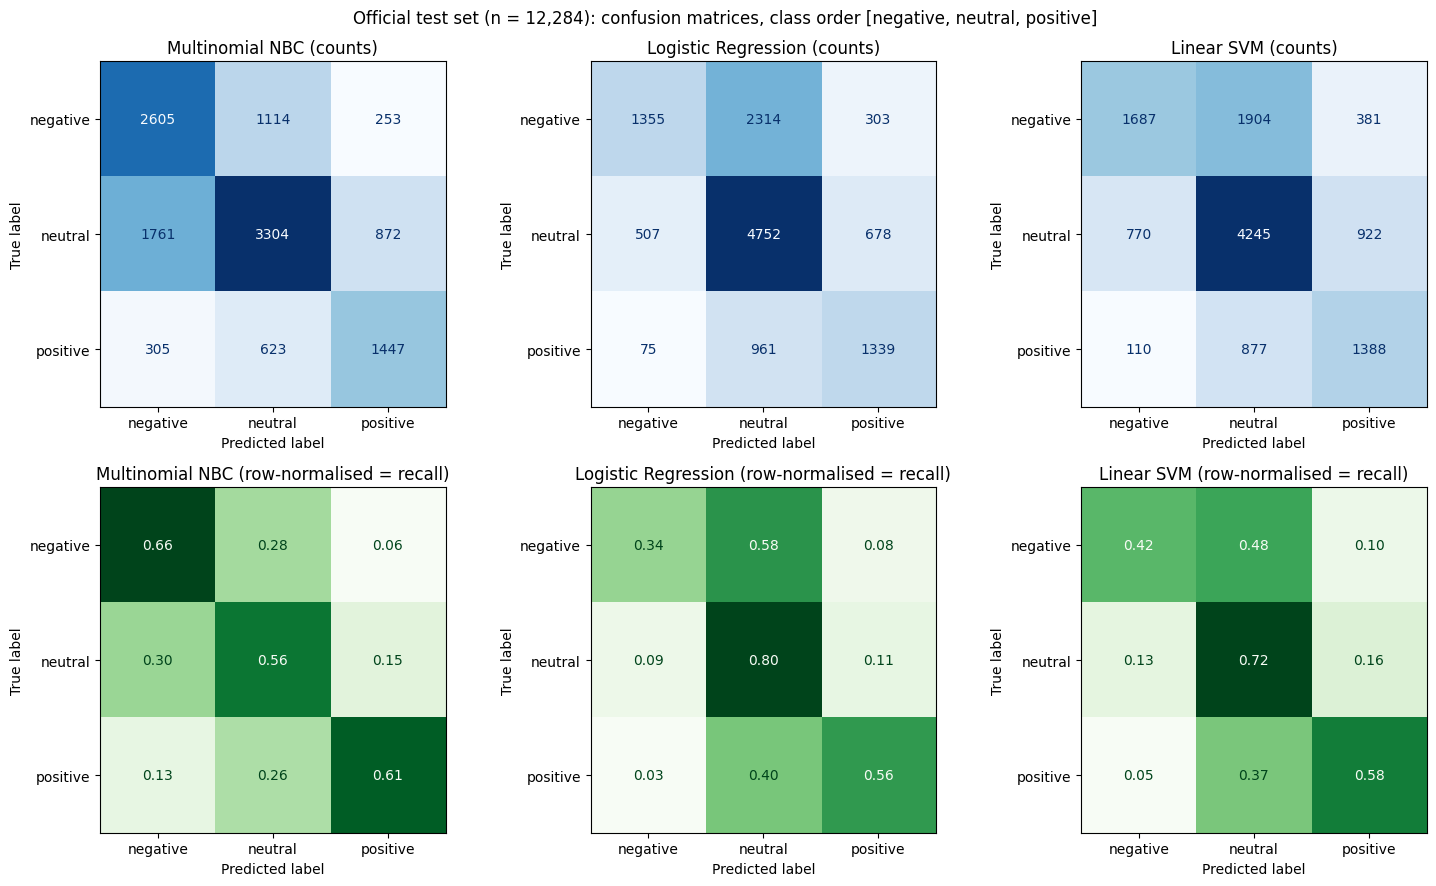

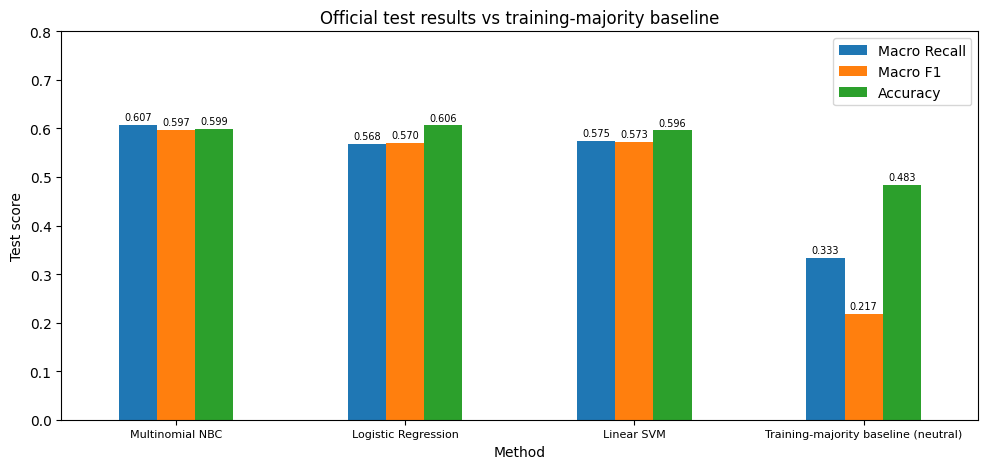

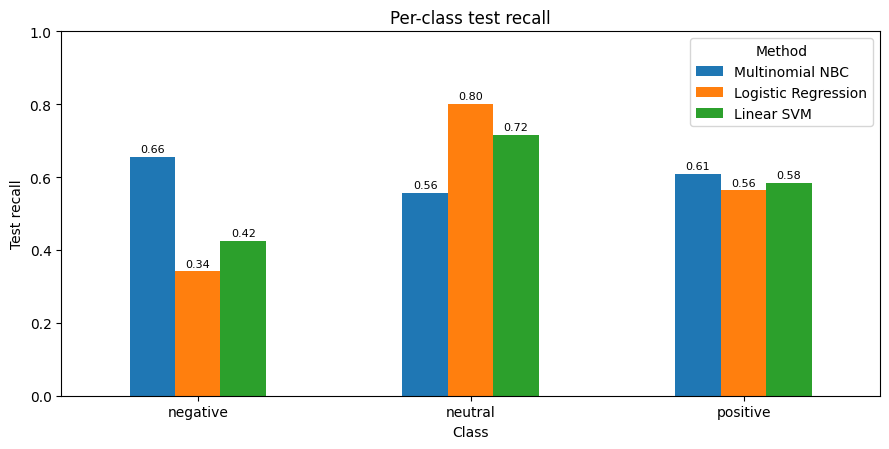

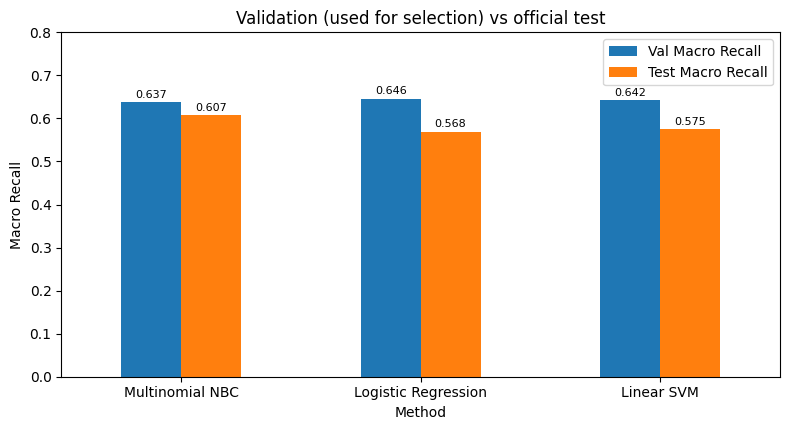

Per-class test metrics:


Precision                                         Recall  \
Method   Multinomial NBC Logistic Regression Linear SVM Multinomial NBC   
Class                                                                     
negative          0.5577              0.6995     0.6572          0.6558   
neutral           0.6554              0.5920     0.6042          0.5565   
positive          0.5626              0.5772     0.5158          0.6093   

                                                     F1                      \
Method   Logistic Regression Linear SVM Multinomial NBC Logistic Regression   
Class                                                                         
negative              0.3411     0.4247          0.6028              0.4586   
neutral               0.8004     0.7150          0.6019              0.6806   
positive              0.5638     0.5844          0.5850              0.5704   

                     
Method   Linear SVM  
Class                
negative     0.5160  
neutral      0.6549  
positive     0.5480


Multinomial NBC
              precision    recall  f1-score   support

    negative     0.5577    0.6558    0.6028      3972
     neutral     0.6554    0.5565    0.6019      5937
    positive     0.5626    0.6093    0.5850      2375

    accuracy                         0.5988     12284
   macro avg     0.5919    0.6072    0.5966     12284
weighted avg     0.6059    0.5988    0.5989     12284


Logistic Regression
              precision    recall  f1-score   support

    negative     0.6995    0.3411    0.4586      3972
     neutral     0.5920    0.8004    0.6806      5937
    positive     0.5772    0.5638    0.5704      2375

    accuracy                         0.6062     12284
   macro avg     0.6229    0.5684    0.5699     12284
weighted avg     0.6239    0.6062    0.5875     12284


Linear SVM
              precision    recall  f1-score   support

    negative     0.6572    0.4247    0.5160      3972
     neutral     0.6042    0.7150    0.6549      5937
    positive     0.5158  

In [ ]:
# Step 45. Per-class metrics, confusion matrices (counts and row-normalised) and summary figures
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

per_class_rows = []
for method_id, predicted in list(test_predictions.items()) + [("majority_baseline", baseline_pred)]:
    name = METHOD_NAMES.get(method_id, "Training-majority baseline")
    report = classification_report(y_test, predicted, labels=CLASS_LABELS, target_names=CLASS_NAMES,
                                   output_dict=True, zero_division=0)
    report_text = classification_report(y_test, predicted, labels=CLASS_LABELS, target_names=CLASS_NAMES,
                                        digits=4, zero_division=0)
    (C_DIR / "tables" / f"c09_test_report_{method_id}.txt").write_text(report_text, encoding="utf-8")
    for class_name in CLASS_NAMES:
        per_class_rows.append({"Method": name, "Class": class_name,
                               "Precision": report[class_name]["precision"],
                               "Recall": report[class_name]["recall"],
                               "F1": report[class_name]["f1-score"],
                               "Support": int(report[class_name]["support"]),
                               "Predicted count": int((predicted == CLASS_NAMES.index(class_name)).sum())})
    matrix = confusion_matrix(y_test, predicted, labels=CLASS_LABELS)
    pd.DataFrame(matrix, index=[f"true_{c}" for c in CLASS_NAMES],
                 columns=[f"pred_{c}" for c in CLASS_NAMES]).to_csv(
        C_DIR / "tables" / f"c10_test_confusion_{method_id}.csv")

per_class = pd.DataFrame(per_class_rows)
per_class.to_csv(C_DIR / "tables" / "c09_test_per_class.csv", index=False)

# Wide view: one row per class, columns per model, for the report.
per_class_wide = per_class[per_class["Method"] != "Training-majority baseline"].pivot(
    index="Class", columns="Method", values=["Precision", "Recall", "F1"]).reindex(CLASS_NAMES)
per_class_wide = per_class_wide.reindex(columns=[METHOD_NAMES[m] for m in METHOD_IDS], level=1)

# Figure 1: confusion matrices, counts (top) and row-normalised recall (bottom).
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for col, method_id in enumerate(METHOD_IDS):
    matrix = confusion_matrix(y_test, test_predictions[method_id], labels=CLASS_LABELS)
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(
        ax=axes[0, col], cmap="Blues", values_format="d", colorbar=False)
    axes[0, col].set_title(f"{METHOD_NAMES[method_id]} (counts)")
    normalised = matrix / matrix.sum(axis=1, keepdims=True)
    ConfusionMatrixDisplay(normalised, display_labels=CLASS_NAMES).plot(
        ax=axes[1, col], cmap="Greens", values_format=".2f", colorbar=False)
    axes[1, col].set_title(f"{METHOD_NAMES[method_id]} (row-normalised = recall)")
fig.suptitle("Official test set (n = 12,284): confusion matrices, class order [negative, neutral, positive]")
fig.tight_layout()
fig.savefig(C_DIR / "figures" / "c_fig1_test_confusion_matrices.png", dpi=170, bbox_inches="tight")
plt.show()

# Figure 2: overall test metrics including the baseline.
fig, ax = plt.subplots(figsize=(10, 4.8))
plot_df = test_results.set_index("Method")[["Macro Recall", "Macro F1", "Accuracy"]]
plot_df.plot.bar(ax=ax, rot=0, ylim=(0, 0.8))
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2)
ax.set_ylabel("Test score")
ax.set_title("Official test results vs training-majority baseline")
ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
fig.savefig(C_DIR / "figures" / "c_fig2_test_metrics_vs_baseline.png", dpi=170, bbox_inches="tight")
plt.show()

# Figure 3: per-class recall (shows where each model gains or loses).
fig, ax = plt.subplots(figsize=(9, 4.6))
recall_plot = per_class[per_class["Method"] != "Training-majority baseline"].pivot(
    index="Class", columns="Method", values="Recall").reindex(CLASS_NAMES)[[METHOD_NAMES[m] for m in METHOD_IDS]]
recall_plot.plot.bar(ax=ax, rot=0, ylim=(0, 1))
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylabel("Test recall")
ax.set_title("Per-class test recall")
fig.tight_layout()
fig.savefig(C_DIR / "figures" / "c_fig3_test_per_class_recall.png", dpi=170, bbox_inches="tight")
plt.show()

# Figure 4: validation vs test Macro Recall (generalisation gap).
fig, ax = plt.subplots(figsize=(8, 4.4))
gap_plot = generalisation_gap.set_index("Method")[["Val Macro Recall", "Test Macro Recall"]]
gap_plot.plot.bar(ax=ax, rot=0, ylim=(0, 0.8))
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylabel("Macro Recall")
ax.set_title("Validation (used for selection) vs official test")
fig.tight_layout()
fig.savefig(C_DIR / "figures" / "c_fig4_validation_vs_test.png", dpi=170, bbox_inches="tight")
plt.show()

print("Per-class test metrics:")
display(per_class_wide.round(4))
for method_id in METHOD_IDS:
    print(f"\n{METHOD_NAMES[method_id]}")
    print((C_DIR / "tables" / f"c09_test_report_{method_id}.txt").read_text(encoding="utf-8"))

## 46. Is the Difference Real? Bootstrap and McNemar Tests
Estimate 95% confidence intervals from 2,000 bootstrap resamples, compare models with paired differences and exact McNemar tests (Holm-corrected), and report how often the models agree.

In [ ]:
# Step 46. Reliability of the test results: bootstrap 95% confidence intervals, paired bootstrap differences,

from scipy.stats import binomtest

def metrics_from_labels(true_labels, predicted_labels):
    """Fast Macro Recall, Macro F1 and Accuracy from a 3x3 confusion matrix."""
    counts = np.bincount(true_labels * 3 + predicted_labels, minlength=9).reshape(3, 3)
    tp = np.diag(counts).astype(float)
    support, predicted_total = counts.sum(axis=1), counts.sum(axis=0)
    recall = np.divide(tp, support, out=np.zeros(3), where=support > 0)
    precision = np.divide(tp, predicted_total, out=np.zeros(3), where=predicted_total > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(3), where=(precision + recall) > 0)
    return recall.mean(), f1.mean(), tp.sum() / counts.sum()

# Sanity check against scikit-learn on the full test set.
for method_id in METHOD_IDS:
    fast = metrics_from_labels(y_test, test_predictions[method_id])
    full = score_predictions(y_test, test_predictions[method_id])
    np.testing.assert_allclose(fast, [full["Macro Recall"], full["Macro F1"], full["Accuracy"]], atol=1e-12)

systems = {METHOD_NAMES[m]: test_predictions[m] for m in METHOD_IDS}
systems["Training-majority baseline"] = baseline_pred
system_names = list(systems)
METRICS = ["Macro Recall", "Macro F1", "Accuracy"]

# 1) Bootstrap: resample the 12,284 test tweets with replacement, 2,000 times.
#    Every system is scored on the SAME resampled tweets, so differences are paired.
rng = np.random.default_rng(BOOTSTRAP_SEED)
n = len(y_test)
boot = np.zeros((BOOTSTRAP_RESAMPLES, len(system_names), len(METRICS)))
for b in range(BOOTSTRAP_RESAMPLES):
    idx = rng.integers(0, n, size=n)
    true_b = y_test[idx]
    for s, name in enumerate(system_names):
        boot[b, s] = metrics_from_labels(true_b, systems[name][idx])

# 2) 95% confidence interval = middle 95% of the 2,000 bootstrap scores.
ci_rows = []
for s, name in enumerate(system_names):
    point = metrics_from_labels(y_test, systems[name])
    row = {"System": name}
    for k, metric in enumerate(METRICS):
        low, high = np.percentile(boot[:, s, k], [2.5, 97.5])
        row[metric] = point[k]
        row[f"{metric} 95% CI"] = f"[{low:.4f}, {high:.4f}]"
    ci_rows.append(row)
bootstrap_ci = pd.DataFrame(ci_rows)
bootstrap_ci.to_csv(C_DIR / "tables" / "c11_bootstrap_ci.csv", index=False)

# 3) Paired differences (first minus second). If the 95% CI excludes 0, the difference is reliable.
pairs = [("Multinomial NBC", "Logistic Regression"), ("Multinomial NBC", "Linear SVM"),
         ("Linear SVM", "Logistic Regression")] + [
        (METHOD_NAMES[m], "Training-majority baseline") for m in METHOD_IDS]
diff_rows = []
for a, b_name in pairs:
    ia, ib = system_names.index(a), system_names.index(b_name)
    row = {"Comparison": f"{a} - {b_name}"}
    for k, metric in enumerate(METRICS):
        delta = boot[:, ia, k] - boot[:, ib, k]
        low, high = np.percentile(delta, [2.5, 97.5])
        point = metrics_from_labels(y_test, systems[a])[k] - metrics_from_labels(y_test, systems[b_name])[k]
        row[f"{metric} diff"] = point
        row[f"{metric} 95% CI"] = f"[{low:+.4f}, {high:+.4f}]"
        row[f"{metric} reliable"] = bool(low > 0 or high < 0)
    diff_rows.append(row)
paired_differences = pd.DataFrame(diff_rows)
paired_differences.to_csv(C_DIR / "tables" / "c12_paired_bootstrap_differences.csv", index=False)

# 4) Exact McNemar test for each pair of the three models.

def exact_mcnemar(correct_a, correct_b):
    n01 = int(np.sum(correct_a & ~correct_b))
    n10 = int(np.sum(~correct_a & correct_b))
    discordant = n01 + n10
    p_value = binomtest(min(n01, n10), discordant, 0.5, alternative="two-sided").pvalue if discordant else 1.0
    return n01, n10, float(p_value)

def holm_adjust(p_values):
    """Holm step-down adjustment: controls the family-wise error rate over the listed comparisons."""
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    m = len(p_values)
    adjusted = np.empty(m)
    running_max = 0.0
    for rank, idx in enumerate(order):
        running_max = max(running_max, min(1.0, (m - rank) * p_values[idx]))
        adjusted[idx] = running_max
    return adjusted

correct = {METHOD_NAMES[m]: test_predictions[m] == y_test for m in METHOD_IDS}
mcnemar_rows = []
for a, b_name in [("Multinomial NBC", "Logistic Regression"), ("Multinomial NBC", "Linear SVM"),
                  ("Linear SVM", "Logistic Regression")]:
    n01, n10, p_value = exact_mcnemar(correct[a], correct[b_name])
    mcnemar_rows.append({"Comparison": f"{a} vs {b_name}",
                         "First right, second wrong (n01)": n01,
                         "First wrong, second right (n10)": n10,
                         "Accuracy diff (first - second)": (n01 - n10) / len(y_test),
                         "Exact p-value": p_value})
mcnemar_tests = pd.DataFrame(mcnemar_rows)
mcnemar_tests["Holm-adjusted p-value"] = holm_adjust(mcnemar_tests["Exact p-value"])
mcnemar_tests["Significant at 0.05 (Holm)"] = mcnemar_tests["Holm-adjusted p-value"] < 0.05
mcnemar_tests.to_csv(C_DIR / "tables" / "c13_mcnemar_tests.csv", index=False)

# Consistency check: the McNemar accuracy difference must equal the directly computed accuracy difference.
for row in mcnemar_rows:
    a, b_name = row["Comparison"].split(" vs ")
    direct = correct[a].mean() - correct[b_name].mean()
    np.testing.assert_allclose(row["Accuracy diff (first - second)"], direct, atol=1e-12)

# 5) Agreement among the three models (used again in Steps 47, 49 and 52).
agree_all = (test_predictions["multinomial_nb"] == test_predictions["logistic_regression"]) & \
            (test_predictions["logistic_regression"] == test_predictions["linear_svm"])
all_wrong = ~correct["Multinomial NBC"] & ~correct["Logistic Regression"] & ~correct["Linear SVM"]
any_right = correct["Multinomial NBC"] | correct["Logistic Regression"] | correct["Linear SVM"]

print(f"Bootstrap 95% confidence intervals ({BOOTSTRAP_RESAMPLES:,} resamples, seed {BOOTSTRAP_SEED}):")
display(bootstrap_ci.round(4))
print("Paired differences (first minus second); 'reliable' = 95% CI excludes 0:")
with pd.option_context("display.max_columns", 20, "display.width", 250):
    display(paired_differences.round(4))
print("Exact McNemar tests on the three model pairs (error-rate comparison), Holm-corrected:")
with pd.option_context("display.max_columns", 20, "display.width", 250):
    display(mcnemar_tests.round(6))
print(f"All three models agree on {agree_all.mean():.1%} of test records.")
print(f"All three are wrong on {all_wrong.sum()} records ({all_wrong.mean():.1%}); "
      f"at least one is right on {any_right.mean():.1%} (an upper bound for simple model combination).")

Bootstrap 95% confidence intervals (2,000 resamples, seed 323):


,System,Macro Recall,Macro Recall 95% CI,Macro F1,Macro F1 95% CI,Accuracy,Accuracy 95% CI
0,Multinomial NBC,0.6072,"[0.5976, 0.6162]",0.5966,"[0.5870, 0.6052]",0.5988,"[0.5896, 0.6071]"
1,Logistic Regression,0.5684,"[0.5590, 0.5770]",0.5699,"[0.5598, 0.5791]",0.6062,"[0.5968, 0.6145]"
2,Linear SVM,0.5747,"[0.5655, 0.5838]",0.5730,"[0.5638, 0.5822]",0.5959,"[0.5873, 0.6044]"
3,Training-majority baseline,0.3333,"[0.3333, 0.3333]",0.2172,"[0.2144, 0.2198]",0.4833,"[0.4740, 0.4919]"


Paired differences (first minus second); 'reliable' = 95% CI excludes 0:


,Comparison,Macro Recall diff,Macro Recall 95% CI,Macro Recall reliable,Macro F1 diff,Macro F1 95% CI,Macro F1 reliable,Accuracy diff,Accuracy 95% CI,Accuracy reliable
0,Multinomial NBC - Logistic Regression,0.0388,"[+0.0295, +0.0476]",True,0.0267,"[+0.0171, +0.0362]",True,-0.0073,"[-0.0168, +0.0024]",False
1,Multinomial NBC - Linear SVM,0.0325,"[+0.0235, +0.0417]",True,0.0236,"[+0.0142, +0.0332]",True,0.0029,"[-0.0066, +0.0127]",False
2,Linear SVM - Logistic Regression,0.0063,"[-0.0015, +0.0145]",False,0.0031,"[-0.0050, +0.0116]",False,-0.0103,"[-0.0176, -0.0025]",True
3,Multinomial NBC - Training-majority baseline,0.2739,"[+0.2642, +0.2829]",True,0.3794,"[+0.3688, +0.3888]",True,0.1155,"[+0.1027, +0.1288]",True
4,Logistic Regression - Training-majority baseline,0.2351,"[+0.2256, +0.2437]",True,0.3527,"[+0.3424, +0.3620]",True,0.1228,"[+0.1128, +0.1329]",True
5,Linear SVM - Training-majority baseline,0.2414,"[+0.2321, +0.2505]",True,0.3557,"[+0.3462, +0.3654]",True,0.1126,"[+0.1021, +0.1237]",True


Exact McNemar tests on the three model pairs (error-rate comparison), Holm-corrected:


,Comparison,"First right, second wrong (n01)","First wrong, second right (n10)",Accuracy diff (first - second),Exact p-value,Holm-adjusted p-value,Significant at 0.05 (Holm)
0,Multinomial NBC vs Logistic Regression,1758,1848,-0.007327,0.138303,0.276606,False
1,Multinomial NBC vs Linear SVM,1801,1765,0.002931,0.557809,0.557809,False
2,Linear SVM vs Logistic Regression,1059,1185,-0.010257,0.008307,0.024921,True


All three models agree on 57.6% of test records.
All three are wrong on 2617 records (21.3%); at least one is right on 78.7% (an upper bound for simple model combination).


## 47. Error Analysis by Predefined Slices
Report the error rate and Macro Recall of each model on slices fixed in the evaluation plan: negation, contrast, sarcasm markers, questions, exclamations, emoji, short tweets, high out-of-vocabulary tweets and all-zero vectors.

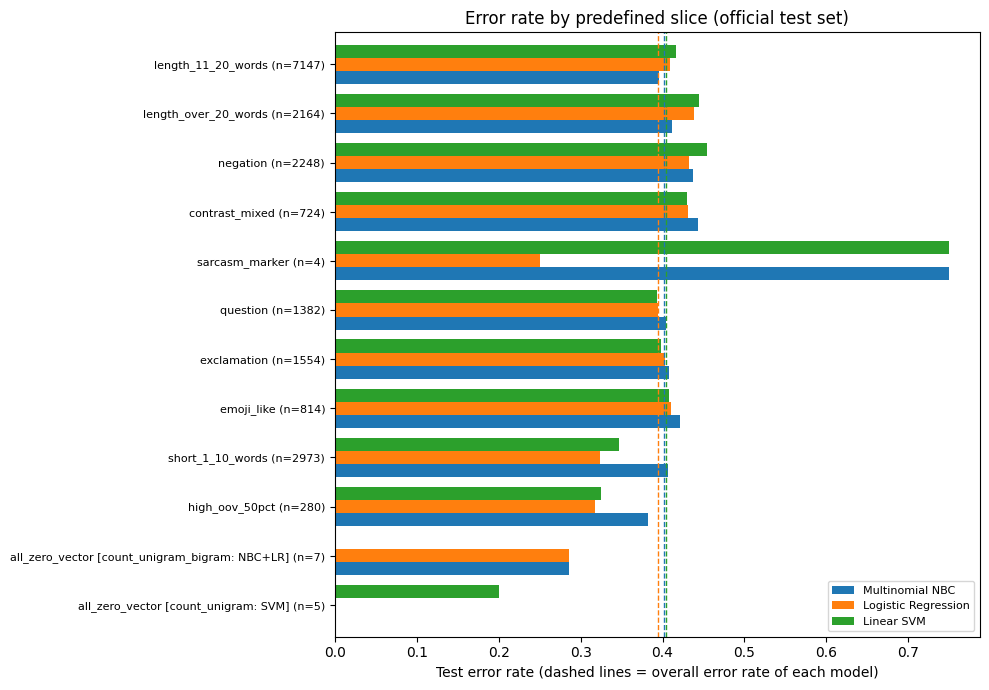

Slice summary (one row = one set of records; Err = error rate, ΔErr = change vs overall,
MacroR = Macro Recall over classes present; blank = model not evaluated on that record set):


,Models,n,True neg %,True neu %,True pos %,Err Multinomial NBC,Err Logistic Regression,Err Linear SVM,ΔErr Multinomial NBC,ΔErr Logistic Regression,ΔErr Linear SVM,MacroR Multinomial NBC,MacroR Logistic Regression,MacroR Linear SVM,All three wrong %,Small sample (n<100)
Slice,,,,,,,,,,,,,,,,
overall,NBC+LR+SVM,12284,32.3,48.3,19.3,0.401,0.394,0.404,0.000,0.000,0.000,0.607,0.568,0.575,21.304,False
length_11_20_words,NBC+LR+SVM,7147,33.1,48.6,18.4,0.396,0.409,0.416,-0.005,0.015,0.012,0.608,0.557,0.567,21.589,False
length_over_20_words,NBC+LR+SVM,2164,49.4,35.0,15.7,0.412,0.439,0.445,0.011,0.045,0.040,0.558,0.585,0.576,22.921,False
negation,NBC+LR+SVM,2248,49.4,40.4,10.1,0.437,0.433,0.455,0.036,0.039,0.051,0.531,0.554,0.545,22.642,False
contrast_mixed,NBC+LR+SVM,724,41.7,43.5,14.8,0.443,0.431,0.430,0.042,0.037,0.025,0.557,0.557,0.565,19.890,False
sarcasm_marker,NBC+LR+SVM,4,50.0,25.0,25.0,0.750,0.250,0.750,0.349,-0.144,0.346,0.167,0.833,0.333,25.000,True
question,NBC+LR+SVM,1382,41.8,49.9,8.4,0.404,0.394,0.393,0.003,0.001,-0.011,0.558,0.537,0.565,19.899,False
exclamation,NBC+LR+SVM,1554,28.8,31.8,39.4,0.408,0.403,0.398,0.007,0.010,-0.006,0.574,0.573,0.584,24.196,False
emoji_like,NBC+LR+SVM,814,23.0,33.2,43.9,0.421,0.410,0.408,0.020,0.016,0.004,0.578,0.572,0.578,23.464,False


Negative recall by slice:


Method,Multinomial NBC,Logistic Regression,Linear SVM
Row,,,
overall,0.656,0.341,0.425
length_11_20_words,0.644,0.302,0.412
length_over_20_words,0.758,0.506,0.537
negation,0.791,0.566,0.545
contrast_mixed,0.825,0.457,0.500
sarcasm_marker,0.500,0.500,0.000
question,0.653,0.359,0.419
exclamation,0.579,0.360,0.436
emoji_like,0.663,0.406,0.444


Share of predictions that are neutral (%), by slice:


Method,Multinomial NBC,Logistic Regression,Linear SVM
Row,,,
overall,41.0,65.3,57.2
length_11_20_words,42.8,66.1,57.1
length_over_20_words,26.1,46.3,39.9
negation,21.3,45.3,43.1
contrast_mixed,20.6,55.8,49.4
sarcasm_marker,25.0,50.0,100.0
question,44.1,71.6,63.5
exclamation,20.3,36.5,36.9
emoji_like,27.4,52.8,50.2


Slices are hypotheses defined before testing; overlaps exist and differences in label mix
between slices can also change error rates. Small slices (n<100) should be interpreted cautiously.


In [ ]:
# Step 47. Error analysis on the slices frozen in Step 43 (negation, contrast/mixed, sarcasm, emoji, short, OOV, all-zero)
assert sha256_file(plan_path) == EVALUATION_PLAN_SHA256, "Evaluation plan changed after freezing."

SHORT_NAMES = {"multinomial_nb": "NBC", "logistic_regression": "LR", "linear_svm": "SVM"}

def as_bool(series):
    return series.astype(str).str.strip().str.lower().eq("true").to_numpy()


diag_all = pd.read_csv(A_DIR / "checks" / "record_diagnostics.csv", keep_default_na=False)
diag_test = test_df[["row_id"]].merge(diag_all.loc[diag_all["split"] == "test"],
                                      on="row_id", how="left", validate="one_to_one")
assert len(diag_test) == len(test_df)
np.testing.assert_array_equal(diag_test["label"].astype(int).to_numpy(), y_test)

# 2) Slice membership, using exactly the rules frozen in Step 43.
normalised_test = test_df["text"].map(text_features.normalise_text)
slice_masks = {name: normalised_test.str.contains(pattern, regex=True).to_numpy()
               for name, pattern in SLICE_PATTERNS.items()}
slice_masks["emoji_like"] = as_bool(diag_test["has_emoji_like_symbol"])
slice_masks["short_1_10_words"] = (diag_test["length_group"].astype(str) == "1-10").to_numpy()
slice_masks["high_oov_50pct"] = (diag_test["outside_vocabulary_percent"].astype(float) >= 50).to_numpy()
slice_masks["all_zero_vector"] = {   # model-specific: each model uses its own feature configuration
    m: as_bool(diag_test[f"all_zero_{selected['models'][m]['feature_configuration']}"]) for m in METHOD_IDS}
for m in METHOD_IDS:   # cross-check against the matrices verified in Step 42
    np.testing.assert_array_equal(slice_masks["all_zero_vector"][m], X_test[m].getnnz(axis=1) == 0)

# Context rows (not hypotheses): overall and the other two length groups.
context_masks = {
    "overall": np.ones(len(y_test), dtype=bool),
    "length_11_20_words": (diag_test["length_group"].astype(str) == "11-20").to_numpy(),
    "length_over_20_words": (diag_test["length_group"].astype(str) == ">20").to_numpy(),
}
SLICE_TYPE = {**{k: "context" for k in context_masks},
              **{k: "regex rule (C4)" for k in SLICE_PATTERNS},
              **{k: "A diagnostic (C4)" for k in SLICE_FROM_A_DIAGNOSTICS}}

correct_by_model = {m: test_predictions[m] == y_test for m in METHOD_IDS}
all_wrong = (~correct_by_model["multinomial_nb"] & ~correct_by_model["logistic_regression"]
             & ~correct_by_model["linear_svm"])

def expand_slice(name, spec):
    """Turn one slice into report rows so that every row describes exactly ONE set of records."""

    if not isinstance(spec, dict):
        return [{"Row": name, "Slice": name, "mask": spec, "models": list(METHOD_IDS)}]
    groups = {}
    for m in METHOD_IDS:
        groups.setdefault(selected["models"][m]["feature_configuration"], []).append(m)
    rows = []
    for feature, models in groups.items():
        mask = spec[models[0]]
        for other in models[1:]:
            np.testing.assert_array_equal(spec[other], mask)   # same vocabulary -> same records
        label = f"{name} [{feature}: {'+'.join(SHORT_NAMES[m] for m in models)}]"
        rows.append({"Row": label, "Slice": name, "mask": mask, "models": models})
    return rows

slice_rows = [row for name, spec in {**context_masks, **slice_masks}.items() for row in expand_slice(name, spec)]
row_order = [row["Row"] for row in slice_rows]
assert len(row_order) == len(set(row_order))

def macro_recall_present(true_labels, predicted_labels):
    """Average recall over the classes that actually occur in the slice (avoids zero-support classes)."""
    present = np.unique(true_labels)
    return recall_score(true_labels, predicted_labels, labels=present, average="macro", zero_division=0)

# 3) One description per row (same records for every model in that row) ...
row_info, rows = [], []
for spec in slice_rows:
    mask = spec["mask"]
    n = int(mask.sum())
    if n == 0:
        continue
    t = y_test[mask]
    row_info.append({
        "Row": spec["Row"], "Slice": spec["Slice"], "Type": SLICE_TYPE[spec["Slice"]],
        "Models": "+".join(SHORT_NAMES[m] for m in spec["models"]), "n": n,
        "Share %": 100 * n / len(y_test),
        "True neg %": 100 * np.mean(t == 0), "True neu %": 100 * np.mean(t == 1), "True pos %": 100 * np.mean(t == 2),
        "All three wrong %": 100 * float(np.mean(all_wrong[mask])),
        "Small sample (n<100)": n < 100,
    })
    # ... and one score line per model evaluated on that row.
    for method_id in spec["models"]:
        p = test_predictions[method_id][mask]
        rows.append({
            "Row": spec["Row"], "Slice": spec["Slice"], "Type": SLICE_TYPE[spec["Slice"]],
            "Method": METHOD_NAMES[method_id], "n": n,
            "Error rate": float(np.mean(t != p)),
            "Macro Recall (classes present)": macro_recall_present(t, p),
            "Negative recall": float(np.mean(p[t == 0] == 0)) if np.any(t == 0) else np.nan,
            "Pred neutral %": 100 * float(np.mean(p == 1)),
        })
row_info = pd.DataFrame(row_info).set_index("Row")
slice_long = pd.DataFrame(rows)
slice_long.to_csv(C_DIR / "errors" / "c14_slice_metrics_long.csv", index=False)
row_order = [r for r in row_order if r in row_info.index]

# 4) Wide views for the report: error rate and Macro Recall by row x model, plus change vs overall.
method_order = [METHOD_NAMES[m] for m in METHOD_IDS]

def wide(value):
    return slice_long.pivot(index="Row", columns="Method", values=value).reindex(row_order)[method_order]

slice_sizes = row_info["n"].reindex(row_order)
error_wide = wide("Error rate")
error_vs_overall = error_wide - error_wide.loc["overall"]
recall_wide = wide("Macro Recall (classes present)")
negrecall_wide = wide("Negative recall")
neutral_wide = wide("Pred neutral %")

slice_table = (row_info.reindex(row_order)[["Models", "n", "True neg %", "True neu %", "True pos %"]].round(1)
               .join(error_wide.add_prefix("Err "))
               .join(error_vs_overall.add_prefix("ΔErr "))
               .join(recall_wide.add_prefix("MacroR "))
               .join(row_info[["All three wrong %", "Small sample (n<100)"]]))
slice_table.index.name = "Slice"
slice_table.to_csv(C_DIR / "errors" / "c15_slice_summary.csv")
neutral_wide.to_csv(C_DIR / "errors" / "c16_slice_pred_neutral_rate.csv")
negrecall_wide.to_csv(C_DIR / "errors" / "c16b_slice_negative_recall.csv")

# Save per-record slice flags for later cells (Steps 48-49).
slice_flags = test_df[["row_id"]].copy()
for name, spec in slice_masks.items():
    if isinstance(spec, dict):
        for m in METHOD_IDS:
            slice_flags[f"{name}_{m}"] = spec[m]
    else:
        slice_flags[name] = spec
slice_flags["all_three_wrong"] = all_wrong
slice_flags.to_csv(C_DIR / "errors" / "c17_test_slice_flags.csv", index=False)

# 5) Figure: error rate per row and model, with the overall error rate marked.
fig, ax = plt.subplots(figsize=(10, 7))
plot_err = error_wide.drop(index="overall").iloc[::-1]
plot_err.index = [f"{name} (n={slice_sizes[name]})" for name in plot_err.index]
plot_err.plot.barh(ax=ax, width=0.8)
for color, m in zip(plt.rcParams["axes.prop_cycle"].by_key()["color"], method_order):
    ax.axvline(error_wide.loc["overall", m], color=color, linestyle="--", linewidth=1)
ax.set_xlabel("Test error rate (dashed lines = overall error rate of each model)")
ax.set_title("Error rate by predefined slice (official test set)")
ax.tick_params(axis="y", labelsize=8)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(C_DIR / "figures" / "c_fig5_error_rate_by_slice.png", dpi=170, bbox_inches="tight")
plt.show()

print("Slice summary (one row = one set of records; Err = error rate, ΔErr = change vs overall,")
print("MacroR = Macro Recall over classes present; blank = model not evaluated on that record set):")
with pd.option_context("display.max_columns", 30, "display.width", 250):
    display(slice_table.round(3))
print("Negative recall by slice:")
display(negrecall_wide.round(3))
print("Share of predictions that are neutral (%), by slice:")
display(neutral_wide.round(1))
print("Slices are hypotheses defined before testing; overlaps exist and differences in label mix")
print("between slices can also change error rates. Small slices (n<100) should be interpreted cautiously.")

## 48. Marginal Cases
Define a marginal case as a test tweet in the lowest 10% of a model's margin (the gap between its two highest class scores). Compare errors near and far from the decision boundary, the competing classes and the overlap between models. Course link: Lecture 2, pp. 22–23 (score and margin).

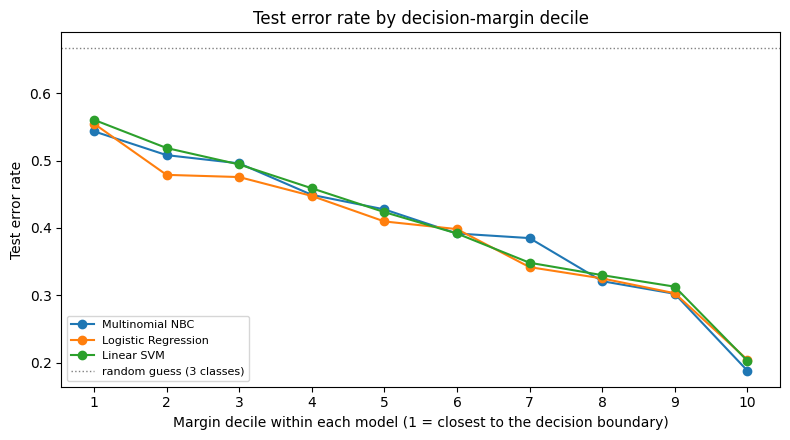

Marginal-case summary (lowest 10% margin within each model):


,Method,Margin type,10th-percentile threshold,Marginal n,Error rate (marginal),Error rate (other records),Errors that are marginal %,Prob gap < 0.10 n,Error rate (prob gap < 0.10),Mean max prob (correct),Mean max prob (wrong),Confident errors (max prob >= 0.9) n,Confident errors % of errors
0,Multinomial NBC,probability gap,0.181,1229,0.544,0.385,13.555,657.0,0.559,0.867,0.804,2084.0,42.289
1,Logistic Regression,probability gap,0.074,1229,0.555,0.376,14.097,1669.0,0.531,0.648,0.590,48.0,0.992
2,Linear SVM,decision-score gap,0.113,1229,0.561,0.387,13.880,NaN,NaN,NaN,NaN,NaN,NaN


Signed margin m = s_true - max_other (negative = misclassified; NB/LR in log-odds, SVM in score units):


,Method,Margin units,Negative-margin %,Error rate %,Ties (|margin| <= 1e-9),Median margin (correct),Median margin (wrong),"Mean margin, true negative","Mean margin, true neutral","Mean margin, true positive"
0,Multinomial NBC,log-odds (log posterior),40.117,40.117,0,3.021,-2.330,2.067,0.180,1.980
1,Logistic Regression,log-odds (log posterior),39.385,39.385,0,0.960,-0.839,-0.370,0.658,0.504
2,Linear SVM,decision-score units,40.410,40.410,0,0.715,-0.588,-0.078,0.366,0.354


Which classes compete in marginal cases:


% of marginal                                      \
Method               Linear SVM Logistic Regression Multinomial NBC   
Competing classes                                                     
negative/neutral           45.8                45.4            48.7   
negative/positive          13.2                 7.3            15.9   
neutral/positive           41.0                47.3            35.5   

                  Error rate                                      
Method            Linear SVM Logistic Regression Multinomial NBC  
Competing classes                                                 
negative/neutral         0.5                 0.5             0.5  
negative/positive        0.7                 0.6             0.7  
neutral/positive         0.6                 0.6             0.5

... (5 outputs left out)

Method,n,Multinomial NBC,Logistic Regression,Linear SVM
Slice,,,,
negation,2248,0.70,1.35,1.14
contrast_mixed,724,0.90,0.95,0.97
sarcasm_marker,4,0.00,2.50,0.00
question,1382,0.84,0.98,0.94
exclamation,1554,0.74,1.32,1.00
emoji_like,814,1.11,1.02,0.92
short_1_10_words,2973,1.72,0.92,0.93
high_oov_50pct,280,3.28,0.71,0.68
all_zero_vector [count_unigram_bigram: NBC+LR],7,10.00,0.00,NaN


All-zero vectors: prediction decided only by prior / intercepts


,Method,All-zero records,Rule,Matches rule,"Scores [neg, neu, pos]",Always predicts,Correct
0,Multinomial NBC,7,posterior = class prior P(c),True,"[0.1555, 0.4532, 0.3913]",neutral,5/7
1,Logistic Regression,7,probability = softmax(intercepts),True,"[0.1472, 0.5931, 0.2597]",neutral,5/7
2,Linear SVM,5,decision score = intercepts b_c,True,"[-0.6619, 0.162, -0.4496]",neutral,4/5


,row_id,text,true_sentiment,Multinomial NBC,Multinomial NBC all-zero,Logistic Regression,Logistic Regression all-zero,Linear SVM,Linear SVM all-zero
801,test_000801,DolarToday,neutral,neutral,True,neutral,True,neutral,True
3894,test_003894,Shadows #mannequinchallenge #columbusohio #columbusdogs #labradorretriever,neutral,neutral,True,neutral,True,neutral,False
5594,test_005594,Tipp 28Fairmont 38Final,neutral,neutral,True,neutral,True,neutral,True
9095,test_009095,waaant,positive,neutral,True,neutral,True,neutral,True
10310,test_010310,Daddyyyy👅🙈💕#MPN #OneDirection,positive,neutral,True,neutral,True,neutral,False
10754,test_010754,GBB UpdateTipp 18Fairmont 21Half,neutral,neutral,True,neutral,True,neutral,True
10936,test_010936,Zayday #ScreamQueens,neutral,neutral,True,neutral,True,neutral,True


In [ ]:
# Step 48. Marginal (boundary) cases, using the definition frozen in Step 43, plus the signed margin of each record
from collections import Counter
from scipy.special import softmax

assert sha256_file(plan_path) == EVALUATION_PLAN_SHA256, "Evaluation plan changed after freezing."

margins, marginal_masks, competing_pairs = {}, {}, {}
summary_rows, pair_rows, decile_rows = [], [], []

for m in METHOD_IDS:
    values = test_scores_raw[m]["values"]          # NB/LR: probabilities, SVM: decision scores
    kind = test_scores_raw[m]["kind"]
    order_idx = np.argsort(values, axis=1)
    first, second = order_idx[:, -1], order_idx[:, -2]
    idx = np.arange(len(values))
    gap = values[idx, first] - values[idx, second]  # distance between the two strongest classes (frozen Step 43 rule)
    threshold = float(np.quantile(gap, MARGINAL_QUANTILE))
    is_marginal = gap <= threshold
    wrong = ~correct_by_model[m]
    pair = np.array([f"{CLASS_NAMES[min(a, b)]}/{CLASS_NAMES[max(a, b)]}" for a, b in zip(first, second)])
    margins[m], marginal_masks[m], competing_pairs[m] = gap, is_marginal, pair

    row = {"Method": METHOD_NAMES[m],
           "Margin type": "probability gap" if kind == "probability" else "decision-score gap",
           "10th-percentile threshold": threshold,
           "Marginal n": int(is_marginal.sum()),
           "Error rate (marginal)": float(wrong[is_marginal].mean()),
           "Error rate (other records)": float(wrong[~is_marginal].mean()),
           "Errors that are marginal %": 100 * float((wrong & is_marginal).sum() / wrong.sum())}
    if kind == "probability":
        max_prob = values.max(axis=1)
        small = gap < PROBABILITY_MARGIN_THRESHOLD
        confident_wrong = wrong & (max_prob >= 0.9)
        row.update({
            "Prob gap < 0.10 n": int(small.sum()),
            "Error rate (prob gap < 0.10)": float(wrong[small].mean()),
            "Mean max prob (correct)": float(max_prob[~wrong].mean()),
            "Mean max prob (wrong)": float(max_prob[wrong].mean()),
            "Confident errors (max prob >= 0.9) n": int(confident_wrong.sum()),
            "Confident errors % of errors": 100 * float(confident_wrong.sum() / wrong.sum()),
        })
    summary_rows.append(row)

    # Which two classes compete in the marginal cases?
    for name, count in Counter(pair[is_marginal]).most_common():
        pair_rows.append({"Method": METHOD_NAMES[m], "Competing classes": name,
                          "% of marginal": 100 * count / is_marginal.sum(),
                          "Error rate": float(wrong[is_marginal & (pair == name)].mean())})

    # Error rate by margin decile (1 = closest to the decision boundary).
    deciles = pd.qcut(pd.Series(gap).rank(method="first"), 10, labels=range(1, 11)).to_numpy()
    for d in range(1, 11):
        sel = deciles == d
        decile_rows.append({"Method": METHOD_NAMES[m], "Decile": d, "Error rate": float(wrong[sel].mean())})

marginal_summary = pd.DataFrame(summary_rows)
marginal_pairs = pd.DataFrame(pair_rows).pivot(index="Competing classes", columns="Method",
                                               values=["% of marginal", "Error rate"])
marginal_deciles = pd.DataFrame(decile_rows).pivot(index="Decile", columns="Method", values="Error rate")[method_order]
marginal_summary.to_csv(C_DIR / "errors" / "c18_marginal_summary.csv", index=False)
marginal_pairs.to_csv(C_DIR / "errors" / "c19_marginal_competing_classes.csv")
marginal_deciles.to_csv(C_DIR / "errors" / "c20_error_rate_by_margin_decile.csv")

# Signed margin of each record: score of the TRUE class minus the best score of any other class.

def signed_margin(scores, true_labels):
    idx = np.arange(len(true_labels))
    true_score = scores[idx, true_labels]
    others = scores.copy()
    others[idx, true_labels] = -np.inf
    return true_score - others.max(axis=1)

signed_scores = {
    "multinomial_nb": bundles["multinomial_nb"]["classifier"].predict_log_proba(X_test["multinomial_nb"]),
    "logistic_regression": bundles["logistic_regression"]["classifier"].predict_log_proba(X_test["logistic_regression"]),
    "linear_svm": test_scores_raw["linear_svm"]["values"],
}
signed_margins, signed_rows = {}, []
for m in METHOD_IDS:
    sm = signed_margin(signed_scores[m], y_test)
    signed_margins[m] = sm
    wrong = ~correct_by_model[m]

    # A tolerance keeps floating-point near-ties out of the check; those are counted as ties instead.
    tie = np.abs(sm) <= 1e-9
    assert np.all(wrong[(sm < 0) & ~tie]) and not np.any(wrong[(sm > 0) & ~tie]), m
    row = {"Method": METHOD_NAMES[m],
           "Margin units": "log-odds (log posterior)" if m != "linear_svm" else "decision-score units",
           "Negative-margin %": 100 * float(np.mean((sm < 0) & ~tie)),
           "Error rate %": 100 * float(wrong.mean()),
           "Ties (|margin| <= 1e-9)": int(tie.sum()),
           "Median margin (correct)": float(np.median(sm[~wrong])),
           "Median margin (wrong)": float(np.median(sm[wrong]))}
    for c, name in zip(CLASS_LABELS, CLASS_NAMES):
        row[f"Mean margin, true {name}"] = float(sm[y_test == c].mean())
    signed_rows.append(row)
signed_margin_summary = pd.DataFrame(signed_rows)
signed_margin_summary.to_csv(C_DIR / "errors" / "c18b_signed_margin_summary.csv", index=False)

# Do the three models find the same records difficult?
overlap_rows = []
for a, b in [("multinomial_nb", "logistic_regression"), ("multinomial_nb", "linear_svm"),
             ("logistic_regression", "linear_svm")]:
    A, B = marginal_masks[a], marginal_masks[b]
    overlap_rows.append({"Pair": f"{METHOD_NAMES[a]} & {METHOD_NAMES[b]}",
                         "Both marginal": int((A & B).sum()), "Jaccard overlap": float((A & B).sum() / (A | B).sum())})
marginal_overlap = pd.DataFrame(overlap_rows)
marginal_overlap.to_csv(C_DIR / "errors" / "c21_marginal_overlap.csv", index=False)
marginal_all3 = marginal_masks["multinomial_nb"] & marginal_masks["logistic_regression"] & marginal_masks["linear_svm"]

# Which slices are over-represented among marginal cases? Lift > 1 means over-represented.

lift_rows = []
for spec in slice_rows:
    if spec["Slice"] not in slice_masks:
        continue
    mask = spec["mask"]
    if mask.sum() == 0:
        continue
    for m in spec["models"]:
        lift_rows.append({"Row": spec["Row"], "Method": METHOD_NAMES[m], "n": int(mask.sum()),
                          "Lift": float(mask[marginal_masks[m]].mean() / mask.mean())})
lift_long = pd.DataFrame(lift_rows)
lift_order = [r for r in row_order if r in set(lift_long["Row"])]
marginal_lift = lift_long.pivot(index="Row", columns="Method", values="Lift").reindex(lift_order)[method_order]
marginal_lift.insert(0, "n", lift_long.drop_duplicates("Row").set_index("Row")["n"].reindex(lift_order))
marginal_lift.index.name = "Slice"
marginal_lift.to_csv(C_DIR / "errors" / "c22_marginal_slice_lift.csv")

# Degenerate boundary: all-zero vectors are decided only by the prior / intercepts.
zero_rows = []
for m in METHOD_IDS:
    clf = bundles[m]["classifier"]
    zero_idx = np.flatnonzero(X_test[m].getnnz(axis=1) == 0)
    observed = test_scores_raw[m]["values"][zero_idx]
    if m == "multinomial_nb":
        expected, rule = np.exp(clf.class_log_prior_), "posterior = class prior P(c)"
    elif m == "logistic_regression":
        expected, rule = softmax(clf.intercept_), "probability = softmax(intercepts)"
    else:
        expected, rule = clf.intercept_, "decision score = intercepts b_c"
    zero_rows.append({"Method": METHOD_NAMES[m], "All-zero records": len(zero_idx), "Rule": rule,
                      "Matches rule": bool(np.allclose(observed, expected[None, :], atol=1e-9)),
                      "Scores [neg, neu, pos]": np.round(expected, 4).tolist(),
                      "Always predicts": CLASS_NAMES[int(np.argmax(expected))],
                      "Correct": f"{int(correct_by_model[m][zero_idx].sum())}/{len(zero_idx)}"})
zero_vector_check = pd.DataFrame(zero_rows)
zero_vector_check.to_csv(C_DIR / "errors" / "c23_all_zero_vector_rule.csv", index=False)

any_zero = np.zeros(len(y_test), dtype=bool)
for m in METHOD_IDS:
    any_zero |= X_test[m].getnnz(axis=1) == 0
zero_examples = prediction_table.loc[any_zero, ["row_id", "text", "true_sentiment"]].copy()
for m in METHOD_IDS:
    zero_examples[f"{METHOD_NAMES[m]}"] = pd.Series(test_predictions[m][any_zero]).map(LABEL_MAPPING).to_numpy()
    zero_examples[f"{METHOD_NAMES[m]} all-zero"] = (X_test[m].getnnz(axis=1) == 0)[any_zero]

# Save every record that is marginal for at least one model, for Step 49.
any_marginal = marginal_masks["multinomial_nb"] | marginal_masks["logistic_regression"] | marginal_masks["linear_svm"]
marginal_records = prediction_table.loc[any_marginal, ["row_id", "text", "true_label", "true_sentiment"]].copy()
for m in METHOD_IDS:
    marginal_records[f"pred_{m}"] = test_predictions[m][any_marginal]
    marginal_records[f"margin_{m}"] = margins[m][any_marginal]
    marginal_records[f"signed_margin_{m}"] = signed_margins[m][any_marginal]
    marginal_records[f"marginal_{m}"] = marginal_masks[m][any_marginal]
    marginal_records[f"top2_{m}"] = competing_pairs[m][any_marginal]
marginal_records["all_three_wrong"] = all_wrong[any_marginal]
marginal_records.to_csv(C_DIR / "errors" / "c24_marginal_records.csv", index=False)

# Figure: error rate by margin decile.
RANDOM_GUESS_ERROR = 1 - 1 / len(CLASS_LABELS)   # uniform guessing over 3 classes
fig, ax = plt.subplots(figsize=(8, 4.5))
marginal_deciles.plot(ax=ax, marker="o")
ax.axhline(RANDOM_GUESS_ERROR, color="grey", linestyle=":", linewidth=1, label="random guess (3 classes)")
ax.set_xticks(range(1, 11))
ax.set_xlabel("Margin decile within each model (1 = closest to the decision boundary)")
ax.set_ylabel("Test error rate")
ax.set_title("Test error rate by decision-margin decile")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(C_DIR / "figures" / "c_fig6_error_by_margin_decile.png", dpi=170, bbox_inches="tight")
plt.show()

print("Marginal-case summary (lowest 10% margin within each model):")
with pd.option_context("display.max_columns", 30, "display.width", 250):
    display(marginal_summary.round(3))
print("Signed margin m = s_true - max_other (negative = misclassified; NB/LR in log-odds, SVM in score units):")
with pd.option_context("display.max_columns", 30, "display.width", 250):
    display(signed_margin_summary.round(3))
print("Which classes compete in marginal cases:")
display(marginal_pairs.round(1))
print("Error rate by margin decile:")
display(marginal_deciles.round(3))
print("Overlap of marginal sets between models:")
display(marginal_overlap.round(3))
print(f"Marginal for all three models: {int(marginal_all3.sum())} records; "
      f"{100 * all_wrong[marginal_all3].mean():.1f}% of them are wrong for all three.")
print("Slice lift among marginal cases (>1 = over-represented near the boundary; blank = not evaluated):")
display(marginal_lift.round(2))
print("All-zero vectors: prediction decided only by prior / intercepts")
display(zero_vector_check)
with pd.option_context("display.max_colwidth", 120):
    display(zero_examples)

## 49. Error Case Table and Manual Review
List every misclassified test tweet with its true label, the three predictions and the words that pushed each model to the wrong class. Three examples per error category are manually reviewed.

In [ ]:
# Step 49. Error case table: text, true label, predicted labels, evidence words, draft reasons and manual review
assert sha256_file(plan_path) == EVALUATION_PLAN_SHA256, "Evaluation plan changed after freezing."

CASES_PER_CATEGORY = 3
nb_pred, lr_pred, svm_pred = (test_predictions[m] for m in METHOD_IDS)
nb_prob = test_scores_raw["multinomial_nb"]["values"]
lr_prob = test_scores_raw["logistic_regression"]["values"]
feature_names = {m: bundles[m]["vectorizer"].get_feature_names_out() for m in METHOD_IDS}
ELONGATED = re.compile(r"([a-z])\1{2,}")
elongated = normalised_test.map(lambda s: bool(ELONGATED.search(s))).to_numpy()

def evidence(m, i, k=4):
    """Features pushing the model from the TRUE class towards its (wrong) prediction.
    NB: count x [log P(w|pred) - log P(w|true)];  LR/SVM: count x [w_pred - w_true]."""
    pred, true = int(test_predictions[m][i]), int(y_test[i])
    if pred == true:
        return "(correct)"
    clf, row = bundles[m]["classifier"], X_test[m][i]
    cols, counts = row.indices, row.data.astype(float)
    weights = clf.feature_log_prob_ if m == "multinomial_nb" else clf.coef_
    bias = clf.class_log_prior_ if m == "multinomial_nb" else clf.intercept_
    parts = []
    if len(cols):
        contrib = (weights[pred, cols] - weights[true, cols]) * counts
        for j in np.argsort(contrib)[::-1][:k]:
            if contrib[j] > 0:
                parts.append(f"{feature_names[m][cols[j]]} ({contrib[j]:+.2f})")
    words = ", ".join(parts) if parts else "no word favours the prediction"
    return f"{words} | prior/intercept {float(bias[pred] - bias[true]):+.2f}"

def candidate_reasons(i):
    """Rule-based DRAFT reasons generated automatically; the manual review below checks them case by case."""
    true = int(y_test[i])
    preds = [int(test_predictions[m][i]) for m in METHOD_IDS]
    wrong_preds = [p for p in preds if p != true]
    reasons = []
    if any_zero[i]:
        reasons.append("no known features: prediction equals prior/intercept")
    if slice_masks["negation"][i]:
        reasons.append("negation: bag-of-words ignores scope ('not good')")
    if slice_masks["contrast_mixed"][i]:
        reasons.append("contrast/mixed sentiment: clauses pull in different directions")
    if slice_masks["sarcasm_marker"][i]:
        reasons.append("sarcasm marker: literal words opposite to intent")
    if slice_masks["high_oov_50pct"][i]:
        reasons.append(">=50% tokens outside vocabulary")
    elif slice_masks["short_1_10_words"][i]:
        reasons.append("short text: little evidence, class bias dominates")
    if elongated[i]:
        reasons.append("elongated words not normalised (e.g. 'sooo')")
    if slice_masks["emoji_like"][i]:
        reasons.append("emoji carry sentiment but may be rare/unknown")
    if true == 1 and wrong_preds:
        reasons.append("neutral text containing sentiment-bearing words or topics")
    if true != 1 and 1 in wrong_preds:
        reasons.append("sentiment implicit or weakly signalled (neutral bias)")
    if {true, *wrong_preds} >= {0, 2}:
        reasons.append("polarity reversal (negative <-> positive)")
    if all_wrong[i] and len(set(preds)) == 1 and nb_prob[i].max() >= 0.9 and lr_prob[i].max() >= 0.6:
        reasons.append("all models confidently agree: label may be ambiguous (check manually)")
    return "; ".join(reasons) if reasons else "no rule matched (inspect manually)"

def case_record(i, category=None):
    record = {"row_id": test_df.at[i, "row_id"], "Text": test_df.at[i, "text"],
              "True label": LABEL_MAPPING[int(y_test[i])],
              "NBC pred": LABEL_MAPPING[int(nb_pred[i])], "LR pred": LABEL_MAPPING[int(lr_pred[i])],
              "SVM pred": LABEL_MAPPING[int(svm_pred[i])],
              "NBC max prob": round(float(nb_prob[i].max()), 3), "LR max prob": round(float(lr_prob[i].max()), 3),
              "NBC evidence": evidence("multinomial_nb", i), "LR evidence": evidence("logistic_regression", i),
              "SVM evidence": evidence("linear_svm", i),
              "Possible reason (draft)": candidate_reasons(i)}
    return {"Category": category, **record} if category else record

# 1) Every record misclassified by at least one model, with evidence and draft reasons.
any_wrong_idx = np.flatnonzero(~(correct_by_model["multinomial_nb"] & correct_by_model["logistic_regression"]
                                 & correct_by_model["linear_svm"]))
all_errors = pd.DataFrame([case_record(i) for i in any_wrong_idx])
all_errors["All three wrong"] = all_wrong[any_wrong_idx]

# 2) Systematic error categories (counts show how common each pattern is; examples drawn with a fixed seed).
y = y_test
all_same = (nb_pred == lr_pred) & (lr_pred == svm_pred)
categories = {
    "A1 All wrong: negative -> neutral": all_same & (y == 0) & (nb_pred == 1),
    "A2 All wrong: neutral -> negative": all_same & (y == 1) & (nb_pred == 0),
    "A3 All wrong: positive -> neutral": all_same & (y == 2) & (nb_pred == 1),
    "A4 All wrong: neutral -> positive": all_same & (y == 1) & (nb_pred == 2),
    "A5 All wrong: polarity reversal": all_same & (y != 1) & (nb_pred == 2 - y),
    "B1 NBC right, LR & SVM miss a negative": (y == 0) & (nb_pred == 0) & (lr_pred != 0) & (svm_pred != 0),
    "B2 LR & SVM right, NBC: neutral -> negative": (y == 1) & (nb_pred == 0) & (lr_pred == 1) & (svm_pred == 1),
    "C1 Negation, all wrong": slice_masks["negation"] & all_wrong,
    "C2 Contrast/mixed, all wrong": slice_masks["contrast_mixed"] & all_wrong,
    "C3 Short text, LR predicts neutral for a sentiment tweet": slice_masks["short_1_10_words"] & (y != 1) & (lr_pred == 1),
    "C4 Emoji-like, all wrong": slice_masks["emoji_like"] & all_wrong,
    "D1 NBC confidently wrong (max prob >= 0.9)": (nb_pred != y) & (nb_prob.max(axis=1) >= 0.9),
}
category_counts = pd.DataFrame([{"Category": c, "Records": int(mask.sum()),
                                 "% of test": 100 * mask.mean()} for c, mask in categories.items()])
category_counts.to_csv(C_DIR / "errors" / "c26_error_category_counts.csv", index=False)

rng = np.random.default_rng(BOOTSTRAP_SEED)
case_rows, used = [], set()
for category, mask in categories.items():
    pool = [int(i) for i in np.flatnonzero(mask) if int(i) not in used]
    picks = sorted(rng.choice(pool, size=min(CASES_PER_CATEGORY, len(pool)), replace=False)) if pool else []
    for i in picks:
        used.add(int(i))
        case_rows.append(case_record(int(i), category))
error_cases = pd.DataFrame(case_rows)

# 3) Manual review of the selected cases.

REVIEWED_BY = "Zixi，Jingming"
CAUSE_VOCABULARY = {
    "implicit sentiment", "negation scope", "contrast / mixed sentiment", "sarcasm / irony",
    "quoted or reported sentiment word", "topic-word association", "rare-word overweighting",
    "rare-word underweighting",
    "overlapping n-gram evidence", "headline / list format", "short text, prior dominates",
    "emoji / hashtag not captured", "word-sense ambiguity", "possible label noise",
}
LABEL_CHECKS = {"agree", "debatable", "likely label noise"}
REVIEWER_NOTES = {
    # row_id: (label check, main cause, note)
    "test_003770": ("agree", "implicit sentiment",
                    "Accusation that officials are 'not fighting 4 USA' is negative but has no explicit sentiment word; "
                    "political topic words and <user> push all models to neutral."),
    "test_008682": ("debatable", "headline / list format",
                    "News headline reporting a denial of a 'bribe'; the negativity sits in one quoted word while the "
                    "headline format (|, brackets, <user>) is typical of neutral tweets. Neutral is also defensible."),
    "test_010037": ("agree", "contrast / mixed sentiment",
                    "Main clause after 'even though' says IS stays a 'deadly threat' (negative), but 'will fall' and "
                    "news wording look neutral; the bag of words cannot tell which clause carries the stance."),
    "test_009142": ("likely label noise", "possible label noise",
                    "'Such goofy fear-mongering' is openly critical; the negative prediction of all three models "
                    "is more consistent with the text than the neutral gold label."),
    "test_011820": ("debatable", "word-sense ambiguity",
                    "'no' is an answer word here, not negation of a sentiment word, yet it acts as a negative cue; "
                    "'fools' is insulting, so negative is arguably correct."),
    "test_012041": ("debatable", "negation scope",
                    "'don't' and 'not' do not negate any sentiment word here, but both carry negative weight; the "
                    "warning tone ('curtains for everyone') also makes negative defensible."),
    "test_001305": ("agree", "headline / list format",
                    "Praise ('honorable', receiving an award) is wrapped in retweet/news format and truncated; format "
                    "tokens such as ':' and 'being .' outweigh the single positive word."),
    "test_008537": ("agree", "emoji / hashtag not captured",
                    "A list of favourite characters; the positivity is only implied by #GilmoreGirlsTop4. Names carry "
                    "no sentiment, so the models fall back to neutral."),
    "test_009554": ("agree", "emoji / hashtag not captured",
                    "Fan enthusiasm expressed with an emoji, fan hashtags and Portuguese 'AMÉM'; the '?' tokens are "
                    "strong neutral cues and the enthusiasm signals are rare or outside the vocabulary."),
    "test_001870": ("agree", "quoted or reported sentiment word",
                    "'happy' appears inside a quoted literary line being read at an event; it is not the writer's "
                    "own opinion, but every model counts it as positive evidence."),
    "test_009608": ("agree", "quoted or reported sentiment word",
                    "'better' is repeated only because the writer quotes 'Do better, be better'; the tweet itself is "
                    "an explanation, so neutral is right and the quoted word misleads the models."),
    "test_011623": ("debatable", "sarcasm / irony",
                    "Gloating ('hahaha', 'salt in the wound') about the other side; the label could reasonably be "
                    "positive or negative, so the neutral gold label is uncertain."),
    "test_003374": ("agree", "negation scope",
                    "'Thank you' is quoted and then judged 'not good'; the bag of words keeps the strong positive "
                    "'thank you' evidence and only weakly uses the negation."),
    "test_003470": ("agree", "topic-word association",
                    "Supportive of Clinton, but 'admin' occurs far more often in negative than in positive training tweets; NB "
                    "gives 'admin' a very large negative weight from that topic association."),
    "test_009380": ("agree", "contrast / mixed sentiment",
                    "'Farron disgusts me' is the target sentiment (negative), but the longer second part uses "
                    "positive words ('brighter future', 'respect'); the positive words outnumber the single negative one."),
    "test_005638": ("agree", "emoji / hashtag not captured",
                    "Stance comes from #NotMyPresident, a single hashtag token; LR/SVM give the topic words small "
                    "weights and the intercept pushes neutral, while NB's larger word weights recover negative."),
    "test_006448": ("debatable", "short text, prior dominates",
                    "Very short rhetorical question; 'can you' and '?' are neutral cues and the LR intercept favours "
                    "neutral. Whether calling for the death penalty is 'negative' is itself ambiguous."),
    "test_009255": ("agree", "rare-word underweighting",
                    "Clearly derogatory, but the insulting words are rare; LR with strong L2 regularisation gives "
                    "them small weights so the neutral intercept wins, whereas NB still picks negative."),
    "test_000532": ("agree", "rare-word overweighting",
                    "Catalan text; 'robots' occurred only a few times in training, and NB turns those few "
                    "occurrences into a large negative log-likelihood ratio. LR/SVM shrink that weight."),
    "test_002802": ("agree", "topic-word association",
                    "Neutral news alert, but 'putin', 'russia' and 'warns' are more frequent in negative than neutral training tweets; "
                    "NB adds these topic associations independently and predicts negative."),
    "test_005959": ("agree", "overlapping n-gram evidence",
                    "Descriptive political history; NB adds the rare bigram 'but because' (+2.06) on top of its own "
                    "unigrams, so the same phrase contributes several times towards negative."),
    "test_006377": ("agree", "negation scope",
                    "'Not so sure ... can be trusted' expresses distrust, but 'not' is far from 'trusted' and the "
                    "'!!' tokens are strong positive cues in training."),
    "test_009316": ("agree", "sarcasm / irony",
                    "Mocking voters ('then complain ...') with laughing emoji; there is no explicit negative word and "
                    "the laughing emoji is not a reliable negative cue."),
    "test_011371": ("agree", "word-sense ambiguity",
                    "Cricket commentary: 'fine edge' is a technical term, not praise, and 'can't blame' is not "
                    "negative; the models read 'fine' and '!' as positive."),
    "test_005073": ("agree", "contrast / mixed sentiment",
                    "The positive judgement comes after 'but' and is truncated; the first half and the review-headline "
                    "format ('First Drive:') look neutral."),
    "test_011417": ("debatable", "contrast / mixed sentiment",
                    "Mixed opinion ('B+ show with neat ideas, but not all that fun'); a negative label would be at "
                    "least as defensible as the neutral gold label."),
    "test_011694": ("agree", "implicit sentiment",
                    "Accusation of double standards is expressed only through the contrast '25 years but ... a pass'; "
                    "no word is negative on its own."),
    "test_001299": ("debatable", "implicit sentiment",
                    "Hedged, mild optimism ('could be the key'); the news-like wording makes neutral a reasonable "
                    "reading, so the positive gold label is borderline."),
    "test_001439": ("debatable", "sarcasm / irony",
                    "Gloating that opponents 'weep unending tears'; NB catches the negative words, LR/SVM do not. "
                    "The writer is pleased, so the negative label depends on whose sentiment is annotated."),
    "test_010030": ("likely label noise", "short text, prior dominates",
                    "Four words with no sentiment content; the positive label probably refers to an attached image "
                    "that is not in the text, so no text model can recover it."),
    "test_002059": ("agree", "emoji / hashtag not captured",
                    "Favourite-characters list ending with a heart emoji; names and list numbering dominate and the "
                    "emoji adds too little positive evidence."),
    "test_007650": ("agree", "topic-word association",
                    "Writer endorses Bannon ('my Favorite'), but 'threat to' and 'trump' carry strong negative "
                    "weights from training, especially in NB."),
    "test_011710": ("debatable", "sarcasm / irony",
                    "Sarcastic joke about the exploding phone ('happy to throw it away'); 'happy' drives a positive "
                    "prediction although the intent is mocking, so neutral and negative are both arguable."),
    "test_000174": ("debatable", "headline / list format",
                    "Headline-style report ('...: Attorneys'); the negative stance is only implied. NB is over 0.9 "
                    "confident in neutral because many format tokens (':', 'house :') each add neutral evidence."),
    "test_007857": ("likely label noise", "possible label noise",
                    "Openly critical of Trump ('he keeps changing it!'); the negative predictions fit the text better "
                    "than the neutral gold label."),
    "test_009603": ("agree", "headline / list format",
                    "Favourites list with only names and numbering; NB sums many list tokens (')', '1 )', '3 )') and "
                    "becomes over 0.9 confident in neutral, an effect of treating correlated tokens as independent."),
}
for row_id, (check, cause, note) in REVIEWER_NOTES.items():
    assert check in LABEL_CHECKS and cause in CAUSE_VOCABULARY and note.strip(), row_id

selected_ids = list(error_cases["row_id"])
missing_notes = [r for r in selected_ids if r not in REVIEWER_NOTES]
unused_notes = [r for r in REVIEWER_NOTES if r not in selected_ids]
review_status = ("confirmed by " + REVIEWED_BY) if REVIEWED_BY.strip() else "draft - group confirmation pending"

def add_review_columns(frame):
    notes = frame["row_id"].map(REVIEWER_NOTES)
    frame["Label check"] = notes.map(lambda v: v[0] if isinstance(v, tuple) else "")
    frame["Main cause (reviewed)"] = notes.map(lambda v: v[1] if isinstance(v, tuple) else "")
    frame["Reviewer note"] = notes.map(lambda v: v[2] if isinstance(v, tuple) else "")
    frame["Review status"] = np.where(notes.notna(), review_status, "not reviewed")
    return frame

error_cases = add_review_columns(error_cases)
error_cases.to_csv(C_DIR / "errors" / "c27_error_case_table.csv", index=False, encoding="utf-8-sig")
all_errors = add_review_columns(all_errors)
all_errors.to_csv(C_DIR / "errors" / "c25_all_misclassified_with_reasons.csv", index=False, encoding="utf-8-sig")

reviewed = error_cases.loc[error_cases["Reviewer note"] != ""]
review_summary = (reviewed.groupby(["Main cause (reviewed)", "Label check"]).size()
                  .unstack(fill_value=0).reindex(columns=sorted(LABEL_CHECKS), fill_value=0))
review_summary["Total"] = review_summary.sum(axis=1)
review_summary = review_summary.sort_values("Total", ascending=False)
review_summary.to_csv(C_DIR / "errors" / "c27b_manual_review_summary.csv")

# 4) How often each draft reason appears among records that all three models get wrong.
reason_counts = (all_errors.loc[all_errors["All three wrong"], "Possible reason (draft)"]
                 .str.split("; ").explode().value_counts().rename_axis("Draft reason").reset_index(name="Records"))
reason_counts["% of all-three-wrong"] = 100 * reason_counts["Records"] / int(all_wrong.sum())
reason_counts.to_csv(C_DIR / "errors" / "c28_reason_frequency_all_wrong.csv", index=False)

# 5) Documented duplicate texts with conflicting labels in the test split (retained, shown for transparency).
conflict_rows = conflicts.loc[conflicts["split"] == "test", ["row_id", "text", "label"]].merge(
    prediction_table[["row_id", "pred_multinomial_nb", "pred_logistic_regression", "pred_linear_svm"]],
    on="row_id", validate="one_to_one")
for col in ["label", "pred_multinomial_nb", "pred_logistic_regression", "pred_linear_svm"]:
    conflict_rows[col] = conflict_rows[col].map(LABEL_MAPPING)
conflict_rows.to_csv(C_DIR / "errors" / "c29_test_label_conflicts_with_predictions.csv", index=False, encoding="utf-8-sig")

print(f"Records misclassified by at least one model: {len(all_errors)} | by all three: {int(all_wrong.sum())}")
print("Error categories (systematic counts):")
display(category_counts.round(2))
print("Draft reasons among records that all three models misclassify:")
display(reason_counts.round(1))
print(f"Error case table ({len(error_cases)} examples, {CASES_PER_CATEGORY} per category, seed {BOOTSTRAP_SEED}):")
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 60):
    display(error_cases[["Category", "Text", "True label", "NBC pred", "LR pred", "SVM pred",
                         "Label check", "Main cause (reviewed)", "Reviewer note"]])
print(f"Manual review: {len(reviewed)}/{len(error_cases)} selected cases have a note | status: {review_status}")
if missing_notes:
    print("Selected cases WITHOUT a reviewer note (add them to REVIEWER_NOTES):", missing_notes)
if unused_notes:
    print("Reviewer notes for row_ids that were not selected in this run (check the selection):", unused_notes)
print("Main causes and label checks among the reviewed cases:")
display(review_summary)
print("Test texts with conflicting labels (duplicates documented in Part 1):")
with pd.option_context("display.max_colwidth", 90):
    display(conflict_rows)

Records misclassified by at least one model: 7325 | by all three: 2617
Error categories (systematic counts):


,Category,Records,% of test
0,A1 All wrong: negative -> neutral,898,7.31
1,A2 All wrong: neutral -> negative,313,2.55
2,A3 All wrong: positive -> neutral,461,3.75
3,A4 All wrong: neutral -> positive,319,2.60
4,A5 All wrong: polarity reversal,124,1.01
5,"B1 NBC right, LR & SVM miss a negative",834,6.79
6,"B2 LR & SVM right, NBC: neutral -> negative",817,6.65
7,"C1 Negation, all wrong",509,4.14
8,"C2 Contrast/mixed, all wrong",144,1.17
9,"C3 Short text, LR predicts neutral for a senti...",755,6.15


Draft reasons among records that all three models misclassify:


,Draft reason,Records,% of all-three-wrong
0,sentiment implicit or weakly signalled (neutra...,1682,64.3
1,all models confidently agree: label may be amb...,838,32.0
2,neutral text containing sentiment-bearing word...,811,31.0
3,polarity reversal (negative <-> positive),626,23.9
4,"short text: little evidence, class bias dominates",532,20.3
5,negation: bag-of-words ignores scope ('not good'),509,19.4
6,emoji carry sentiment but may be rare/unknown,191,7.3
7,contrast/mixed sentiment: clauses pull in diff...,144,5.5
8,>=50% tokens outside vocabulary,55,2.1
9,elongated words not normalised (e.g. 'sooo'),39,1.5


Error case table (36 examples, 3 per category, seed 323):


,Category,Text,True label,NBC pred,LR pred,SVM pred,Label check,Main cause (reviewed),Reviewer note
0,A1 All wrong: negative -> neutral,"@user I am taking notice,of all Democratic Party elected officials, who r not fighting...",negative,neutral,neutral,neutral,agree,implicit sentiment,Accusation that officials are 'not fighting 4 USA' is negative but has no explicit sen...
1,A1 All wrong: negative -> neutral,.@Independent digi front page | Senior Brexit campaigner denies offering six-figure 'b...,negative,neutral,neutral,neutral,debatable,headline / list format,News headline reporting a denial of a 'bribe'; the negativity sits in one quoted word ...
2,A1 All wrong: negative -> neutral,"Even though #IslamicState will fall in #MosulOffensive, they will continue to be deadl...",negative,neutral,neutral,neutral,agree,contrast / mixed sentiment,"Main clause after 'even though' says IS stays a 'deadly threat' (negative), but 'will ..."
3,A2 All wrong: neutral -> negative,@user such goofy fear-mongering. Notice you didn't have Poroshenko or Saakashvili on t...,neutral,negative,negative,negative,likely label noise,possible label noise,'Such goofy fear-mongering' is openly critical; the negative prediction of all three m...
4,A2 All wrong: neutral -> negative,@user @user @user @user no trump is pushing to get rid of most those fools hence #drai...,neutral,negative,negative,negative,debatable,word-sense ambiguity,"'no' is an answer word here, not negation of a sentiment word, yet it acts as a negati..."
5,A2 All wrong: neutral -> negative,"@user and, IF we don't, it's curtains for EVERYONE.Mother Nature does not ask for anyo...",neutral,negative,negative,negative,debatable,negation scope,"'don't' and 'not' do not negate any sentiment word here, but both carry negative weigh..."
6,A3 All wrong: positive -> neutral,Retweeted Daniel José Older (@djolder):The honorable @user receiving the #NBAwards and...,positive,neutral,neutral,neutral,agree,headline / list format,"Praise ('honorable', receiving an award) is wrapped in retweet/news format and truncat..."
7,A3 All wrong: positive -> neutral,"Emily, Paris, Kirk and Michel #GilmoreGirlsTop4 though it probably changes every other...",positive,neutral,neutral,neutral,agree,emoji / hashtag not captured,A list of favourite characters; the positivity is only implied by #GilmoreGirlsTop4. N...
8,A3 All wrong: positive -> neutral,With whom u can ralate to with this emoji 💪?? #3YearsofMidnightMemories #MPN #OneDirec...,positive,neutral,neutral,neutral,agree,emoji / hashtag not captured,"Fan enthusiasm expressed with an emoji, fan hashtags and Portuguese 'AMÉM'; the '?' to..."
9,A4 All wrong: neutral -> positive,"Those who fall shall stay oblivious, halfway to happy. - @user reading from BLUE LAWS at…",neutral,positive,positive,positive,agree,quoted or reported sentiment word,'happy' appears inside a quoted literary line being read at an event; it is not the wr...


Manual review: 36/36 selected cases have a note | status: confirmed by Zixi，Jingming
Main causes and label checks among the reviewed cases:


Label check,agree,debatable,likely label noise,Total
Main cause (reviewed),,,,
contrast / mixed sentiment,3,1,0,4
emoji / hashtag not captured,4,0,0,4
headline / list format,2,2,0,4
sarcasm / irony,1,3,0,4
negation scope,2,1,0,3
implicit sentiment,2,1,0,3
topic-word association,3,0,0,3
"short text, prior dominates",0,1,1,2
possible label noise,0,0,2,2


Test texts with conflicting labels (A's documented duplicates):


,row_id,text,label,pred_multinomial_nb,pred_logistic_regression,pred_linear_svm
0,test_000425,"""Kim Fatty the Third""",negative,neutral,neutral,neutral
1,test_001601,KIM FATTY THE THIRD,negative,neutral,neutral,neutral
2,test_005188,Kim Fatty the Third,neutral,neutral,neutral,neutral
3,test_005202,"""Kim fatty the third""",neutral,neutral,neutral,neutral
4,test_005378,"Kate Upton & Justin Verlander: To Hell with Cy Young, It’s Vatican Time! | TMZ TV",negative,positive,neutral,negative
5,test_007777,Kim fatty the third,negative,neutral,neutral,neutral
6,test_009762,"Kate Upton & Justin Verlander: To Hell with Cy Young, It’s Vatican Time! | TMZ TV",neutral,positive,neutral,negative


## 50. Supplementary Test: Hand-Written Hard Sentences
Test the models on 28 hand-written sentences (negation, contrast, sarcasm, implicit sentiment, emoji and slang) labelled before prediction. Reported separately from the official test metrics.

In [ ]:

SUPP_DIR = C_DIR / "supplementary"
SUPP_DIR.mkdir(exist_ok=True)

# (category, minimal_pair_id or "", text, gold label)   0 = negative, 1 = neutral, 2 = positive
HARD_SENTENCES = [
    ("negation", "P1", "This phone is good.", 2),
    ("negation", "P1", "This phone is not good.", 0),
    ("negation", "P1", "This phone is not bad at all.", 2),
    ("negation", "P2", "I love this song.", 2),
    ("negation", "P2", "I don't love this song anymore.", 0),
    ("negation", "", "Never been happier.", 2),
    ("negation", "", "Not happy with this at all.", 0),
    ("contrast_word_order", "P3", "The food was great but the service was terrible.", 0),
    ("contrast_word_order", "P3", "The service was terrible but the food was great.", 2),
    ("contrast_word_order", "", "Although the trailer looked amazing, the movie was a complete waste of time.", 0),
    ("sarcasm", "", "Oh great, another Monday. Just what I needed.", 0),
    ("sarcasm", "", "Wow, my flight got delayed again, thanks a lot airline.", 0),
    ("sarcasm", "", "I just love waiting two hours on hold.", 0),
    ("implicit_sentiment", "", "My package arrived three weeks late and the box was crushed.", 0),
    ("implicit_sentiment", "", "Finally got the job offer after six months of applying!", 2),
    ("implicit_sentiment", "", "Battery died after only two hours.", 0),
    ("neutral_with_sentiment_words", "", "The movie Happy Feet will be shown on channel 5 at 8pm.", 1),
    ("neutral_with_sentiment_words", "", "The meeting about the bad weather plan starts at 3pm.", 1),
    ("neutral_with_sentiment_words", "", "Is the new iPhone good or bad? Reviews come out tomorrow.", 1),
    ("plain_neutral", "", "The train leaves at 7:45 tomorrow morning.", 1),
    ("emoji", "", "😍😍😍", 2),
    ("emoji", "", "Monday again 😭😭", 0),
    ("emoji", "", "new album out tonight 🔥🔥", 2),
    ("elongation_slang", "", "this is sooooo goooood", 2),
    ("elongation_slang", "", "ugh nooooo not again", 0),
    ("elongation_slang", "", "lowkey vibing with this tbh", 2),
    ("very_short", "", "Disappointed.", 0),
    ("very_short", "", "Yay!", 2),
]

hard_df = pd.DataFrame(HARD_SENTENCES, columns=["category", "pair_id", "text", "gold_label"])
assert hard_df["gold_label"].isin(CLASS_LABELS).all() and hard_df["text"].is_unique
hard_df.insert(0, "sentence_id", [f"hard_{i:03d}" for i in range(len(hard_df))])

# Freeze sentences and labels before predicting; afterwards they must not change.
hard_path = SUPP_DIR / "c_hand_written_sentences_frozen.csv"
if hard_path.exists():
    frozen_hard = pd.read_csv(hard_path, keep_default_na=False, dtype={"pair_id": str})
    assert frozen_hard[["sentence_id", "category", "pair_id", "text", "gold_label"]].astype(str).equals(
        hard_df.astype(str)), "Hand-written sentences or labels changed after they were frozen."
    print("Existing frozen sentence list reused.")
else:
    hard_df.to_csv(hard_path, index=False, encoding="utf-8")
    (SUPP_DIR / "c_hand_written_sentences_frozen.json").write_text(json.dumps({
        "frozen_utc": datetime.now(timezone.utc).isoformat(),
        "sha256": sha256_file(hard_path),
        "note": "Labels assigned by the group before any model prediction on these sentences."}, indent=2), encoding="utf-8")
    print("Sentence list and labels frozen before prediction.")

# Labelling rules: how the gold label of each hand-written sentence was decided.

LABEL_GUIDELINE = ("Label the overall stance of the writer as an ordinary reader would understand it: "
                   "negative, neutral or positive. Words that only name a topic do not count as sentiment.")
LABEL_RULES = {
    "negation": "Negation reverses the word it applies to ('not good' -> negative). A negated negative word with an "
                "intensifier ('not bad at all') is read as positive. A positive feeling that has stopped "
                "('don't love ... anymore') is negative.",
    "contrast_word_order": "When two clauses of opposite polarity are joined by 'but', 'although' or 'though', the "
                           "clause that states the writer's final judgement decides the label: the clause AFTER 'but', "
                           "and the main clause after an 'although' clause. So 'the food was great but the service was "
                           "terrible' is negative and 'the service was terrible but the food was great' is positive.",
    "sarcasm": "Label the intended meaning, not the literal words ('Oh great, another Monday' is negative).",
    "implicit_sentiment": "Label the evaluation implied by the described outcome even without sentiment words "
                          "(arrived late / box crushed / battery died -> negative; finally got the job -> positive).",
    "neutral_with_sentiment_words": "Sentiment words inside a title, a name or a factual question do not express the "
                                    "writer's opinion, so the sentence is neutral.",
    "plain_neutral": "A factual statement with no evaluation is neutral.",
    "emoji": "Emoji are read with their usual meaning together with the text (heart eyes and fire -> positive, "
             "crying -> negative).",
    "elongation_slang": "Elongated words keep the polarity of the base word ('sooo goood' = 'so good'); slang is read "
                        "with its everyday meaning ('vibing' -> positive).",
    "very_short": "A one-word sentence takes the polarity of that word.",
}
assert set(hard_df["category"]) <= set(LABEL_RULES), "Every category needs a labelling rule."
(SUPP_DIR / "c_hand_written_label_rules.json").write_text(json.dumps({
    "general_guideline": LABEL_GUIDELINE, "rules_by_category": LABEL_RULES,
    "note": "Rules document how the frozen gold labels were assigned; the labels were not changed."},
    indent=2, ensure_ascii=False), encoding="utf-8")
hard_df["label rule"] = hard_df["category"].map(LABEL_RULES)

def evidence_row(m, row, pred, true, k=3):
    """Features pushing the model from the gold class towards its prediction (same rule as Step 49)."""
    if pred == true:
        return "(correct)"
    clf = bundles[m]["classifier"]
    cols, counts = row.indices, row.data.astype(float)
    weights = clf.feature_log_prob_ if m == "multinomial_nb" else clf.coef_
    bias = clf.class_log_prior_ if m == "multinomial_nb" else clf.intercept_
    parts = []
    if len(cols):
        contrib = (weights[pred, cols] - weights[true, cols]) * counts
        parts = [f"{feature_names[m][cols[j]]} ({contrib[j]:+.2f})" for j in np.argsort(contrib)[::-1][:k] if contrib[j] > 0]
    return (", ".join(parts) if parts else "no word favours the prediction") + \
           f" | prior/intercept {float(bias[pred] - bias[true]):+.2f}"

# Predict with the SAME fixed pipelines (saved vectorizer transform only).
gold = hard_df["gold_label"].to_numpy()
for m in METHOD_IDS:
    X_hard = bundles[m]["vectorizer"].transform(hard_df["text"]).tocsr()
    pred = bundles[m]["classifier"].predict(X_hard)
    short = {"multinomial_nb": "NBC", "logistic_regression": "LR", "linear_svm": "SVM"}[m]
    hard_df[f"{short} pred"] = pd.Series(pred).map(LABEL_MAPPING).to_numpy()
    hard_df[f"{short} correct"] = pred == gold
    hard_df[f"{short} known features"] = X_hard.getnnz(axis=1)
    hard_df[f"{short} evidence"] = [evidence_row(m, X_hard[i], int(pred[i]), int(gold[i])) for i in range(len(gold))]
hard_df["gold"] = hard_df["gold_label"].map(LABEL_MAPPING)
hard_df.to_csv(SUPP_DIR / "c30_hand_written_predictions.csv", index=False, encoding="utf-8-sig")

# Accuracy by category (tiny samples: qualitative evidence only).
by_category = hard_df.groupby("category", sort=False).agg(
    n=("text", "size"), NBC=("NBC correct", "mean"), LR=("LR correct", "mean"), SVM=("SVM correct", "mean"))
by_category.loc["ALL (supplementary)"] = [len(hard_df), hard_df["NBC correct"].mean(),
                                          hard_df["LR correct"].mean(), hard_df["SVM correct"].mean()]
by_category.to_csv(SUPP_DIR / "c31_hand_written_accuracy_by_category.csv")

# Minimal pairs: does the prediction change correctly when only a few words change?
pair_rows = []
for pair_id, group in hard_df[hard_df["pair_id"] != ""].groupby("pair_id"):
    row = {"Pair": pair_id, "Sentences": " || ".join(group["text"]), "Gold": " / ".join(group["gold"])}
    for short in ["NBC", "LR", "SVM"]:
        row[short] = " / ".join(group[f"{short} pred"])
        row[f"{short} all correct"] = bool(group[f"{short} correct"].all())
    pair_rows.append(row)
minimal_pairs = pd.DataFrame(pair_rows)
minimal_pairs.to_csv(SUPP_DIR / "c32_minimal_pairs.csv", index=False, encoding="utf-8-sig")

# Word-order check: the two P3 sentences contain the same unigrams in a different order.
p3 = hard_df[hard_df["pair_id"] == "P3"]["text"].tolist()
same_unigrams = sorted(text_features.tokenize_text(p3[0])) == sorted(text_features.tokenize_text(p3[1]))
word_order_rows = []
for m in METHOD_IDS:
    vec = bundles[m]["vectorizer"].transform(p3)
    identical = (vec[0] != vec[1]).nnz == 0
    preds = bundles[m]["classifier"].predict(vec)
    word_order_rows.append({"Method": METHOD_NAMES[m],
                            "Feature": selected["models"][m]["feature_configuration"],
                            "Identical feature vectors": identical,
                            "Predictions": " / ".join(LABEL_MAPPING[int(p)] for p in preds),
                            "Can separate the pair": not identical})
    if identical:   # identical inputs must give identical outputs: the order of clauses is invisible
        assert preds[0] == preds[1]
word_order_check = pd.DataFrame(word_order_rows)
word_order_check.to_csv(SUPP_DIR / "c32b_word_order_check.csv", index=False, encoding="utf-8-sig")
print("P3 sentences have identical unigram bags:", same_unigrams)
print("Contrast rule: the clause after 'but' decides the gold label, so the two P3 sentences have opposite labels.")
print("A model whose feature vectors are identical for both sentences must give both the same prediction:")
display(word_order_check)

print("\nSUPPLEMENTARY RESULTS: hand-written sentences, reported separately from the official test set")
with pd.option_context("display.max_colwidth", 70, "display.max_rows", 60):
    display(hard_df[["category", "pair_id", "text", "gold", "NBC pred", "LR pred", "SVM pred",
                     "NBC known features", "NBC evidence", "LR evidence"]])
print("Labelling rules used for the gold labels:")
print("  General:", LABEL_GUIDELINE)
for category in hard_df["category"].unique():
    print(f"  {category}: {LABEL_RULES[category]}")
print("Accuracy by category (very small n; qualitative only):")
display(by_category.round(2))
print("Minimal pairs:")
with pd.option_context("display.max_colwidth", 120):
    display(minimal_pairs)

Existing frozen sentence list reused.
P3 sentences have identical unigram bags: True
Contrast rule: the clause after 'but' decides the gold label, so the two P3 sentences have opposite labels.
A model whose feature vectors are identical for both sentences must give both the same prediction:


,Method,Feature,Identical feature vectors,Predictions,Can separate the pair
0,Multinomial NBC,count_unigram_bigram,False,negative / positive,True
1,Logistic Regression,count_unigram_bigram,False,positive / positive,True
2,Linear SVM,count_unigram,True,negative / negative,False



SUPPLEMENTARY RESULTS: hand-written sentences, reported separately from the official test set


,category,pair_id,text,gold,NBC pred,LR pred,SVM pred,NBC known features,NBC evidence,LR evidence
0,negation,P1,This phone is good.,positive,positive,positive,positive,8,(correct),(correct)
1,negation,P1,This phone is not good.,negative,negative,negative,positive,10,(correct),(correct)
2,negation,P1,This phone is not bad at all.,positive,negative,negative,negative,14,"is not (+1.96), phone is (+1.44), at all (+1.44) | prior/intercept...","not (+1.14), bad (+1.05), is not (+0.49) | prior/intercept -0.57"
3,negation,P2,I love this song.,positive,positive,positive,positive,9,(correct),(correct)
4,negation,P2,I don't love this song anymore.,negative,negative,positive,positive,12,(correct),"love (+1.78), song (+0.43), this song (+0.30) | prior/intercept +0.57"
5,negation,,Never been happier.,positive,positive,neutral,positive,6,(correct),"never (+0.19), been (+0.09) | prior/intercept +0.83"
6,negation,,Not happy with this at all.,negative,negative,negative,positive,12,(correct),(correct)
7,contrast_word_order,P3,The food was great but the service was terrible.,negative,negative,positive,negative,15,(correct),"great (+1.57), was great (+0.21), food (+0.10) | prior/intercept +..."
8,contrast_word_order,P3,The service was terrible but the food was great.,positive,positive,positive,negative,14,(correct),(correct)
9,contrast_word_order,,"Although the trailer looked amazing, the movie was a complete wast...",negative,positive,positive,positive,25,"amazing (+3.11), trailer (+1.55), amazing , (+1.10) | prior/interc...","amazing (+1.67), the movie (+0.17), trailer (+0.17) | prior/interc..."


Labelling rules used for the gold labels:
  General: Label the overall stance of the writer as an ordinary reader would understand it: negative, neutral or positive. Words that only name a topic do not count as sentiment.
  negation: Negation reverses the word it applies to ('not good' -> negative). A negated negative word with an intensifier ('not bad at all') is read as positive. A positive feeling that has stopped ('don't love ... anymore') is negative.
  contrast_word_order: When two clauses of opposite polarity are joined by 'but', 'although' or 'though', the clause that states the writer's final judgement decides the label: the clause AFTER 'but', and the main clause after an 'although' clause. So 'the food was great but the service was terrible' is negative and 'the service was terrible but the food was great' is positive.
  sarcasm: Label the intended meaning, not the literal words ('Oh great, another Monday' is negative).
  implicit_sentiment: Label the evaluation implied by t

,n,NBC,LR,SVM
category,,,,
negation,7.0,0.86,0.57,0.43
contrast_word_order,3.0,0.67,0.33,0.33
sarcasm,3.0,0.00,0.00,0.00
implicit_sentiment,3.0,0.33,0.33,0.33
neutral_with_sentiment_words,3.0,0.33,0.33,0.33
plain_neutral,1.0,1.00,1.00,1.00
emoji,3.0,0.33,0.00,0.00
elongation_slang,3.0,0.33,0.33,0.67
very_short,2.0,1.00,0.50,1.00


Minimal pairs:


,Pair,Sentences,Gold,NBC,NBC all correct,LR,LR all correct,SVM,SVM all correct
0,P1,This phone is good. || This phone is not good. || This phone is not bad at all.,positive / negative / positive,positive / negative / negative,False,positive / negative / negative,False,positive / positive / negative,False
1,P2,I love this song. || I don't love this song anymore.,positive / negative,positive / negative,True,positive / positive,False,positive / positive,False
2,P3,The food was great but the service was terrible. || The service was terrible but the food was great.,negative / positive,negative / positive,True,positive / positive,False,negative / negative,False


## 51. Model Interpretation
Convert each model's weights into a common log-odds score, check the formulas numerically, and compare top features, bigram use and evidence strength (e.g. "not", "good" and "not good").

Checks passed on all 12,284 test records:
  NB posterior = normalised prior x likelihood (Bayes' theorem);
  NB and LR pairwise log-odds equal the linear formulas used to interpret the weights.


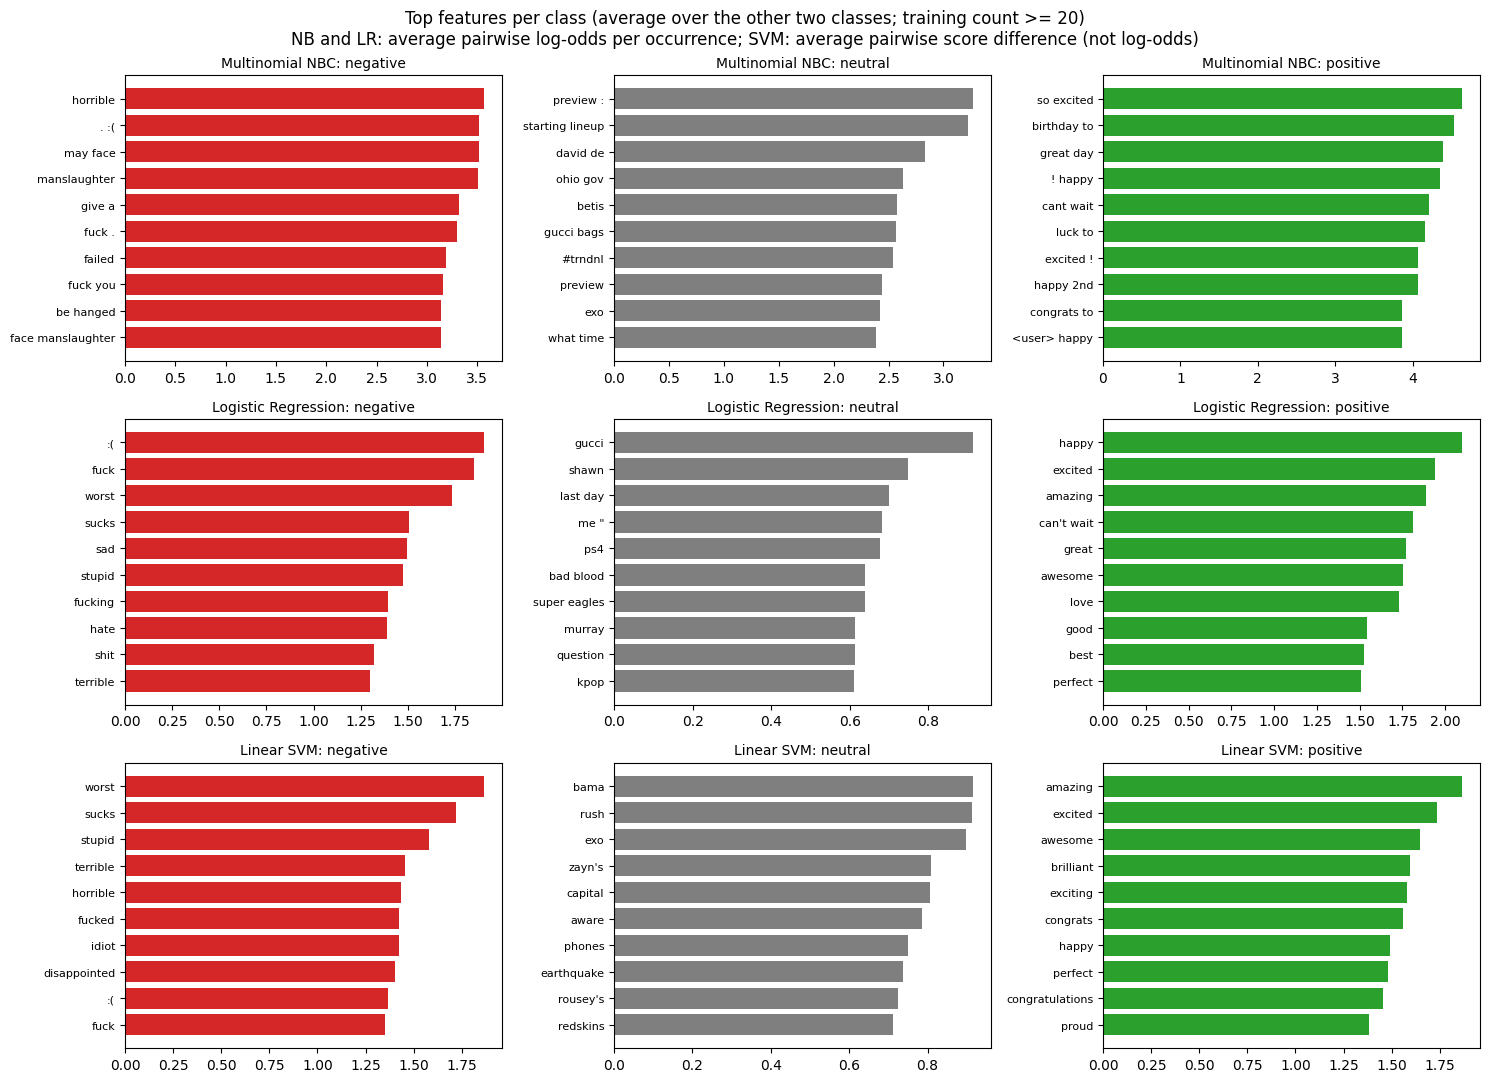


Top 15 features per class. Score = W[c] - mean of W over the other two classes,
i.e. the average pairwise log-odds change per occurrence (NB, LR) or score change (SVM). Train count >= 20:


negative                                                         neutral                                                      positive                                            
               Multinomial NBC Logistic Regression          Linear SVM         Multinomial NBC   Logistic Regression         Linear SVM      Multinomial NBC Logistic Regression              Linear SVM
Rank                                                                                                                                                                                                    
1              horrible (3.57)            :( (1.9)        worst (1.87)        preview : (3.27)          gucci (0.91)        bama (0.92)    so excited (4.64)         happy (2.1)          amazing (1.87)
2                  . :( (3.52)         fuck (1.85)        sucks (1.72)  starting lineup (3.22)          shawn (0.75)        rush (0.91)   birthday to (4.54)      excited (1.94)          excited (1.73)
3              may face (3.51)        worst (1.73)       stupid (1.58)         david de (2.83)        last day (0.7)          exo (0.9)     great day (4.39)      amazing (1.89)          awesome (1.65)
4          manslaughter (3.51)        sucks (1.51)     terrible (1.46)         ohio gov (2.63)           me " (0.68)      zayn's (0.81)       ! happy (4.36)   can't wait (1.81)         brilliant (1.6)
5                give a (3.32)           sad (1.5)     horrible (1.44)            betis (2.58)            ps4 (0.68)      capital (0.8)     cant wait (4.21)        great (1.77)         exciting (1.58)
6                 fuck . (3.3)       stupid (1.48)       fucked (1.43)       gucci bags (2.57)      bad blood (0.64)       aware (0.79)       luck to (4.16)      awesome (1.75)         congrats (1.56)
7                failed (3.19)      fucking (1.39)        idiot (1.42)          #trndnl (2.54)   super eagles (0.64)      phones (0.75)     excited ! (4.07)         love (1.73)            happy (1.49)
8              fuck you (3.16)         hate (1.39)  disappointed (1.4)          preview (2.44)         murray (0.61)  earthquake (0.74)     happy 2nd (4.07)         good (1.55)          perfect (1.48)
9             be hanged (3.14)         shit (1.32)           :( (1.37)              exo (2.42)       question (0.61)    rousey's (0.72)   congrats to (3.86)         best (1.53)  congratulations (1.46)
10    face manslaughter (3.14)      terrible (1.3)         fuck (1.35)        what time (2.39)           kpop (0.61)    redskins (0.71)  <user> happy (3.86)      perfect (1.51)            proud (1.38)
11             3rd world (3.1)        worse (1.27)        sadly (1.33)             17 , (2.37)           kane (0.61)     clemson (0.71)   cannot wait (3.67)          fun (1.49)            great (1.36)
12                hanged (3.1)         bitch (1.2)       ruined (1.31)            top20 (2.32)           yakub (0.6)       ground (0.7)    excited to (3.66)         nice (1.46)        fantastic (1.34)
13               i hate (3.07)          ass (1.13)        worse (1.29)         top20 of (2.32)  this saturday (0.58)       gucci (0.69)    pretty good (3.6)           :) (1.39)           pumped (1.34)
14            the worst (3.06)      erdogan (1.12)         suck (1.26)       ' appeared (2.32)       anderson (0.58)     reports (0.69)    i'm excited (3.6)    beautiful (1.34)           lovely (1.33)
15               . fuck (3.01)    the worst (1.12)     bullshit (1.25)        the top20 (2.32)        nirvana (0.58)     richard (0.69)  <user> great (3.56)  interesting (1.25)             glad (1.31)

Bigrams in top-50 lists and overlap between models:


,Class,Multinomial NBC bigrams in top 50,Logistic Regression bigrams in top 50,Linear SVM bigrams in top 50,Overlap Multinomial NBC & Logistic Regression,Overlap Multinomial NBC & Linear SVM,Overlap Logistic Regression & Linear SVM
0,negative,20,2,0,19,21,32
1,neutral,36,21,0,3,2,12
2,positive,45,3,0,3,5,36


Probe features: score for negative / neutral / positive (average pairwise, same units as above):


,Feature,Multinomial NBC,Logistic Regression,Linear SVM
0,not,+0.86 / -0.11 / -0.75,+0.88 / -0.05 / -0.83,+0.37 / -0.02 / -0.35
1,no,+0.76 / -0.08 / -0.68,+0.75 / -0.16 / -0.59,+0.37 / -0.11 / -0.26
2,never,+0.76 / -0.28 / -0.48,+0.66 / -0.18 / -0.47,+0.37 / -0.05 / -0.33
3,don't,+0.94 / -0.43 / -0.51,+0.95 / -0.22 / -0.73,+0.54 / -0.15 / -0.39
4,can't,+0.60 / -1.20 / +0.61,+0.90 / -0.53 / -0.37,+0.46 / -0.53 / +0.07
5,but,+0.41 / -0.10 / -0.31,-0.02 / +0.21 / -0.19,-0.08 / +0.20 / -0.12
6,!,-0.64 / -0.51 / +1.15,-0.27 / -0.39 / +0.66,-0.05 / -0.19 / +0.24
7,?,+0.15 / +0.33 / -0.48,+0.16 / +0.25 / -0.40,+0.03 / +0.13 / -0.16
8,<user>,-0.09 / +0.04 / +0.05,-0.14 / +0.10 / +0.04,-0.02 / +0.04 / -0.02
9,<url>,+0.40 / +0.21 / -0.62,+0.22 / -0.09 / -0.13,+0.14 / -0.04 / -0.10


NB vs LR on the same vocabulary: strength of word evidence and class bias


,Class,NBC mean |avg pairwise log-odds per occurrence|,LR mean |avg pairwise log-odds per occurrence|,NBC / LR strength ratio,Spearman rank correlation NB vs LR,"NBC class bias (log prior, centred)","LR class bias (intercept, centred)",LR regularisation C
0,negative,0.675,0.143,4.710,0.706,-0.664,-0.654,0.1
1,neutral,0.491,0.144,3.413,0.650,0.406,0.740,0.1
2,positive,0.607,0.156,3.887,0.664,0.259,-0.086,0.1


Overlapping unigram + bigram evidence for short phrases (log-odds of negative vs positive):


,Phrase,Method,Feature contributions to log-odds(negative vs positive),Prior/intercept part,Total log-odds (negative vs positive),P(negative),P(positive)
0,not good,Multinomial NBC,"not good +2.80, good -1.17, not +1.07",-0.923,1.770,0.821,0.140
1,not good,Logistic Regression,"good -1.32, not +1.14, not good +0.60",-0.567,-0.140,0.329,0.378
2,not bad,Multinomial NBC,"not bad -2.19, bad +1.16, not +1.07",-0.923,-0.887,0.275,0.666
3,not bad,Logistic Regression,"not +1.14, bad +1.05, not bad -0.54",-0.567,1.085,0.457,0.155
4,don't like,Multinomial NBC,"don't like +2.46, don't +0.97, like +0.42",-0.923,2.924,0.774,0.042
5,don't like,Logistic Regression,"don't +1.12, don't like +0.35, like +0.05",-0.567,0.955,0.346,0.133


In [ ]:
# Step 51. Model interpretation: which features drive each class, how strongly, and how each score is defined
from scipy.stats import spearmanr
from scipy.special import logsumexp

assert sha256_file(plan_path) == EVALUATION_PLAN_SHA256, "Evaluation plan changed after freezing."
MIN_TRAIN_COUNT = 20   # ignore very rare features so the lists reflect stable patterns
TOP_K = 15


COUNT_FEATURES = all(selected["models"][m]["feature_configuration"].startswith("count_") for m in METHOD_IDS)
UNIT = "per occurrence" if COUNT_FEATURES else "per unit of feature value"

def weight_matrix(m):
    """Per-class weights: NB log P(w|c) (feature_log_prob_), LR and SVM coefficient rows w_c."""
    clf = bundles[m]["classifier"]
    return np.asarray(clf.feature_log_prob_ if m == "multinomial_nb" else clf.coef_, dtype=float)

def average_pairwise_log_odds(m):
    """Score of feature j for class c = W[c, j] - mean_{k != c} W[k, j] = mean_{k != c} (W[c, j] - W[k, j])."""

    W = weight_matrix(m)
    return np.vstack([W[c] - np.delete(W, c, axis=0).mean(axis=0) for c in CLASS_LABELS])

SCORE_UNITS = {"multinomial_nb": f"avg pairwise log-odds {UNIT}",
               "logistic_regression": f"avg pairwise log-odds {UNIT}",
               "linear_svm": f"avg pairwise score difference {UNIT} (not log-odds)"}

# 1) Numerical checks that the definitions above hold for the fitted models on the test matrices.
nb_clf = bundles["multinomial_nb"]["classifier"]
lr_clf = bundles["logistic_regression"]["classifier"]
X_nb, X_lr = X_test["multinomial_nb"], X_test["logistic_regression"]

# NB posterior from Bayes' theorem: joint = prior x likelihood, then normalise over the three classes.
log_joint = nb_clf.class_log_prior_[None, :] + np.asarray(X_nb @ nb_clf.feature_log_prob_.T)
manual_posterior = np.exp(log_joint - logsumexp(log_joint, axis=1, keepdims=True))
np.testing.assert_allclose(manual_posterior, nb_clf.predict_proba(X_nb), rtol=0, atol=1e-9)

# Pairwise log-odds identities for NB (prior + weighted word evidence) and LR (weight and intercept differences).
nb_log_post = nb_clf.predict_log_proba(X_nb)
lr_log_post = lr_clf.predict_log_proba(X_lr)
lr_logits = np.asarray(X_lr @ lr_clf.coef_.T) + lr_clf.intercept_[None, :]
for c in CLASS_LABELS:
    for k in CLASS_LABELS:
        if c == k:
            continue
        nb_formula = (nb_clf.class_log_prior_[c] - nb_clf.class_log_prior_[k]) + \
                     np.asarray(X_nb @ (nb_clf.feature_log_prob_[c] - nb_clf.feature_log_prob_[k])).ravel()
        np.testing.assert_allclose(nb_log_post[:, c] - nb_log_post[:, k], nb_formula, rtol=0, atol=1e-8)
        np.testing.assert_allclose(lr_log_post[:, c] - lr_log_post[:, k], lr_logits[:, c] - lr_logits[:, k],
                                   rtol=0, atol=1e-8)
print("Checks passed on all 12,284 test records:")
print("  NB posterior = normalised prior x likelihood (Bayes' theorem);")
print("  NB and LR pairwise log-odds equal the linear formulas used to interpret the weights.")

train_counts, scores_cvr = {}, {}
for m in METHOD_IDS:
    feature = selected["models"][m]["feature_configuration"]
    X_train_m = sp.load_npz(A_DIR / "features" / feature / "X_train.npz")
    assert X_train_m.shape[1] == len(feature_names[m])
    train_counts[m] = np.asarray(X_train_m.sum(axis=0)).ravel()
    scores_cvr[m] = average_pairwise_log_odds(m)
np.testing.assert_allclose(train_counts["multinomial_nb"], nb_clf.feature_count_.sum(axis=0))

# 2) Top features per class per model.
top_rows = []
for m in METHOD_IDS:
    eligible = train_counts[m] >= MIN_TRAIN_COUNT
    for c in CLASS_LABELS:
        s = np.where(eligible, scores_cvr[m][c], -np.inf)
        for rank, j in enumerate(np.argsort(s)[::-1][:TOP_K], 1):
            top_rows.append({"Method": METHOD_NAMES[m], "Class": CLASS_NAMES[c], "Rank": rank,
                             "Feature": feature_names[m][j], "Score": float(scores_cvr[m][c, j]),
                             "Score unit": SCORE_UNITS[m],
                             "Train count": int(train_counts[m][j]), "Bigram": " " in feature_names[m][j]})
top_features = pd.DataFrame(top_rows)
top_features.to_csv(C_DIR / "tables" / "c33_top_features_by_class.csv", index=False, encoding="utf-8-sig")
top_wide = top_features.assign(Cell=top_features["Feature"] + " (" + top_features["Score"].round(2).astype(str) + ")") \
    .pivot(index="Rank", columns=["Class", "Method"], values="Cell")
top_wide = top_wide.reindex(columns=pd.MultiIndex.from_product([CLASS_NAMES, method_order]))

# 3) Bigram share and overlap of the top-50 features between models.
def top_set(m, c, k=50):
    s = np.where(train_counts[m] >= MIN_TRAIN_COUNT, scores_cvr[m][c], -np.inf)
    return set(feature_names[m][np.argsort(s)[::-1][:k]])
structure_rows = []
for c in CLASS_LABELS:
    sets = {m: top_set(m, c) for m in METHOD_IDS}
    row = {"Class": CLASS_NAMES[c]}
    for m in METHOD_IDS:
        row[f"{METHOD_NAMES[m]} bigrams in top 50"] = sum(" " in f for f in sets[m])
    for a, b in [("multinomial_nb", "logistic_regression"), ("multinomial_nb", "linear_svm"),
                 ("logistic_regression", "linear_svm")]:
        row[f"Overlap {METHOD_NAMES[a]} & {METHOD_NAMES[b]}"] = len(sets[a] & sets[b])
    structure_rows.append(row)
top_structure = pd.DataFrame(structure_rows)
top_structure.to_csv(C_DIR / "tables" / "c34_top_feature_structure.csv", index=False)

# 4) Probe features linked to the error analysis (negation, contrast, punctuation, masks, sentiment words).
PROBES = ["not", "no", "never", "don't", "can't", "but", "!", "?", "<user>", "<url>",
          "good", "bad", "happy", "love", "great", "thanks", "hate",
          "not good", "not bad", "don't like", "monday", "trump"]
probe_rows = []
for token in PROBES:
    row = {"Feature": token}
    for m in METHOD_IDS:
        vocab = bundles[m]["vectorizer"].vocabulary_
        if token in vocab:
            j = vocab[token]
            row[METHOD_NAMES[m]] = " / ".join(f"{v:+.2f}" for v in scores_cvr[m][:, j])
        else:
            row[METHOD_NAMES[m]] = "not in vocabulary"
    probe_rows.append(row)
probe_table = pd.DataFrame(probe_rows)
probe_table.to_csv(C_DIR / "tables" / "c35_probe_feature_scores.csv", index=False, encoding="utf-8-sig")

# 5) NB vs LR share the same vectorizer: compare evidence strength per word and the class bias.

strength_rows = []
same_vocab = np.array_equal(feature_names["multinomial_nb"], feature_names["logistic_regression"])
if same_vocab:
    eligible = train_counts["multinomial_nb"] >= MIN_TRAIN_COUNT
    nb_bias = nb_clf.class_log_prior_ - nb_clf.class_log_prior_.mean()
    lr_bias = lr_clf.intercept_ - lr_clf.intercept_.mean()
    for c in CLASS_LABELS:
        nb_s, lr_s = scores_cvr["multinomial_nb"][c, eligible], scores_cvr["logistic_regression"][c, eligible]
        strength_rows.append({
            "Class": CLASS_NAMES[c],
            f"NBC mean |avg pairwise log-odds {UNIT}|": float(np.mean(np.abs(nb_s))),
            f"LR mean |avg pairwise log-odds {UNIT}|": float(np.mean(np.abs(lr_s))),
            "NBC / LR strength ratio": float(np.mean(np.abs(nb_s)) / np.mean(np.abs(lr_s))),
            "Spearman rank correlation NB vs LR": float(spearmanr(nb_s, lr_s).correlation),
            "NBC class bias (log prior, centred)": float(nb_bias[c]),
            "LR class bias (intercept, centred)": float(lr_bias[c]),
            "LR regularisation C": float(lr_clf.C),
        })
evidence_strength = pd.DataFrame(strength_rows)
evidence_strength.to_csv(C_DIR / "tables" / "c36_nb_vs_lr_evidence_strength.csv", index=False)

# 6) Overlapping evidence: how one phrase is scored when unigrams and the bigram are all features.

PHRASES = ["not good", "not bad", "don't like"]
overlap_rows = []
for phrase in PHRASES:
    for m in ["multinomial_nb", "logistic_regression"]:
        vec = bundles[m]["vectorizer"]
        x = vec.transform([phrase]).tocsr()
        W = weight_matrix(m)
        parts = {feature_names[m][j]: float(x[0, j] * (W[0, j] - W[2, j])) for j in x.indices}
        bias = (nb_clf.class_log_prior_ if m == "multinomial_nb" else lr_clf.intercept_)
        total = sum(parts.values()) + float(bias[0] - bias[2])
        log_post = bundles[m]["classifier"].predict_log_proba(x)[0]
        np.testing.assert_allclose(total, log_post[0] - log_post[2], rtol=0, atol=1e-8)
        overlap_rows.append({
            "Phrase": phrase, "Method": METHOD_NAMES[m],
            "Feature contributions to log-odds(negative vs positive)":
                ", ".join(f"{k} {v:+.2f}" for k, v in sorted(parts.items(), key=lambda kv: -abs(kv[1]))),
            "Prior/intercept part": float(bias[0] - bias[2]),
            "Total log-odds (negative vs positive)": total,
            "P(negative)": float(np.exp(log_post[0])), "P(positive)": float(np.exp(log_post[2])),
        })
overlap_evidence = pd.DataFrame(overlap_rows)
overlap_evidence.to_csv(C_DIR / "tables" / "c37_overlapping_ngram_evidence.csv", index=False, encoding="utf-8-sig")

# 7) Figure: top 10 features per class for each model.
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for r, m in enumerate(METHOD_IDS):
    for c in CLASS_LABELS:
        sub = top_features[(top_features["Method"] == METHOD_NAMES[m]) &
                           (top_features["Class"] == CLASS_NAMES[c])].head(10).iloc[::-1]
        axes[r, c].barh(sub["Feature"], sub["Score"], color=["#d62728", "#7f7f7f", "#2ca02c"][c])
        axes[r, c].set_title(f"{METHOD_NAMES[m]}: {CLASS_NAMES[c]}", fontsize=10)
        axes[r, c].tick_params(axis="y", labelsize=8)
fig.suptitle(f"Top features per class (average over the other two classes; training count >= {MIN_TRAIN_COUNT})\n"
             f"NB and LR: average pairwise log-odds {UNIT}; SVM: average pairwise score difference (not log-odds)")
fig.tight_layout()
fig.savefig(C_DIR / "figures" / "c_fig7_top_features.png", dpi=170, bbox_inches="tight")
plt.show()

print(f"\nTop {TOP_K} features per class. Score = W[c] - mean of W over the other two classes,")
print(f"i.e. the average pairwise log-odds change {UNIT} (NB, LR) or score change (SVM). Train count >= {MIN_TRAIN_COUNT}:")
with pd.option_context("display.max_columns", 12, "display.width", 250, "display.max_colwidth", 30):
    display(top_wide)
print("Bigrams in top-50 lists and overlap between models:")
display(top_structure)
print("Probe features: score for negative / neutral / positive (average pairwise, same units as above):")
display(probe_table)
print("NB vs LR on the same vocabulary: strength of word evidence and class bias")
display(evidence_strength.round(3))
print("Overlapping unigram + bigram evidence for short phrases (log-odds of negative vs positive):")
with pd.option_context("display.max_colwidth", 120, "display.width", 250):
    display(overlap_evidence.round(3))

## 52. Final Integrity Check and Results Package
Confirm that the evaluation plan and the three models are unchanged, save a summary of the key numbers and package all results into one ZIP.

In [ ]:
# Step 52. Final integrity check, key-number summary (c_summary.json) and results ZIP
import platform

# 1) The models and the evaluation plan must be exactly what was frozen before testing.
assert sha256_file(plan_path) == EVALUATION_PLAN_SHA256, "Evaluation plan changed."
for m in METHOD_IDS:
    assert sha256_file(B_HANDOFF / selected["models"][m]["bundle_file"]) == \
        evaluation_plan["models_under_test"][m]["bundle_sha256"], f"{m} bundle changed."
assert len(y_test) == 12284 and all(len(p) == len(y_test) for p in test_predictions.values())

def records(df, keep_index=False):
    out = df.reset_index() if keep_index else df.copy()
    out.columns = [" | ".join(map(str, c)).strip(" |") if isinstance(c, tuple) else str(c) for c in out.columns]
    return json.loads(out.to_json(orient="records", double_precision=6, force_ascii=False))

best = test_results.iloc[:-1].sort_values("Macro Recall", ascending=False).iloc[0]
cat = category_counts.set_index("Category")["Records"]
nb_row = marginal_summary.set_index("Method").loc["Multinomial NBC"]

summary = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "group_c_started_utc": C_STARTED_UTC,
    "inputs": {
        "dataset": "cardiffnlp/tweet_eval (sentiment)", "dataset_revision": a_meta["revision"],
        "group_a_prepared_dir": str(A_DIR), "group_b_zip": str(B_ZIP),
        "group_b_zip_sha256": sha256_file(B_ZIP), "group_b_manifest_files_verified": len(manifest),
    },
    "evaluation_plan": {"file": plan_path.name, "sha256": EVALUATION_PLAN_SHA256,
                        "frozen_utc": evaluation_plan["frozen_utc"],
                        "deviation": "None: every analysis listed in the frozen plan is reported, including the "
                                     "exact McNemar tests with Holm correction (c13_mcnemar_tests.csv).",
                        "additions_after_plan_freeze": [
                            "Signed margin s_true - max_other per record (C9, c18b); a descriptive check that a "
                            "negative margin equals a misclassification. Not used to select or change anything.",
                            "Manual review notes for the 36 selected error cases (C10, c27/c27b).",
                            "Written labelling rules for the frozen hand-written sentences (C11); labels unchanged.",
                            "Numerical checks of Bayes' theorem and the pairwise log-odds identities, and the "
                            "overlapping n-gram evidence table (C12, c37).",
                        ]},
    "integrity": {
        "models_unchanged_since_plan": True, "test_records_evaluated": int(len(y_test)),
        "class_order": CLASS_LABELS, "all_records_retained": True,
        "all_zero_rows": {METHOD_NAMES[m]: int((X_test[m].getnnz(axis=1) == 0).sum()) for m in METHOD_IDS},
        "validation_predictions_reproduced": True,
        "nb_posterior_equals_bayes_rule": True,
        "negative_signed_margin_equals_error": True,
    },
    "key_numbers": {
        "best_method_by_test_macro_recall": best["Method"],
        "best_test_macro_recall": float(best["Macro Recall"]),
        "baseline_test_macro_recall": float(test_results.iloc[-1]["Macro Recall"]),
        "all_three_agree_pct": float(100 * agree_all.mean()),
        "all_three_wrong_records": int(all_wrong.sum()),
        "at_least_one_correct_pct": float(100 * any_right.mean()),
        "nbc_right_lr_svm_miss_negative": int(cat["B1 NBC right, LR & SVM miss a negative"]),
        "lr_svm_right_nbc_neutral_to_negative": int(cat["B2 LR & SVM right, NBC: neutral -> negative"]),
        "nbc_confident_errors_ge_0_9": int(nb_row["Confident errors (max prob >= 0.9) n"]),
        "nbc_confident_errors_pct_of_errors": float(nb_row["Confident errors % of errors"]),
    },
    "validation_reference": records(validation_reference),
    "class_distribution": records(class_mix, keep_index=True),
    "test_results": records(test_results),
    "validation_vs_test": records(generalisation_gap),
    "gain_over_baseline": records(improvement),
    "predicted_class_proportions": records(proportion, keep_index=True),
    "per_class_metrics": records(per_class),
    "bootstrap_ci": records(bootstrap_ci),
    "paired_bootstrap_differences": records(paired_differences),
    "mcnemar_tests_holm": records(mcnemar_tests),
    "prediction_timing": records(timing),
    "slice_summary": records(slice_table, keep_index=True),
    "slice_negative_recall": records(negrecall_wide, keep_index=True),
    "slice_pred_neutral_pct": records(neutral_wide, keep_index=True),
    "marginal_summary": records(marginal_summary),
    "signed_margin_summary": records(signed_margin_summary),
    "marginal_error_by_decile": records(marginal_deciles, keep_index=True),
    "marginal_overlap": records(marginal_overlap),
    "marginal_slice_lift": records(marginal_lift, keep_index=True),
    "all_zero_vector_rule": records(zero_vector_check),
    "error_category_counts": records(category_counts),
    "draft_reason_frequency_all_wrong": records(reason_counts),
    "manual_review": {"status": review_status, "reviewed_cases": int(len(reviewed)),
                      "selected_cases": int(len(error_cases)), "missing_notes": missing_notes,
                      "cause_by_label_check": records(review_summary, keep_index=True)},
    "supplementary_hand_written_accuracy": records(by_category, keep_index=True),
    "supplementary_minimal_pairs": records(minimal_pairs),
    "supplementary_label_rules": {"general": LABEL_GUIDELINE, "by_category": LABEL_RULES},
    "supplementary_word_order_check": records(word_order_check),
    "top_feature_structure": records(top_structure),
    "probe_feature_scores": records(probe_table),
    "nb_vs_lr_evidence_strength": records(evidence_strength),
    "overlapping_ngram_evidence": records(overlap_evidence),
    "interpretation_score_definition": "W[c] - mean of W over the other classes = average pairwise log-odds "
                                       f"change {UNIT} (NB, LR); average pairwise score difference (SVM).",
    "environment": {"python": platform.python_version(),
                    "packages": {n: importlib.metadata.version(n) for n in
                                 ["numpy", "scipy", "scikit-learn", "joblib", "pandas", "matplotlib"]}},
}
summary_path = C_DIR / "c_summary.json"
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")

# 2) README describing the outputs.
readme_c = f"""GROUP C: FINAL TEST EVALUATION AND ERROR ANALYSIS
TweetEval sentiment, official test split (12,284 records), class order [0 negative, 1 neutral, 2 positive].
Models: Group B's three fixed pipelines (Multinomial NBC, Logistic Regression, Linear SVM); no retraining.
Evaluation plan frozen before testing: c_evaluation_plan.json (SHA-256 {EVALUATION_PLAN_SHA256}).
Every analysis in the plan is reported, including exact McNemar tests with Holm correction.
Added after the plan was frozen (descriptive only, nothing re-selected): signed margins (c18b), manual review of
the 36 selected error cases (c27, c27b; status: {review_status}), labelling rules for the hand-written sentences,
and numerical checks of the NB/LR log-odds formulas (c37).

c_summary.json   All key numbers in one file (results, CIs, paired differences, slices, marginal cases, error categories).
tables/          c00-c13: validation reference, alignment, test results, per-class metrics, confusion
                 matrices, bootstrap CIs, paired bootstrap differences, McNemar tests, timing, predictions;
                 c33-c37: model interpretation (top features as average pairwise log-odds, probe words,
                 NB vs LR evidence strength, overlapping n-gram evidence).
figures/         c_fig1-c_fig7: confusion matrices, metrics vs baseline, per-class recall,
                 validation vs test, error rate by slice, error by margin decile, top features.
errors/          c14-c29: slice analysis (one row per record set), marginal cases and signed margins,
                 all misclassified records with evidence words, draft reasons and manual review notes,
                 error case table with label checks and reviewed causes, label conflicts.
supplementary/   c30-c32b: hand-written hard sentences (frozen before prediction) with their labelling rules
                 (c_hand_written_label_rules.json). Reported separately; NOT part of the official test metrics.
manifest_sha256.json   SHA-256 of every file in this package.

Rules applied: models, vectorizers and settings fixed; transform() only; all test records retained,
including all-zero vectors, duplicates and conflicting labels; test results not used for any selection.
"""
(C_DIR / "README_GroupC.txt").write_text(readme_c, encoding="utf-8")


def package_files():
    return sorted(p for p in C_DIR.rglob("*") if p.is_file()
                  and "b_handoff" not in p.relative_to(C_DIR).parts and "__pycache__" not in p.parts
                  and p.name != "manifest_sha256.json")

for required in ["tables/c13_mcnemar_tests.csv", "errors/c18b_signed_margin_summary.csv",
                 "errors/c27b_manual_review_summary.csv", "tables/c37_overlapping_ngram_evidence.csv",
                 "supplementary/c_hand_written_label_rules.json"]:
    assert (C_DIR / required).exists(), f"Missing {required}: rerun Steps 46-51 in order before Step 52."
c_manifest = {str(p.relative_to(C_DIR)): sha256_file(p) for p in package_files()}
(C_DIR / "manifest_sha256.json").write_text(json.dumps(c_manifest, indent=2), encoding="utf-8")

C_ZIP = BASE / "TweetEval_GroupC_Evaluation_Results.zip"
with zipfile.ZipFile(C_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in package_files() + [C_DIR / "manifest_sha256.json"]:
        archive.write(path, path.relative_to(C_DIR))
with zipfile.ZipFile(C_ZIP) as archive:
    assert archive.testzip() is None
    assert len(archive.namelist()) == len(c_manifest) + 1

folder_counts = pd.Series([Path(k).parts[0] if len(Path(k).parts) > 1 else "(root)" for k in c_manifest]).value_counts()
print("Integrity: evaluation plan and all three model bundles unchanged since the plan was frozen.")
print(f"Summary file : {summary_path}")
print(f"Results ZIP  : {C_ZIP}  ({C_ZIP.stat().st_size / 1e6:.2f} MB, {len(c_manifest) + 1} files)")
print(f"ZIP SHA-256  : {sha256_file(C_ZIP)}")
print("Files per folder:")
display(folder_counts.rename("files").to_frame())
print("Manual review status:", review_status)
if not REVIEWED_BY.strip():
    print("Reminder: set REVIEWED_BY in Step 49 after the group has confirmed the reviewer notes, then rerun Steps 49-52.")
print("\nKey numbers:")
for key, value in summary["key_numbers"].items():
    print(f"  {key}: {round(value, 4) if isinstance(value, float) else value}")

try:
    from google.colab import files
    files.download(str(C_ZIP))
except Exception:
    print("Download the ZIP from Google Drive:", C_ZIP)

Integrity: evaluation plan and all three model bundles unchanged since the plan was frozen.
Summary file : /content/drive/MyDrive/CSCI323/TweetEval_GroupC_Evaluation/c_summary.json
Results ZIP  : /content/drive/MyDrive/CSCI323/TweetEval_GroupC_Evaluation_Results.zip  (2.59 MB, 63 files)
ZIP SHA-256  : 2ad317842ca738b9ca55b5e07fa680e36e8c14886cd738eeeb98451a81992ce5
Files per folder:


,files
tables,26
errors,19
figures,7
supplementary,7
(root),3


Manual review status: confirmed by Zixi，Jingming

Key numbers:
  best_method_by_test_macro_recall: Multinomial NBC
  best_test_macro_recall: 0.6072
  baseline_test_macro_recall: 0.3333
  all_three_agree_pct: 57.5871
  all_three_wrong_records: 2617
  at_least_one_correct_pct: 78.6959
  nbc_right_lr_svm_miss_negative: 834
  lr_svm_right_nbc_neutral_to_negative: 817
  nbc_confident_errors_ge_0_9: 2084
  nbc_confident_errors_pct_of_errors: 42.289


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>